# NYC Yellow Taxi 2015–2016 — Time Series Forecasting

Using the feature matrix built in the feature-engineering notebook (`02_feature_engineering.ipynb`), I forecast the hourly city-wide trip count. The main question was how well we can forecast the 24 hours of a day one day ahead (at 00:00 each day). I compared four model families on the same problem: a seasonal baseline, tree-based models (LightGBM, XGBoost), an LSTM and a pretrained foundation model (Chronos-2, first zero-shot, then fine-tuned).

I made all model and hyperparameter choices only inside the training period, in two separate halves. I ran the test period (second half of 2016) once, after everything was frozen. Everything I did after the test sits in separate sections and outside the headline numbers.

The notebook works from saved forecasts. The baseline and LightGBM are recomputed in this notebook and compared with the saved forecasts; the LSTM and Chronos forecasts are read from disk (they are regenerated when `RECOMPUTE = True`). Every decision is preceded by a table or chart, computed in this notebook, that supports it.

## 0. Summary

- **Metric:** hourly city-wide trip count. Its seasonality is strong; even a simple seasonal forecast cuts the error of a constant mean by 72%. Its business meaning is also the clearest. Revenue moves closely with the trip count; forecasting revenue directly made no practically meaningful difference compared with multiplying the trip forecast by revenue per trip (Section 14).
- **Horizon:** the main horizon is 24 hours (day-ahead). In addition, 168 hours (weekly), the 15 busiest zones, and 1 hour as a reference.
- **Test result (24 h, WAPE %):** baseline 7.73 · LightGBM 5.95 · LSTM (5 seeds) 5.94 · Chronos-2 zero-shot 5.69. All three models beat the baseline; the differences between them were not statistically distinguishable.
- **Fine-tune:** the first seed was 0.08 points better than zero-shot on the test, and this difference is statistically distinguishable. The second seed was not distinguishable from zero-shot. Because the 0.11-point difference between the two seeds is larger than the gain, and the gain stayed below the 0.3-point practical threshold I set in advance, I did not find fine-tuning worth its extra cost; the main row uses zero-shot.
- **Where the error is:** mostly on holidays and the days after them, and in quiet night hours. The baseline struggled with the level drop at the end of 2016; the models' monthly bias stayed small.
- **Business recommendation:** LightGBM. It is the cheapest of the three models that could not be distinguished (seconds); at 168 hours and 1 hour no row was worse than it (Chronos trails it, as a tendency), and I built the zone forecast with the same family. LightGBM's lead in this scope partly comes from the design: I did not run the LSTM or the fine-tune at these horizons. I built the LSTM as a day-ahead model that outputs 24 hours at 00:00 each day; 168 hours and 1 hour would each have required a separate model with its own window and seed search. I did not carry the fine-tune to the other horizons because it was not worth it against zero-shot at the main 24-hour horizon.

### Contents

| Topic | Section |
|---|---|
| 1) Metric choice, horizon and frequency | 3 |
| 2) Time-based split and why | 4 |
| 3) Tree-based models, lag and time features | 6 |
| 4) LSTM: sequence format, window, architecture | 7 |
| 5) Foundation model: zero-shot and fine-tune | 8 |
| 6) Error metrics and comparison of all models | 4, 9 |
| 7) Forecast and actual on the same chart, where the error is | 10 |
| 8) Business perspective | 11 |
| Overall assessment: five key questions | 12 |
| Findings and next steps | 13 |
| Additional analyses | 14 |

### Checklist

A list I drew up when I started and extended as I went. Each item is answered in the section given, with a table or chart computed in this notebook.

| # | Item | Section |
|---|---|---|
| 1 | Measure candidate metrics: seasonality strength, simple forecast error, independent information | 3 |
| 2 | Choose the horizon from the data (ACF, error as the horizon grows) | 3 |
| 3 | Separate events: holidays, DST transitions, snowstorms; write down in advance which ones are excluded from the score | 2, 4 |
| 4 | Time-based split; show the leakage of a random split | 4 |
| 5 | Choose a strong baseline; measure the sensitivity of its hyperparameters and the selection bias | 5 |
| 6 | Decide each model by a rule written in advance; test differences with a block bootstrap | 4–8 |
| 7 | LightGBM: lags from the ACF, feature groups by ablation | 6 |
| 8 | LSTM: grid search over window and hidden units, seed stability | 7 |
| 9 | Chronos: context length, covariates, input form; threshold for whether fine-tuning is worth it set in advance | 8 |
| 10 | Run the test once; save the forecasts with SHA-256 | 1, 9 |
| 11 | Compare all models in one table and by situation (day type, hour, horizon) | 9 |
| 12 | Forecast vs actual charts, residual analysis, prediction interval | 9, 10 |
| 13 | Business recommendation, cost, production risks and monitoring threshold | 11 |
| 14 | Keep ideas tried after the test separate | 14 |

## 1. Setup and reproducibility

I ran the heavy computations (model selection, LSTM and Chronos training, the single test run) in a separate computation notebook and saved the results under `artifacts/task5/`: selection-period evidence in `selection/`, test forecasts in `test/`, descriptive analyses done after the test in `post_test/`. The SHA-256 digest of every file is in `manifest.json`. Re-running the notebook needs three things: opening it from the `notebooks/` folder under the project root, the feature matrix (`data/processed/feature_matrix/`, 277 million rows), and the `artifacts/task5/` package. Without these the notebook is read-only; the outputs are saved. The LSTM and Chronos packages are needed only when `RECOMPUTE = True`.

The first cell compares library versions with the recorded versions. I put this check first because results can change when the LightGBM or torch version changes.

In [1]:
# B1.1 setup: libraries, folders, plot style, package versions against the manifest
import hashlib
import importlib.metadata as md
import json
import platform
import time
from pathlib import Path

import duckdb
import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display
from statsmodels.tsa.stattools import acf

PROJECT_ROOT = Path.cwd().parent
T5 = PROJECT_ROOT / "artifacts" / "task5"
SEL, TEST, POST = T5 / "selection", T5 / "test", T5 / "post_test"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures" / "task5"
RECOMPUTE = False  # True re-creates the LSTM and Chronos test forecasts into artifacts/task5/recompute/ (about 25 min on 4 CPU cores)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
GREY, RED, BLUE, ORANGE, GREEN, PURPLE = "#9a9a96", "#e34948", "#2a78d6", "#eb6834", "#1baf7a", "#8a5cc2"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold"})

manifest = json.loads((T5 / "manifest.json").read_text(encoding="utf-8"))

def installed(package):
    try:
        return md.version(package)
    except md.PackageNotFoundError:
        return "not installed"

versions = pd.DataFrame([{"package": "python", "saved": manifest["python"], "this kernel": platform.python_version()}]
                        + [{"package": p, "saved": v, "this kernel": installed(p)} for p, v in manifest["packages"].items()])
versions["same"] = [s.split("+")[0] == k.split("+")[0] for s, k in zip(versions["saved"], versions["this kernel"])]
versions

,package,saved,this kernel,same
0,python,3.11.9,3.11.9,True
1,numpy,2.4.6,2.4.6,True
2,pandas,3.0.5,3.0.5,True
3,pyarrow,25.0.1,25.0.1,True
4,scipy,1.17.1,1.17.1,True
5,statsmodels,0.15.0,0.15.0,True
6,matplotlib,3.11.2,3.11.2,True
7,lightgbm,4.7.0,4.7.0,True
8,xgboost,3.2.0,3.2.0,True
9,torch,2.14.1+cpu,2.14.1+cpu,True


All versions match the recorded versions. The next cell compares the SHA-256 digest of every file in the package with the value in the manifest; the manifest's own digest is fixed in this cell. The cell stops if even one file differs.

In [2]:
# B1.2 file integrity: every package file against manifest.json, and the manifest against the value pinned here
MANIFEST_SHA256 = "efae83dab3a70d9151f6df65016d260f6cf3d1c8ff304cd4ee96a7ba92650c6a"

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

assert sha256(T5 / "manifest.json") == MANIFEST_SHA256, "manifest.json changed"
rows = [{"folder": p.split("/")[0], "status": v["status"], "identical": sha256(T5 / p) == v["sha256"]} for p, v in manifest["files"].items()]
rows += [{"folder": "data/raw (external)", "status": "current", "identical": sha256(PROJECT_ROOT / p) == s}
         for p, s in manifest["external_inputs"].items()]
integrity = pd.DataFrame(rows)
assert integrity["identical"].all()
integrity.groupby(["folder", "status"]).agg(files=("identical", "size"), identical=("identical", "sum"))

files  identical
folder              status                                
data/raw (external) current                   1          1
post_test           current                  38         38
                    superseded (heyet 7)     10         10
selection           current                  67         67
test                current                  30         30

All files in the package are exactly as they were saved. The "superseded" ones are first outputs from before a review corrected them; they are kept as an audit trail and this notebook does not read them.

## 2. Data: hourly series, events, weather

I recounted the hourly series directly from the feature matrix (277 million rows) with DuckDB and compared it with the series I used in the computation notebook.

In [3]:
# B2.1 hourly trips counted from the Task 2 feature matrix (DuckDB), checked against the stored series
spec = json.loads((PROJECT_ROOT / "artifacts" / "task2" / "feature_list.json").read_text(encoding="utf-8"))
MATRIX = f"read_parquet('{(PROJECT_ROOT / spec['matrix']['path'] / '**' / '*.parquet').as_posix()}', hive_partitioning = true)"
con = duckdb.connect()
for stmt in ["SET memory_limit = '4GB'", "SET threads = 4", "SET enable_progress_bar = false"]:
    con.execute(stmt)
t0 = time.time()
n_rows = con.execute(f"SELECT COUNT(*) FROM {MATRIX}").fetchone()[0]
hourly = con.execute(f"SELECT date_trunc('hour', tpep_pickup_datetime) AS hour_start, COUNT(*) AS trips FROM {MATRIX} GROUP BY 1").df()
assert n_rows == spec["matrix"]["rows"] == manifest["feature_matrix_rows"]

HOURS = pd.date_range("2015-01-01 00:00", "2016-12-31 23:00", freq="h")
FIT_END = pd.Timestamp("2016-07-01")
trips = hourly.set_index("hour_start")["trips"].reindex(HOURS, fill_value=0).astype("int64")
candidates = pd.read_parquet(SEL / "k2_city_candidates.parquet")
assert (trips.to_numpy() == candidates["trips"].to_numpy()).all()
pd.Series({"matrix rows": f"{n_rows:,}", "hours": f"{len(trips):,}", "hours with no trip": int((trips == 0).sum()),
           "mean trips per hour": f"{trips.mean():,.0f}", "min / max": f"{trips.min()} / {trips.max():,}",
           "same as stored series": True, "query time (s)": round(time.time() - t0, 1)}).to_frame("value")

,value
matrix rows,"277,062,314"
hours,"17,544"
hours with no trip,0
mean trips per hour,"15,792"
min / max,"8 / 45,831"
same as stored series,True
query time (s),15.00


All 17,544 hours are present and the series is identical to the saved one. The target comes from the cleaned feature matrix.

The forecast needed non-demand events to be handled separately. I defined the event calendar in code: federal holidays (those with a large and a small effect kept separate), special days (Christmas Eve, New Year's Eve, the days after Thanksgiving and Christmas), DST transition nights and two snowstorms.

In [4]:
# B2.2 calendar of events: major / minor federal holidays, special days, DST nights, snowstorms
fed = holidays.US(years=[2015, 2016])
MAJOR_NAMES = {"New Year's Day", "Memorial Day", "Independence Day", "Independence Day (observed)", "Labor Day",
               "Thanksgiving Day", "Christmas Day"}
major = {pd.Timestamp(d) for d, n in fed.items() if n in MAJOR_NAMES}
minor = {pd.Timestamp(d) for d, n in fed.items() if n not in MAJOR_NAMES}
special = {pd.Timestamp(d) for d in ["2015-12-24", "2015-12-31", "2016-12-24", "2016-12-31"]}
special |= {pd.Timestamp(d) + pd.Timedelta(days=1) for d, n in fed.items() if n in ("Thanksgiving Day", "Christmas Day")}
DST_DAYS = pd.to_datetime(["2015-03-08", "2015-11-01", "2016-03-13", "2016-11-06"])
dst_mask = pd.Series(HOURS.normalize().isin(DST_DAYS) & HOURS.hour.isin([1, 2]), index=HOURS)
storm_mask = pd.Series(((HOURS >= "2015-01-26 12:00") & (HOURS < "2015-01-28 00:00"))
                       | ((HOURS >= "2016-01-23 00:00") & (HOURS < "2016-01-25 00:00")), index=HOURS)
OKY = ~(dst_mask | storm_mask).to_numpy()  # hours that are scored

pd.DataFrame([
    {"event": "major federal holiday", "days": len(major), "examples": "Thanksgiving, Christmas, July 4", "use": "model input (calendar)"},
    {"event": "minor federal holiday", "days": len(minor), "examples": "MLK, Columbus, Veterans", "use": "model input (calendar)"},
    {"event": "special day", "days": len(special), "examples": "Dec 24, Dec 31, day after Thanksgiving", "use": "model input (calendar)"},
    {"event": "DST night, hours 01-02", "days": len(DST_DAYS), "examples": "2016-11-06 01:00 counted twice", "use": "not scored, cleaned in history"},
    {"event": "snowstorm (Juno 2015, Jonas 2016)", "days": 4, "examples": "2016-01-23 travel ban", "use": "not scored, cleaned in history"},
])

,event,days,examples,use
0,major federal holiday,13,"Thanksgiving, Christmas, July 4",model input (calendar)
1,minor federal holiday,9,"MLK, Columbus, Veterans",model input (calendar)
2,special day,8,"Dec 24, Dec 31, day after Thanksgiving",model input (calendar)
3,"DST night, hours 01-02",4,2016-11-06 01:00 counted twice,"not scored, cleaned in history"
4,"snowstorm (Juno 2015, Jonas 2016)",4,2016-01-23 travel ban,"not scored, cleaned in history"


The calendar has 13 major and 9 minor federal holiday days, 8 special days, 4 DST nights and 4 storm days. I gave holidays and special days to the models as calendar inputs; DST and storm hours, on the other hand, I left out of the score and cleaned in the history input. To show why I left DST and storm hours out of the score, I looked at the most extreme hours of the series.

In [5]:
# B2.3 the most extreme hours of the series and what they are
extreme = pd.concat([trips.nsmallest(12).to_frame().assign(kind="lowest"), trips.nlargest(4).to_frame().assign(kind="highest")])
extreme["weekday"] = extreme.index.day_name()
extreme["event"] = np.select([dst_mask[extreme.index].to_numpy(), storm_mask[extreme.index].to_numpy()], ["DST night", "snowstorm"], "-")
extreme

,trips,kind,weekday,event
2016-01-23 20:00:00,8,lowest,Saturday,snowstorm
2016-01-24 01:00:00,9,lowest,Sunday,snowstorm
2016-01-23 21:00:00,10,lowest,Saturday,snowstorm
2016-01-23 22:00:00,11,lowest,Saturday,snowstorm
2016-01-24 02:00:00,13,lowest,Sunday,snowstorm
2016-01-24 03:00:00,13,lowest,Sunday,snowstorm
2015-01-27 03:00:00,14,lowest,Tuesday,snowstorm
2016-01-23 19:00:00,16,lowest,Saturday,snowstorm
2016-01-23 23:00:00,17,lowest,Saturday,snowstorm
2016-01-24 00:00:00,18,lowest,Sunday,snowstorm


The 12 lowest hours are all snowstorm hours: 10 come from the travel ban in January 2016 (8–19 trips), two from the Juno storm in January 2015 (14 and 21 trips). Juno was not in the event list of the earlier notebooks in this project; I added it here. The two highest hours are not demand: on the night DST ends, 01:00 is counted twice. I removed the storm hours and the hours of the DST fall-back night from the score and cleaned them in the models' history input (Section 5). I kept them separate because no model could know these events in advance.

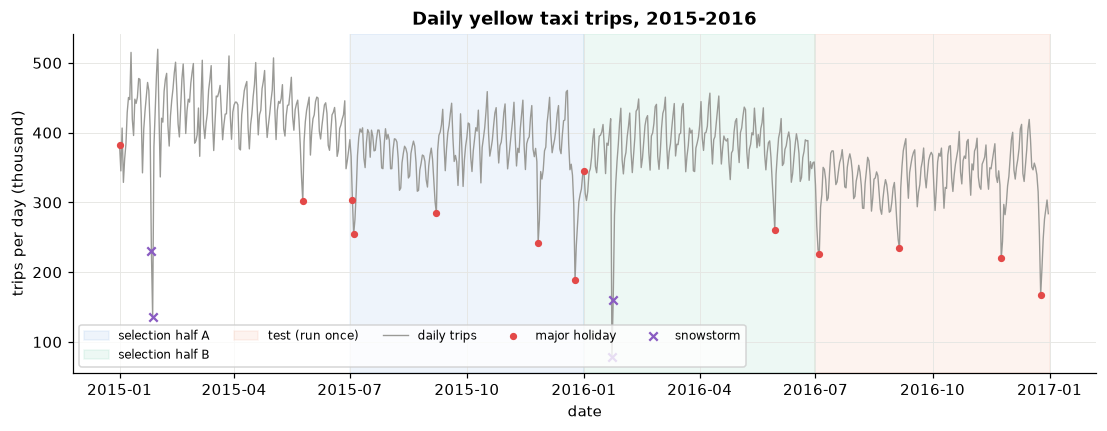

In [6]:
# B2.4 daily trips with the selection halves, the test period and the event days
daily = trips.resample("D").sum()
fig, ax = plt.subplots(figsize=(12, 4))
for (a, b), lab, col in [(("2015-07-01", "2016-01-01"), "selection half A", BLUE), (("2016-01-01", "2016-07-01"), "selection half B", GREEN),
                         (("2016-07-01", "2017-01-01"), "test (run once)", ORANGE)]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=col, alpha=0.08, label=lab)
ax.plot(daily.index, daily / 1000, color=GREY, lw=0.9, label="daily trips")
md_ = sorted(d for d in major if d in daily.index)
ax.scatter(md_, daily[md_] / 1000, color=RED, s=14, zorder=3, label="major holiday")
storm_days = pd.to_datetime(["2015-01-26", "2015-01-27", "2016-01-23", "2016-01-24"])
ax.scatter(storm_days, daily[storm_days] / 1000, color=PURPLE, marker="x", s=30, zorder=3, label="snowstorm")
ax.set_title("Daily yellow taxi trips, 2015-2016")
ax.set_xlabel("date")
ax.set_ylabel("trips per day (thousand)")
ax.legend(loc="lower left", ncol=5, fontsize=8)
plt.show()

Three things stand out in the chart: the weekly cycle, the level drop that continues through 2016, and the sharp drops on holidays. The first half of 2016 is about 10% lower than the first half of 2015. A forecast that looks at the past is therefore biased upward. This is why I added a level correction to the baseline in Section 5.

I measured the effect of holidays as the ratio of the holiday to the same weekday in the previous and following weeks (days that are not themselves holidays or storms).

In [7]:
# B2.5 holiday effect: daily trips on the day / mean of clean same-weekday days within 4 weeks (fit window)
hol = pd.read_csv(SEL / "k3_holiday_ratios.csv")
hol["group"] = np.where(pd.to_datetime(hol["date"]).isin(sorted(major)), "major", np.where(hol["day"].isin(set(fed.values())), "minor", "special"))
hol.sort_values("ratio")[["date", "day", "group", "ratio", "n_ref"]].reset_index(drop=True)

,date,day,group,ratio,n_ref
0,2015-12-25,Christmas Day,major,0.45,4
1,2015-12-26,Day after Christmas,special,0.56,4
2,2015-11-26,Thanksgiving Day,major,0.60,4
3,2015-07-04,Independence Day,major,0.61,4
4,2015-11-27,Day after Thanksgiving,special,0.64,4
5,2016-05-30,Memorial Day,major,0.73,4
6,2015-07-03,Independence Day (observed),major,0.75,4
7,2015-12-24,Christmas Eve,special,0.75,4
8,2015-05-25,Memorial Day,major,0.76,4
9,2016-01-01,New Year's Day,major,0.82,4


The effect has two tiers. On major days such as Christmas, Independence Day (4 July) and Thanksgiving, demand falls 15–55% below a normal day. On days such as MLK, Columbus and Veterans Day the ratio is between 0.93 and 1.07, meaning no effect. Special days are also strong (day after Christmas 0.56, day after Thanksgiving 0.64). For this reason I used separate flags for major holiday, minor holiday and special day in the models. The four major holidays in the test (4 July, Labor Day, Thanksgiving, Christmas) each occur only once in the training period; this is where the models were expected to struggle most.

I measured the weather effect with a daily deviation: that day's trip count / the mean of the same weekday over the previous four weeks − 1 (holidays excluded). For temperature I also used a deseasonalized deviation: that day's maximum temperature minus the mean of the previous 28 days.

In [8]:
# B2.6 weather vs demand: Spearman correlation of the daily deviation from the same weekday 1-4 weeks back (fit window)
fit_daily = daily[daily.index < FIT_END]
same_weekday = fit_daily.shift(7).rolling(28).apply(lambda v: v[6::7].mean(), raw=True)  # days t-7, t-14, t-21, t-28
_d = fit_daily.index[60]
assert np.isclose(same_weekday[_d], np.mean([fit_daily[_d - pd.Timedelta(days=7 * k)] for k in range(1, 5)]))
deviation = (fit_daily / same_weekday - 1).dropna()
deviation = deviation[~deviation.index.isin(pd.to_datetime(sorted(fed)))]
noaa = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "noaa_central_park_daily_2015_2016.csv", parse_dates=["DATE"]).set_index("DATE")
noaa["TMAX_anomaly"] = noaa["TMAX"] - noaa["TMAX"].shift(1).rolling(28).mean()
weather = noaa.reindex(deviation.index)
labels = {"PRCP": "precipitation (mm)", "SNOW": "snowfall (mm)", "SNWD": "snow depth (mm)", "TMAX": "max temperature (C)",
          "TMIN": "min temperature (C)", "TMAX_anomaly": "max temperature minus previous 28-day mean"}
pd.DataFrame([{"variable": lab, "spearman": spearmanr(deviation, weather[c], nan_policy="omit")[0],
               "median deviation % on hot / wet days": 100 * deviation[weather[c] > (5 if c == "TMAX_anomaly" else 0)].median() if c in ("PRCP", "SNOW", "TMAX_anomaly") else np.nan}
              for c, lab in labels.items()]).set_index("variable")

,spearman,median deviation % on hot / wet days
variable,,
precipitation (mm),-0.05,-0.11
snowfall (mm),-0.03,-1.45
snow depth (mm),0.04,NaN
max temperature (C),-0.28,NaN
min temperature (C),-0.27,NaN
max temperature minus previous 28-day mean,-0.22,-0.38


There is no relationship between precipitation or snow and the demand deviation (|ρ| ≤ 0.05). I had written the decision for these two variables in advance: they would become model candidates if |ρ| ≥ 0.2. Temperature slightly exceeds 0.2 (maximum temperature −0.28, deseasonalized deviation −0.22), but after deseasonalizing, the median deviation on warm days is only −0.4%. I did not leave the decision to the correlation: in Section 14 I added the **actual** weather of the forecast day to LightGBM; even though this is more information than the forecast weather that would be available in production, the error did not drop distinguishably. This is why weather is not in the model. The effect of storms is large, but they were kept separate as events that cannot be known in advance.

## 3. Metric choice, frequency and horizon

I compared the candidate metrics in the training period from three angles: seasonality strength (STL), the error of a simple seasonal forecast, and whether they carry information independent of the trip count (residual correlation after removing the weekly profile). I masked the event hours.

In [9]:
# B3.1 candidate target metrics (fit window): seasonal strength, seasonal-naive error, residual correlation with trips
cand = pd.read_csv(SEL / "k2b_same_scale.csv").set_index("metric")
cand = cand[["fs_raw", "wape_s168_%", "wape_s168x4_%", "skill_s168", "r_raw_vs_trips"]]
cand.columns = ["seasonal strength (STL)", "WAPE same hour last week %", "WAPE mean of 4 weeks %", "skill vs constant", "residual corr. with trips"]
cand

,seasonal strength (STL),WAPE same hour last week %,WAPE mean of 4 weeks %,skill vs constant,residual corr. with trips
metric,,,,,
trips,0.93,10.20,8.71,0.72,1.00
revenue,0.93,9.98,8.78,0.72,0.92
revenue_per_trip,0.84,4.33,3.76,0.46,-0.12
mean_duration_min,0.82,6.69,5.92,0.50,0.22
mean_speed_mph,0.94,6.78,6.12,0.73,-0.56
mean_tip_rate,0.89,1.60,1.42,0.45,-0.07
airport_trips,0.92,13.89,12.01,0.67,0.27


The trip count has strong seasonality (0.93), and even a simple forecast using the same hour last week cuts the error of a constant mean by 72% (skill 0.72). Average speed has similar values (seasonality 0.94, skill 0.73), but speed is a ratio; fleet planning is not done directly on it. The revenue residual has a 0.92 correlation with the trip count: most of the hourly fluctuation in revenue comes from the trip count. I also measured at the forecast level whether revenue needs its own forecast (Section 14). Revenue per trip and duration have low skill (0.46–0.50); the tip rate is independent of the trip count, but its predictability is the lowest and it is only measured for card payments.

I chose the **hourly city-wide trip count** as the target. Its business meaning is also the clearest: a platform's vehicle and driver planning is based on the trip count. Because revenue moves together with the trip count and forecasting revenue directly made no practically meaningful difference, I did not take a second target (Section 14).

At zone level, 72% of the hours of the 263 zones have fewer than 10 trips; at this sparsity an hourly forecast is not meaningful. I checked how many zones can be forecast with the same quality.

In [10]:
# B3.2 how many zones: coverage and quality of the top-k zones by volume (fit window)
zones = pd.read_csv(SEL / "k2c_zone_sensitivity.csv").set_index("top_k")
zones.columns = ["share of all trips %", "worst zone: hours < 10 trips %", "zones with > 20% sparse hours", "pooled WAPE same hour last week %", "worst zone WAPE %"]
zones

,share of all trips %,worst zone: hours < 10 trips %,zones with > 20% sparse hours,pooled WAPE same hour last week %,worst zone WAPE %
top_k,,,,,
5,17.39,0.35,0,14.19,14.84
10,33.72,0.35,0,14.40,15.86
15,46.93,0.35,0,14.36,15.86
20,58.61,17.02,0,14.73,19.95
30,76.59,17.02,0,14.89,23.42
50,94.74,17.02,0,15.43,25.99


Up to the 15 busiest zones, even in the sparsest zone only 0.35% of hours are below 10 trips, and the worst zone's error is 15.9%. Zone error is higher than city error (14% with the same hour last week, against 10% for the city), but the forecast is meaningful. At 20 zones, LaGuardia airport enters the list; 17% of its hours are sparse and the worst zone error rises to 19.9%. The break is at 15; the 15 busiest zones cover 46.9% of trips. I built the zone forecast for these 15 zones as an extension of the city model (Section 9).

To choose the horizon, I first looked at which lags the series repeats itself at.

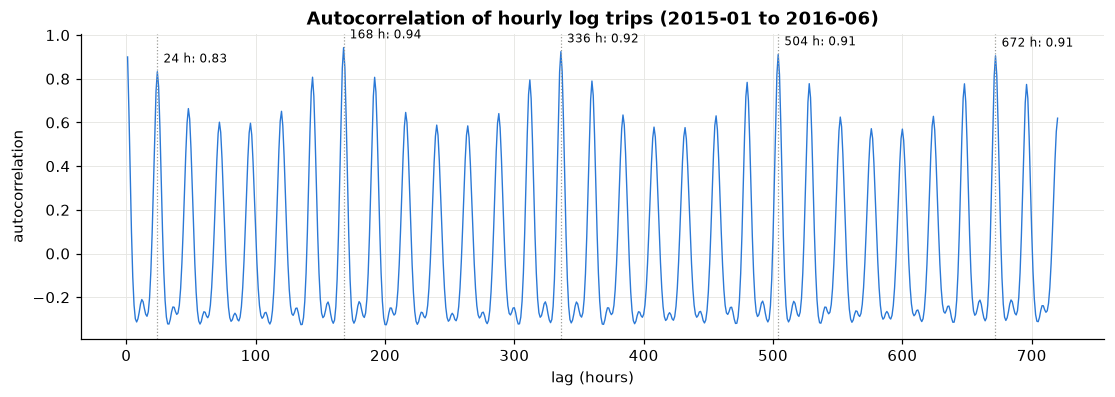

In [11]:
# B3.3 autocorrelation of log trips (fit window, event hours interpolated) up to four weeks
fit = HOURS < FIT_END
y_log = np.log1p(trips[fit].mask((dst_mask | storm_mask)[fit]).interpolate())
r = acf(y_log, nlags=720, fft=True)
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(np.arange(1, 721), r[1:], color=BLUE, lw=0.9)
for k in (24, 168, 336, 504, 672):
    ax.axvline(k, color=GREY, ls=":", lw=0.8)
    ax.annotate(f"{k} h: {r[k]:.2f}", (k, r[k]), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.set_title("Autocorrelation of hourly log trips (2015-01 to 2016-06)")
ax.set_xlabel("lag (hours)")
ax.set_ylabel("autocorrelation")
plt.show()

Autocorrelation is strongest at 168 hours (one week, 0.94) and barely decays over four weeks (still 0.91 at 672 hours). The 24-hour repetition (yesterday) is weaker at 0.83, because yesterday is not always the same kind of day as today: going from Friday to Saturday or from Sunday to Monday, the hourly shape of demand changes clearly. This is why the day of week is the core information for the forecast.

I also measured which information can be used as the horizon grows. For this I compared the error of simple forecasts that use only values older than the horizon, at each horizon.

In [12]:
# B3.4 horizon evidence: single-lag forecasts and the 4-week median moved further back (selection halves A and B)
hz = pd.read_csv(SEL / "k6f_horizon_evidence.csv")
hz["forecast"] = np.where(hz["check"] == "single lag", "value " + hz["hours"].astype(str) + " h ago",
                          "median of 4 weeks, newest " + (hz["hours"] // 168).astype(str) + " week(s) ago")
hz.set_index("forecast")[["WAPE_A_%", "WAPE_B_%"]]

,WAPE_A_%,WAPE_B_%
forecast,,
value 24 h ago,16.43,15.72
value 48 h ago,25.77,25.17
value 72 h ago,28.64,28.36
value 96 h ago,28.42,28.37
value 120 h ago,25.85,25.42
value 144 h ago,17.80,17.16
value 168 h ago,9.14,8.42
"median of 4 weeks, newest 1 week(s) ago",8.35,6.98
"median of 4 weeks, newest 2 week(s) ago",8.87,7.33


As a single lag, yesterday's value (24 hours) gives 15.7–16.4% error, two to five days earlier 25–29%, and the same hour last week 8.4–9.1%. So at every horizon longer than 24 hours, the best usable information is the same hour last week; forecasting 48 hours and 168 hours ahead uses the same information. Once the horizon passes one week, the error grows by 0.3–0.7 points per week.

Therefore:
- **Main horizon 24 hours:** at 00:00 each day, the 24 hours of that day (day-ahead plan). At a one-day horizon the level of the last day can also be used.
- **Additional horizon 168 hours:** the longest horizon that covers the whole weekly cycle (weekly shift and fleet planning). The origin is Monday 00:00 (ISO week start); I did not try other origin days.
- **1 hour:** reference row only; it shows how much a forecast that sees the last hour can improve.
- **Frequency:** hourly. In Section 14 I measured whether a separate model is needed at the daily total level; the daily sum of the hourly forecasts proved sufficient.

Is the shape of the weekly cycle stable across months, with only the level changing?

In [13]:
# B3.5 weekly shape and level by month (fit window): correlation of each month's 168 h profile with the average profile
shape = pd.read_csv(SEL / "k3_weekly_shape_by_month.csv").set_index("month")
shape.columns = ["corr. with average weekly profile", "mean abs. deviation of profile %", "mean trips per hour"]
shape.T

month,2015-01,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06
corr. with average weekly profile,0.97,0.99,0.99,1.00,0.99,0.99,0.98,0.99,1.00,1.00,0.99,0.99,0.98,0.99,1.00,1.00,1.00,0.99
mean abs. deviation of profile %,7.60,3.90,4.27,2.25,3.23,4.26,6.40,4.19,2.62,2.36,4.64,4.96,6.09,4.37,3.18,3.03,3.00,3.55
mean trips per hour,"17,348.38","18,509.27","17,961.21","18,138.06","17,678.91","17,111.72","15,531.62","14,944.78","15,574.84","16,535.93","15,660.03","15,387.73","15,233.22","16,337.67","16,426.24","16,560.18","15,896.75","15,453.90"


Each month's weekly profile correlates 0.97–1.00 with the average profile: the shape is stable. The level, however, drifts; the average trips per hour were 17–18 thousand at the start of 2015 and 15–16 thousand in mid-2016. This is why I framed the forecasting problem as "take the shape from the past, correct the level by the most recent days".

## 4. Split, error metrics and evaluation design

In a time series, a random split puts the neighbouring hours of test rows into training. I wanted both to prevent this leakage and to measure it.

I split the data into three periods:
- **Fit window:** 2015-01 – 2016-06. All selections were made here.
- **Selection halves:** A = 2015-07..12 and B = 2016-01..06. For each month the model was retrained on all data before that month and forecast that month (monthly expanding window). I looked for a configuration that was good in both halves; a configuration that is good in only one half is exposed to selection bias.
- **Test:** 2016-07..12, once, after everything was frozen.

The forecast setup is day-ahead: at 00:00 each day, the 24 hours of that day. All inputs are known at the origin: lags are at least 24 hours old, and level ratios are computed up to the last hour before the origin. A single model covers hours 1–24.

In [14]:
# B4.1 the three periods and the scored hours (DST 01-02 and storm hours excluded)
def scored(start, end):
    h = HOURS[(HOURS >= start) & (HOURS < end)]
    return h[OKY[HOURS.get_indexer(h)]]

idx_A, idx_B, idx_T = scored("2015-07-01", "2016-01-01"), scored("2016-01-01", "2016-07-01"), scored("2016-07-01", "2017-01-01")
PERIODS = {"A 2015-07..12": idx_A, "B 2016-01..06": idx_B, "test 2016-07..12": idx_T}
pd.DataFrame([{"period": k, "use": u, "scored hours": len(v), "hours excluded": int(((HOURS >= v.min().normalize()) & (HOURS <= v.max())).sum() - len(v))}
              for (k, v), u in zip(PERIODS.items(), ["selection", "selection", "test, run once"])]).set_index("period")

,use,scored hours,hours excluded
period,,,
A 2015-07..12,selection,4414,2
B 2016-01..06,selection,4318,50
test 2016-07..12,"test, run once",4414,2


The number of hours in the score is 4,414 in A, 4,318 in B and 4,414 in the test; only DST and storm hours are left out (2, 50 and 2 hours). I showed how optimistic a random split is on the same rows. I evaluated the same LightGBM model (with fixed hyperparameters) in two ways: random 5-fold and a time split (train on 2015, evaluate on the first half of 2016). The error was always measured on the hours of the first half of 2016. Because the training size differs between the two designs, I repeated the random split once more with the training size reduced to that of the time split.

In [15]:
# B4.2 leakage of a random split: same rows, same model, scored on 2016-H1 hours
leak = pd.read_csv(SEL / "k4_leakage_demo.csv").set_index("features")
equal = pd.read_csv(POST / "k14d_leakage_equal_size.csv").set_index("design")
pd.DataFrame({"WAPE on 2016-H1 %": [equal.iloc[0, 1], equal.iloc[1, 1], equal.iloc[2, 1], leak.iloc[1, 1], leak.iloc[1, 0]],
              "training rows": [equal.iloc[0, 0], equal.iloc[1, 0], equal.iloc[2, 0], np.nan, np.nan]},
             index=["time split (train 2015)", "random 5-fold", "random 5-fold, training cut to time-split size",
                    "time split + lags 1-3 h (not known at 00:00)", "random 5-fold + lags 1-3 h"])

,WAPE on 2016-H1 %,training rows
time split (train 2015),6.57,"8,084.00"
random 5-fold,5.34,"9,921.00"
"random 5-fold, training cut to time-split size",5.51,"8,084.00"
time split + lags 1-3 h (not known at 00:00),4.04,NaN
random 5-fold + lags 1-3 h,3.51,NaN


The random split shows an error of 5.34%, the time split 6.57%: the random split is 19% optimistic. With equal training size the gap stays almost the same (5.51%, 16% optimistic). Most of the optimism comes from the neighbours of the evaluated hours being in training; the share of training size is small. I added the equal-size comparison after the test; the decision did not change. Adding the last 1–3 hours, which are not known at the origin, as features also gives a spurious gain of 2.5 points; in the day-ahead setup this information cannot be used.

I also chose monthly retraining and the expanding window by measuring them.

In [16]:
# B4.3 refit cadence and training window (LightGBM probe, 2016-01..06, mean of six monthly folds)
bt = pd.read_csv(SEL / "k4_backtest_design.csv")
bt.pivot(index="setup", columns="month", values="wape_%").assign(mean=lambda d: d.mean(axis=1)).sort_values("mean")

month,2016-01,2016-02,2016-03,2016-04,2016-05,2016-06,mean
setup,,,,,,,
"refit monthly, expanding",14.41,7.04,5.27,4.81,5.82,5.36,7.12
"refit monthly, sliding 52 w",14.41,7.02,5.27,4.81,5.99,5.46,7.16
single fit 2015-12-31,14.41,7.09,5.32,4.94,6.07,5.50,7.22
"refit monthly, sliding 26 w",16.28,7.28,5.99,5.05,6.93,6.19,7.95
baseline 4-week mean,20.27,9.13,5.57,5.24,7.53,5.38,8.85


The 26- and 52-week rolling windows did not beat the expanding window, so I chose the expanding window. In this half, monthly retraining is only 0.1 points better than a single training run; for the LSTM, monthly retraining was clearly better (B7.5). I retrained the tree-based models and the LSTM every month; the baseline has no training and is recomputed each day from the current history.

### Error metrics

I used three error metrics and one bias measure. $y_t$ is the actual value, $\hat y_t$ the forecast:

- **WAPE** = $\sum |y_t - \hat y_t| \,/\, \sum y_t$. The error share of total volume. Busy hours get more weight; I chose it as the **main metric** because it directly states the error in the planned total trip volume.
- **MAPE** = mean of $|y_t - \hat y_t| / y_t$. Every hour has equal weight; small absolute errors in quiet hours become large percentages.
- **MASE** = mean $|y_t - \hat y_t|$ / mean absolute error of the model that uses the same hour last week as the forecast (2015-02..12). Below 1 means better than this simple rule.
- **Bias** = $\sum (\hat y_t - y_t) / \sum y_t$. A positive value means over-forecasting.

A small example shows the difference: two hours, one quiet (night) and one busy (evening).

In [17]:
# B4.4 metric definitions and a two-hour example: WAPE weights hours by volume, MAPE weights them equally
def wape(y, f):
    return 100 * np.abs(y - f).sum() / np.abs(y).sum()

def mape(y, f):
    return 100 * (np.abs(y - f) / y).mean()

def bias(y, f):
    return 100 * (f - y).sum() / y.sum()

scale_idx = HOURS[(HOURS >= "2015-02-01") & (HOURS < "2016-01-01") & OKY]
MASE_SCALE = np.abs(trips[scale_idx] - trips.shift(168)[scale_idx]).mean()

def mase(y, f):
    return np.abs(y - f).mean() / MASE_SCALE

ex_y, ex_f = np.array([2_000.0, 25_000.0]), np.array([2_400.0, 24_000.0])
pd.DataFrame({"actual": ex_y, "forecast": ex_f, "abs error": np.abs(ex_y - ex_f), "abs % error": 100 * np.abs(ex_y - ex_f) / ex_y},
             index=["quiet hour (03:00)", "busy hour (19:00)"]).assign(
    WAPE_both=wape(ex_y, ex_f), MAPE_both=mape(ex_y, ex_f), MASE_both=mase(ex_y, ex_f))

,actual,forecast,abs error,abs % error,WAPE_both,MAPE_both,MASE_both
quiet hour (03:00),"2,000.00","2,400.00",400.00,20.00,5.19,12.00,0.47
busy hour (19:00),"25,000.00","24,000.00","1,000.00",4.00,5.19,12.00,0.47


The two hours have a total error of 1,400 trips. WAPE divides this by the total of 27,000 trips (5.2%). MAPE averages the percentages of the two hours: because the 400-trip error in the quiet hour is 20%, MAPE rises to 12%. In this data, MAPE in the quietest hours is 1.3 times the MAPE over all hours (B9.10). Because a platform plans total volume, I took WAPE as the main metric; I report MAPE and MASE alongside it in the tables.

### Is the difference real?

I tested whether the difference between two models' WAPEs is due to chance with a weekly block bootstrap. Hourly errors are dependent (the hours of the same day share the same level error), so I resampled weeks instead of hours. 10,000 repetitions, a fixed seed for each comparison, 90% interval. If the bootstrap interval does not contain 0, the difference is **statistically distinguishable**; if it does, I wrote "not distinguishable". "Not distinguishable" does not mean the two models are equal, only that I could not see a difference with this data. If the interval's bound is closer than 0.02 points to 0, I wrote the result as a "tendency". A difference that exceeds a threshold I set in advance is **practically meaningful**; I kept the two apart.

In [18]:
# B4.5 weekly block bootstrap of a WAPE difference (fa - fb, percentage points); used for every comparison below
def boot10k(fa, fb, idx, seed, n=10_000, block_days=None):
    """Difference in WAPE (fa - fb) with a 90% block-bootstrap interval; blocks are calendar weeks unless block_days is given."""
    y = trips[idx].astype(float)
    if block_days is None:
        key = idx.to_period("W").astype(str)
    else:
        key = ((idx.normalize() - idx.normalize().min()).days // block_days).astype(str)
    a = (y - fa.reindex(idx)).abs().groupby(key).sum().to_numpy()
    b = (y - fb.reindex(idx)).abs().groupby(key).sum().to_numpy()
    t = y.groupby(key).sum().to_numpy()
    pick = np.random.default_rng(seed).integers(0, len(a), size=(n, len(a)))
    d = 100 * (a[pick] - b[pick]).sum(1) / t[pick].sum(1)
    return 100 * (a.sum() - b.sum()) / t.sum(), np.percentile(d, 5), np.percentile(d, 95)

def verdict(r):
    v = "worse" if r[1] > 0 else ("better" if r[2] < 0 else "not distinguishable")
    return v + (" (tendency)" if v != "not distinguishable" and min(abs(r[1]), abs(r[2])) < 0.02 else "")

def fmt(r):
    return f"{r[0]:+.2f} [{r[1]:+.2f}, {r[2]:+.2f}]"

def wp(f, idx):
    return wape(trips[idx], f.reindex(idx))

## 5. Baseline

Before building complex models, I set a strong baseline that they would have to beat.

**Cleaned history.** In the history used as model input, I replaced DST, storm, major holiday and special day hours with the median of the same hour over the previous four weeks. The replacement only looks backward (causal): when an hour is cleaned, only the weeks before it are used. The target is always the raw value, so a holiday is still forecast and scored against its actual value; it only looks like a normal day in the input of the following days.

In [19]:
# B5.1 cleaned history: event hours replaced causally by the median of the same hour in the previous 4 weeks
def causal_clean(y, mask):
    c = y.astype(float).copy()
    for t in y.index[mask]:
        refs = [c.get(t - pd.Timedelta(hours=168 * k)) for k in range(1, 5)]
        refs = [v for v in refs if v is not None and not np.isnan(v)]
        c[t] = np.median(refs) if refs else np.nan
    return c

day_event = pd.Series(HOURS.normalize().isin(major | special), index=HOURS)
clean_mask = (dst_mask | storm_mask | day_event).to_numpy()
trips_clean = causal_clean(trips, clean_mask)
stored_clean = pd.read_parquet(SEL / "k5_trips_clean.parquet")["trips_clean"]
assert np.allclose(trips_clean.to_numpy(), stored_clean.to_numpy(), rtol=1e-9, equal_nan=True)
pd.Series({"hours replaced": int(clean_mask.sum()), "of which DST": int(dst_mask.sum()), "storm": int(storm_mask.sum()),
           "major holiday / special day": int(day_event.sum()), "same as stored cleaned series": True}).to_frame("value")

,value
hours replaced,596
of which DST,8
storm,84
major holiday / special day,504
same as stored cleaned series,True


Cleaning replaced 596 hours (504 major holiday and special day, 84 storm, 8 DST), and the result is identical to the saved clean series. I did not pick the baseline hyperparameters one by one; I tested 650 configurations (2–8 past weeks, mean or median, level-adjustment window of 0–28 days, five cleaning options) under two evaluation schemes. Changing each factor while holding the others fixed gives:

In [20]:
# B5.2 baseline sensitivity: mean WAPE when one factor changes around the chosen setting (650 configurations, two designs)
sens = pd.read_csv(SEL / "k5b_baseline_sensitivity.csv")
pick = {"mask": "+major+special (K5)", "ref_weeks": 4, "weeks": 6, "agg": "median", "level_days": 3}
out = []
for factor in ["weeks", "agg", "level_days", "mask"]:
    sub = sens.copy()
    for k, v in pick.items():
        if k != factor:
            sub = sub[sub[k] == v]
    for val, g in sub.groupby(factor):
        out.append({"factor": factor, "value": str(val), "chosen": val == pick[factor],
                    **{d: g.loc[g["design"] == d, "wape_mean"].iloc[0] for d in g["design"].unique()}})
pd.DataFrame(out).set_index(["factor", "value"])

chosen  E6 2016-01..06  E12 2015-07..2016-06
factor     value                                                            
weeks      2                     False            7.53                  7.91
           3                     False            6.93                  7.34
           4                     False            6.68                  7.15
           6                      True            6.52                  7.10
           8                     False            6.56                  7.21
agg        mean                  False            6.52                  7.12
           median                 True            6.52                  7.10
level_days 0                     False            7.11                  7.95
           3                      True            6.52                  7.10
           7                     False            6.76                  7.26
           14                    False            6.99                  7.47
           28                    False            7.10                  7.62
mask       +all federal          False            6.47                  7.06
           +major                False            6.50                  7.01
           +major+special (K5)    True            6.52                  7.10
           dst+storm             False            6.64                  7.04
           none                  False            7.10                  7.27

Six weeks beats four weeks, and median and mean perform at the same level; for the level adjustment, the ratio over the last three days is best (7.11 without adjustment, 6.52 with it). Cleaning has a large effect in the 6-month scheme (from 7.10 to 6.52) and a small one in the 12-month scheme; the details of the cleaning mask matter little in either scheme. Since I chose these hyperparameters out of 650 configurations, I tested for selection bias separately: I made the choice on half A only and measured it on half B. The broad structure chosen on A (cleaning, level adjustment, 6 weeks, median) holds on B as well; the fine hyperparameter differences are at noise level (Appendix C, B5.3).

The chosen 24-hour baseline: **median of the same hour over the last 6 weeks × level ratio of the last 3 days** (actual total of the last 3 days / total of the forecasts computed with the same formula; the ratio is fixed at 00:00 and used for the whole day). I used the cleaned history as input. For 168 hours I used only the four-week median, because the level adjustment hurt when held fixed for a week. For 1 hour I adjusted the four-week mean by the ratio of the last hour and used raw input. I recomputed all three here and compared them with the saved forecasts.

In [21]:
# B5.4 the three baselines, recomputed here and checked against the stored selection and test forecasts
is_day0 = HOURS.hour == 0

def hold_from(series_at_origin, origin_flag):
    """Value known at the origin (computed up to origin - 1 h), held for the whole forecast window."""
    return series_at_origin.shift(1).where(origin_flag).ffill()

med6 = pd.concat([trips_clean.shift(168 * j) for j in range(1, 7)], axis=1).median(axis=1)
base24 = med6 * hold_from(trips_clean.rolling(72).sum() / med6.rolling(72).sum(), is_day0)
base168 = pd.concat([trips_clean.shift(168 * j) for j in range(1, 5)], axis=1).median(axis=1)
mean4_raw = sum(trips.astype(float).shift(168 * k) for k in range(1, 5)) / 4
base1 = mean4_raw * (trips.shift(1) / mean4_raw.shift(1))

stored = {"24 h, A/B": (base24, pd.read_parquet(SEL / "k6c_preds_AB.parquet")["baseline"]),
          "24 h, test": (base24, pd.read_parquet(TEST / "pred_24h.parquet")["baseline"]),
          "168 h, A/B": (base168, pd.read_parquet(SEL / "k6e_168h_AB.parquet")["base_168h"]),
          "168 h, test": (base168, pd.read_parquet(TEST / "pred_168h.parquet")["baseline"]),
          "1 h, A/B": (base1, pd.read_parquet(SEL / "k6e_1h_AB.parquet")["base_1h"]),
          "1 h, test": (base1, pd.read_parquet(TEST / "pred_1h.parquet")["baseline"])}
check = []
for name, (live, saved) in stored.items():
    ok = np.allclose(live.reindex(saved.index).to_numpy(), saved.to_numpy(), rtol=1e-6)
    assert ok, name
    check.append({"baseline": name, "hours": len(saved), "max |live - stored|": float((live.reindex(saved.index) - saved).abs().max()), "identical": ok})
pd.DataFrame(check).set_index("baseline")

,hours,max |live - stored|,identical
baseline,,,
"24 h, A/B",8784,0.00,True
"24 h, test",4416,0.00,True
"168 h, A/B",8904,0.00,True
"168 h, test",4200,0.00,True
"1 h, A/B",8784,0.00,True
"1 h, test",4416,0.00,True


All three baselines reproduce the saved forecasts exactly. Their errors in the selection halves and the comparison with simpler references:

In [22]:
# B5.5 baseline errors on the selection halves, next to simpler references
naive = {"same hour yesterday (24 h)": trips.shift(24).astype(float), "same hour last week (24 h)": trips.shift(168).astype(float),
         "24 h baseline": base24, "168 h baseline": base168, "previous hour (1 h)": trips.shift(1).astype(float), "1 h baseline": base1}
pd.DataFrame([{"forecast": k, **{f"WAPE {p[:1]} %": wp(f, ix) for p, ix in list(PERIODS.items())[:2]},
               "MAPE A+B %": mape(trips[idx_A.union(idx_B)], f.reindex(idx_A.union(idx_B))),
               "MASE A+B": mase(trips[idx_A.union(idx_B)], f.reindex(idx_A.union(idx_B)))} for k, f in naive.items()]).set_index("forecast")

,WAPE A %,WAPE B %,MAPE A+B %,MASE A+B
forecast,,,,
same hour yesterday (24 h),15.56,15.75,26.78,1.66
same hour last week (24 h),10.01,9.43,11.63,1.03
24 h baseline,7.64,6.44,8.67,0.75
168 h baseline,8.35,6.98,9.53,0.81
previous hour (1 h),14.21,14.99,20.92,1.55
1 h baseline,3.37,3.73,4.25,0.38


The 24-hour baseline has an error of 7.64% on A and 6.44% on B, much better than using yesterday's same hour (16%) or last week's same hour. I always measured the models' contribution against this baseline. MASE is below 1: the baseline beats last week's same hour. (When computing the MASE scale, I did not exclude the hours one week after DST and storm events. Not excluding them makes the scale slightly larger, so MASE values look slightly optimistic. Since the same scale is applied to every row, the ranking does not change.)

Cleaning the input gains 0.5–1.2 points within the baseline family (Appendix C, B5.6); I used cleaned input for all models, with Chronos as the only exception (Section 8).

The candidates for the 168-hour baseline and their ranks in the two halves are in Appendix C (B5.7).

### Model card: baseline

- **Model:** seasonal rule. The median of the same hour over past weeks, scaled by the level of the last days. No training.
- **Data format:** cleaned hourly series; origin at 00:00 every day, 24-hour forecast. The level ratio is fixed at the origin.
- **Parameters:** 24 h: 6 weeks, median, 3-day level ratio · 168 h: 4 weeks, median, no level adjustment · 1 h: 4-week mean × ratio of the last hour, raw input. All were chosen with a 650-configuration sensitivity analysis and a two-half test (B5.2, B5.3, B5.7).
- **Finding:** 24 h 7.64% / 6.44% in the selection halves. Its broad structure is consistent across the two halves. The test result is in Section 9.

## 6. Tree-based models: LightGBM and XGBoost

Tree-based models have no notion of time, so I gave them time as features. I made three decisions:

1. **Target:** the deviation from the baseline rather than the trip count itself: `log(1 + trips) − log(1 + baseline)`. LightGBM leaves the level shift to the baseline and learns only the correction. Using the level itself as the target gave the same result on A and a worse one on B.
2. **Features:** all are known at the origin (00:00): lags are at least one day old, level ratios run up to the last hour before the origin, and the calendar is known in advance. The individual values of the last hours before the origin are not features.
3. **Training:** retrained every month with all data before that month (monthly expanding window), with L1 loss.

I chose the lags from the ACF: lags older than 24 hours whose ACF stays above 0.7. These lags fall on the same day of week in previous weeks and on the day before or after it.

In [23]:
# B6.1 candidate lags: autocorrelation of log trips (fit window) at the lags used and nearby
lags = pd.read_csv(SEL / "k3_acf_lags.csv").set_index("Unnamed: 0")
lags.index.name = "lag (hours)"
lags.columns = ["ACF of log trips", "ACF after removing last week's value"]
lags.T

lag (hours),1,2,3,23,24,25,48,72,144,167,168,169,336,504,672
ACF of log trips,0.90,0.66,0.37,0.74,0.83,0.76,0.66,0.60,0.81,0.85,0.94,0.85,0.92,0.91,0.91
ACF after removing last week's value,0.90,0.73,0.54,0.33,0.35,0.33,0.18,0.07,-0.17,-0.38,-0.41,-0.36,-0.05,-0.06,0.08


Lags of 1–3 hours are very strong, but in the day-ahead setup they are not known at the origin (I showed this as leakage in Section 4). Among lags older than 24 hours, the strongest are 168 and its multiples. Even after subtracting last week's value, the 24-hour lag still has a correlation of 0.35: yesterday's deviation carries over to today. That is why I added a "yesterday's deviation" feature.

The feature groups I used:

In [24]:
# B6.2 tree features for the 24 h day-ahead model (all known at the 00:00 origin)
LAGS_NEAR, LAGS_FAR = [24, 144, 168, 192], [312, 336, 360, 480, 504, 528, 648, 672]

def days_to(dates, targets, direction, cap=8):
    """Days to the next (direction=+1) or since the last (-1) key day, capped at 8."""
    t = np.array(sorted(targets), dtype="datetime64[D]")
    d = dates.to_numpy().astype("datetime64[D]")
    pos = np.searchsorted(t, d, side="left" if direction > 0 else "right")
    out = (np.where(pos < len(t), (t[np.minimum(pos, len(t) - 1)] - d).astype(int), cap) if direction > 0
           else np.where(pos > 0, (d - t[np.maximum(pos - 1, 0)]).astype(int), cap))
    return np.minimum(out, cap)

day = HOURS.normalize()
calendar = pd.DataFrame({"hour": HOURS.hour, "dow": HOURS.dayofweek, "hol_major": day.isin(major).astype(int),
                         "hol_minor": day.isin(minor).astype(int), "special_day": day.isin(special).astype(int),
                         "after_major": (day - pd.Timedelta(days=1)).isin(major).astype(int),
                         "days_to_next_key": days_to(day, major | special, +1), "days_since_key": days_to(day, major | special, -1)}, index=HOURS)
log_clean, log_base = np.log1p(trips_clean), np.log1p(base24)
level = lambda hours: np.log(hold_from(trips_clean.rolling(hours).sum() / base24.rolling(hours).sum(), is_day0))
X24 = pd.concat([
    pd.DataFrame({f"lag_{k}": log_clean.shift(k) for k in LAGS_NEAR + LAGS_FAR}),
    pd.DataFrame({"base_log": log_base, "lvl_1d": level(24), "lvl_3d": level(72), "lvl_7d": level(168), "lvl_28d": level(672)}),
    pd.DataFrame({"dev_yesterday": log_clean.shift(24) - log_clean.shift(192), "dev_yesterday_vs_base": log_clean.shift(24) - log_base.shift(24)}),
    calendar], axis=1)
y_ratio = np.log1p(trips) - log_base
groups = {"lags (same weekday and +-1 day, 1-4 weeks back)": [f"lag_{k}" for k in LAGS_NEAR + LAGS_FAR], "baseline (log)": ["base_log"],
          "level ratios: last 1 / 3 / 7 / 28 days vs baseline": ["lvl_1d", "lvl_3d", "lvl_7d", "lvl_28d"],
          "yesterday's deviation": ["dev_yesterday", "dev_yesterday_vs_base"], "hour, day of week": ["hour", "dow"],
          "holiday flags (major, minor, special, day after major)": ["hol_major", "hol_minor", "special_day", "after_major"],
          "days to next / since last key day": ["days_to_next_key", "days_since_key"]}
pd.DataFrame([{"group": g, "features": len(c), "columns": ", ".join(c if len(c) <= 4 else c[:3] + ["..."])} for g, c in groups.items()]).set_index("group")

,features,columns
group,,
"lags (same weekday and +-1 day, 1-4 weeks back)",12,"lag_24, lag_144, lag_168, ..."
baseline (log),1,base_log
level ratios: last 1 / 3 / 7 / 28 days vs baseline,4,"lvl_1d, lvl_3d, lvl_7d, lvl_28d"
yesterday's deviation,2,"dev_yesterday, dev_yesterday_vs_base"
"hour, day of week",2,"hour, dow"
"holiday flags (major, minor, special, day after major)",4,"hol_major, hol_minor, special_day, after_major"
days to next / since last key day,2,"days_to_next_key, days_since_key"


As rolling statistics I used level ratios: the actual total of the last 1, 3, 7 and 28 days divided by the baseline total over the same days. I tried seasonal features such as month and week of year during selection and removed them: they mapped incorrectly onto months not seen in the training data (B6.5). To the holiday features I also added how many days remain until a holiday and how many days have passed since one; in LightGBM the largest gain came from these distance-to-holiday features.

I retrained the model in this notebook (12 months in the selection halves, 6 months in the test; a separate training for each month) and compared the forecasts with the saved ones.

In [25]:
# B6.3 LightGBM 24 h: monthly refit on an expanding window, recomputed here for A, B and the test, checked against stored forecasts
import lightgbm as lgb
CFG_TREE = json.loads((SEL / "k6c_frozen_config.json").read_text(encoding="utf-8"))
usable = (np.arange(len(HOURS)) >= 672) & OKY  # four weeks of history available, not a DST or storm hour

def fit_monthly(X, target, log_reference, make_model, months):
    """Train on every usable hour before the month, forecast the month; returns trips."""
    ok = usable & X.notna().all(axis=1).to_numpy() & target.notna().to_numpy()
    out = []
    for m in months:
        start, end = m.to_timestamp(), (m + 1).to_timestamp()
        train, test = HOURS[(HOURS < start) & ok], HOURS[(HOURS >= start) & (HOURS < end)]
        model = make_model().fit(X.loc[train], target.loc[train])
        out.append(pd.Series(np.expm1(model.predict(X.loc[test]) + log_reference[test].to_numpy()), index=test))
    return pd.concat(out)

MONTHS_AB = pd.period_range("2015-07", "2016-06", freq="M")
MONTHS_T = pd.period_range("2016-07", "2016-12", freq="M")
LGB = lambda: lgb.LGBMRegressor(**CFG_TREE["lgb"])
t0 = time.time()
lgb_AB = fit_monthly(X24, y_ratio, log_base, LGB, MONTHS_AB)
lgb_T = fit_monthly(X24, y_ratio, log_base, LGB, MONTHS_T)
P24 = pd.read_parquet(TEST / "pred_24h.parquet")
SEL_TREE = pd.read_parquet(SEL / "k6c_preds_AB.parquet")
rows = []
for name, live, saved, idx in [("A", lgb_AB, SEL_TREE["lgb"], idx_A), ("B", lgb_AB, SEL_TREE["lgb"], idx_B), ("test", lgb_T, P24["lightgbm"], idx_T)]:
    common = live.index.intersection(saved.index)
    assert np.allclose(live[common], saved[common], rtol=1e-6)
    assert abs(wp(live, idx) - wp(saved, idx)) < 1e-4
    rows.append({"period": name, "WAPE live %": wp(live, idx), "WAPE stored %": wp(saved, idx), "max |live - stored| (trips)": float((live - saved).reindex(idx).abs().max())})
pd.DataFrame(rows).set_index("period").assign(fit_seconds_all_18_months=round(time.time() - t0))

,WAPE live %,WAPE stored %,max |live - stored| (trips),fit_seconds_all_18_months
period,,,,
A,6.66,6.66,0.00,42
B,5.53,5.53,0.00,42
test,5.95,5.95,0.00,42


The LightGBM trained live reproduces the saved forecasts both in the selection halves and in the test. The test result is in Section 9; here I look only at the selection halves.

In [26]:
# B6.4 LightGBM vs the baseline on the selection halves
pd.DataFrame([{"half": k, "baseline WAPE %": wp(base24, ix), "LightGBM WAPE %": wp(lgb_AB, ix),
               "LightGBM - baseline [90% CI]": fmt(r := boot10k(lgb_AB, base24, ix, seed=600 + i)), "verdict": verdict(r)}
              for i, (k, ix) in enumerate(list(PERIODS.items())[:2])]).set_index("half")

,baseline WAPE %,LightGBM WAPE %,LightGBM - baseline [90% CI],verdict
half,,,,
A 2015-07..12,7.64,6.66,"-0.98 [-1.83, -0.33]",better
B 2016-01..06,6.44,5.53,"-0.91 [-1.36, -0.54]",better


LightGBM is about one point better than the baseline in both halves, and the difference is distinguishable. The steps below show how I got there. The rule for each step was written in advance: the combined A+B error must drop and neither half may get worse by more than 0.1 points.

In [27]:
# B6.5 how the tree model was built: target form, feature groups and each accepted / rejected step (selection halves)
stages = pd.read_csv(SEL / "k6b_stages.csv").rename(columns={"stage_setup": "step", "wape_A": "WAPE A %", "wape_B": "WAPE B %", "wape_AB": "WAPE A+B %"})
first = pd.read_csv(SEL / "k6_ablation.csv")[["setup", "wape_A", "wape_B"]].rename(columns={"setup": "step", "wape_A": "WAPE A %", "wape_B": "WAPE B %"})
first["WAPE A+B %"] = np.nan
pd.concat([first.assign(stage="1: target form and feature groups"), stages.assign(stage="2: additions, one at a time")]).set_index(["stage", "step"])

WAPE A %  WAPE B %  WAPE A+B %
stage                             step                                                       
1: target form and feature groups level: all groups                7.93      5.86         NaN
                                  ratio: all groups                7.93      5.79         NaN
                                  ratio: drop lags_near            8.07      5.82         NaN
                                  ratio: drop lags_far             7.84      5.86         NaN
                                  ratio: drop base                 8.02      5.92         NaN
                                  ratio: drop level                8.17      6.00         NaN
                                  ratio: drop dev                  8.06      5.96         NaN
                                  ratio: drop calendar             7.97      5.82         NaN
                                  ratio: drop holiday              8.85      6.02         NaN
                                  ratio: drop season               7.51      5.78         NaN
2: additions, one at a time       S0 ratio, no season              7.51      5.78        6.64
                                  S1 + season_sincos               7.95      5.66        6.80
                                  S1 + hol_dist                    6.84      5.64        6.24
                                  S1 + spread                      6.91      5.64        6.27
                                  S2 l2, weight=True               6.86      5.61        6.24
                                  S2 l1, weight=False              6.75      5.53        6.14
                                  S2 l1, weight=True               6.72      5.57        6.15
                                  S2 huber, weight=False           6.78      5.53        6.15
                                  S2 huber, weight=True            6.73      5.59        6.16
                                  S3 leaves=15, min_child=20       6.68      5.53        6.10
                                  S3 leaves=15, min_child=100      6.82      5.64        6.23
                                  S3 leaves=15, min_child=300      7.13      5.73        6.43
                                  S3 leaves=31, min_child=20       6.75      5.54        6.14
                                  S3 leaves=31, min_child=100      6.82      5.67        6.24
                                  S3 leaves=31, min_child=300      7.13      5.71        6.42
                                  S3 leaves=63, min_child=100      6.83      5.67        6.25
                                  S3 leaves=63, min_child=300      7.13      5.71        6.42

The ratio target matches the level target on A (7.93) and is slightly better on B. Removing the seasonal group (month, week of year) brought A down from 7.93 to 7.51. The distance-to-holiday feature took A to 6.84. L1 loss and 15 leaves (`num_leaves`) were also accepted.

After the test, I measured again on the frozen final model by removing each feature group individually and in combination (in the selection halves). The model did not change; this table only shows which information is useful.

In [28]:
# B6.6 ablation of the frozen LightGBM on the selection halves (one group removed or added at a time; and pairs)
abl = pd.concat([pd.read_csv(POST / "k14c_feature_ablation.csv"), pd.read_csv(POST / "k14i_joint_ablation.csv")]).set_index("variant")
abl[["n_features", "diff A", "diff B", "diff A+B", "verdict"]].rename(columns=lambda c: c.replace("diff", "variant - frozen,"))

,n_features,"variant - frozen, A","variant - frozen, B","variant - frozen, A+B",verdict
variant,,,,,
drop near lags (24/144/168/192),23,"+0.01 [-0.06, +0.08]","-0.01 [-0.05, +0.04]","+0.00 [-0.04, +0.04]",not distinguishable
drop far lags (312..672),19,"-0.04 [-0.16, +0.07]","+0.04 [-0.00, +0.09]","+0.00 [-0.06, +0.06]",not distinguishable
lags: only lag_168,16,"-0.09 [-0.22, +0.03]","+0.04 [-0.01, +0.09]","-0.02 [-0.10, +0.04]",not distinguishable
drop all lags,15,"-0.00 [-0.10, +0.08]","+0.04 [-0.02, +0.10]","+0.02 [-0.04, +0.07]",not distinguishable
drop baseline (base_log),26,"+0.01 [-0.06, +0.08]","+0.03 [+0.00, +0.07]","+0.02 [-0.02, +0.06]",not distinguishable
drop level ratios (rolling 1/3/7/28 d),23,"-0.14 [-0.43, +0.09]","-0.03 [-0.15, +0.07]","-0.09 [-0.24, +0.04]",not distinguishable
drop deviation (yesterday),25,"+0.11 [-0.04, +0.25]","+0.12 [+0.03, +0.21]","+0.12 [+0.04, +0.19]",needed
drop hour,26,"+0.06 [-0.02, +0.16]","+0.02 [-0.01, +0.05]","+0.04 [-0.01, +0.09]",not distinguishable
drop day of week,26,"+0.04 [-0.04, +0.14]","+0.05 [-0.01, +0.11]","+0.04 [-0.00, +0.10]",not distinguishable


- **Needed (error increases when removed):** all holiday features together (+0.55 points), distance to holiday (+0.27), yesterday's deviation (+0.12). Removing hour and day of week together gives +0.07 (the lower bound of the interval is very close to 0, a tendency).
- **Substitutes for each other:** removing either the lags or the baseline alone makes no difference, removing both makes it worse (+0.15). Both carry information about the same hour in past weeks; when one is present, the other adds nothing. The additional contribution of the level ratios was not distinguishable.
- **Adding does not help:** weekend flag (day of week is already present), month and week of year, mean and standard deviation of the last 7 days. The mean and standard deviation of the last 7 days make the error worse as a tendency.

Since the table contains 21 comparisons, borderline results whose interval is very close to 0 should be read as tendencies. Gain importance is in Appendix C (B6.7).

I tested the hyperparameters with a grid search of 72 configurations including the starting configuration (`num_leaves` 4/7/15, `min_child_samples` 5–50, learning rate and number of trees), and compared LightGBM and XGBoost with the same features.

In [29]:
# B6.8 hyper-parameter grid (72 settings) and seed stability: LightGBM and XGBoost, selection halves
grid = pd.read_csv(SEL / "k6c_grid.csv")
seeds = pd.read_csv(SEL / "k6c_seeds.csv")
pd.DataFrame({"settings tried": [len(grid)], "best A+B %": [grid["AB"].min()], "chosen A+B %": [grid.loc[0, "AB"]],
              "worst A+B %": [grid["AB"].max()], "LightGBM seed sd (A, B)": [f"{seeds['lgb_A'].std():.3f}, {seeds['lgb_B'].std():.3f}"],
              "XGBoost seed sd (A, B)": [f"{seeds['xgb_A'].std():.3f}, {seeds['xgb_B'].std():.3f}"]})

,settings tried,best A+B %,chosen A+B %,worst A+B %,"LightGBM seed sd (A, B)","XGBoost seed sd (A, B)"
0,72,6.09,6.10,6.22,"0.016, 0.012","0.014, 0.026"


The setting I chose (A+B 6.10) is very close to the best setting (6.09), so the choice of setting barely changes the result. The next question was whether another gradient boosting library with the same features gives a different result.

In [30]:
# B6.9 XGBoost (same features and target, frozen setting) vs LightGBM on the selection halves; stored forecasts
pd.DataFrame([{"half": k, "LightGBM WAPE %": wp(SEL_TREE["lgb"], ix), "XGBoost WAPE %": wp(SEL_TREE["xgb"], ix),
               "XGBoost - LightGBM [90% CI]": fmt(r := boot10k(SEL_TREE["xgb"], SEL_TREE["lgb"], ix, seed=610 + i)), "verdict": verdict(r)}
              for i, (k, ix) in enumerate(list(PERIODS.items())[:2])]).set_index("half")

,LightGBM WAPE %,XGBoost WAPE %,XGBoost - LightGBM [90% CI],verdict
half,,,,
A 2015-07..12,6.66,6.60,"-0.06 [-0.19, +0.05]",not distinguishable
B 2016-01..06,5.53,5.58,"+0.05 [-0.01, +0.12]",not distinguishable


All 72 configurations fall within 6.09–6.22: hyperparameter choice is a second-order decision. Changing the seed moves the error by 0.01–0.03 points. XGBoost and LightGBM were not distinguishable in the selection halves; LightGBM is about twice as fast in the test run (LightGBM 7.7, XGBoost 15 seconds; B11.1). For this reason the main tree-based model is LightGBM, with XGBoost as a side row.

### LightGBM for 168 hours and 1 hour

I carried the same approach over to two additional horizons; the code is in a separate computation notebook and the forecasts are in files with SHA checksums.
- **168 hours:** Monday 00:00 origin, only lags older than 168 hours, baseline is the 4-week median, level ratios fixed at the origin for one week, plus an "hours since origin" feature.
- **1 hour:** an origin every hour; deviations of the last 1–3 hours and of yesterday's same hour from the baseline.

In [31]:
# B6.10 168 h and 1 h tree models vs their baselines on the selection halves (stored forecasts)
t168, t1 = pd.read_parquet(SEL / "k6e_168h_AB.parquet"), pd.read_parquet(SEL / "k6e_1h_AB.parquet")
rows = []
for j, (hz, tree, base) in enumerate([("168 h", t168["tree_168h"], t168["base_168h"]), ("1 h", t1["tree_1h"], t1["base_1h"])]):
    for i, (k, ix) in enumerate(list(PERIODS.items())[:2]):
        r = boot10k(tree, base, ix, seed=620 + 2 * j + i)
        rows.append({"horizon": hz, "half": k, "baseline WAPE %": wp(base, ix), "tree WAPE %": wp(tree, ix), "tree - baseline [90% CI]": fmt(r), "verdict": verdict(r)})
pd.DataFrame(rows).set_index(["horizon", "half"])

baseline WAPE %  tree WAPE % tree - baseline [90% CI]              verdict
horizon half                                                                                     
168 h   A 2015-07..12             8.35         7.27     -1.08 [-2.47, +0.07]  not distinguishable
        B 2016-01..06             6.98         6.26     -0.72 [-1.49, -0.09]               better
1 h     A 2015-07..12             3.37         3.31     -0.06 [-0.17, +0.05]  not distinguishable
        B 2016-01..06             3.73         3.27     -0.46 [-0.65, -0.30]               better

At 168 hours LightGBM is 0.72 points better than the baseline on B; on A its error is 1.08 points lower, but the bootstrap interval includes 0 (not distinguishable). At 1 hour there is no difference on A and it is 0.46 points better on B.

### Model card: LightGBM

- **Model:** an ensemble of decision trees trained with gradient boosting. It takes time as features and learns holiday and calendar effects directly.
- **Data format:** one row per hour, 27 features (B6.2). The target is the log ratio to the baseline. Origin at 00:00 every day; a single model forecasts all 24 hours. Monthly retraining, expanding window.
- **Parameters:** table below; chosen from a 72-configuration grid search by the average of the two halves.
- **Finding:** about 1 point better than the baseline in the selection halves; the gain comes from holidays and days near holidays. Training and forecasting for one test period take a few seconds. The test result is in Section 9.

### Model card: XGBoost

- **Model, data format:** the same features, target and training scheme as LightGBM.
- **Parameters:** table below.
- **Finding:** not distinguishable from LightGBM in the selection halves and slower; side row.

In [32]:
# B6.11 frozen parameters of the two tree models
pd.DataFrame({"LightGBM": pd.Series(CFG_TREE["lgb"]), "XGBoost": pd.Series(CFG_TREE["xgb"])}).fillna("-").astype(str)

,LightGBM,XGBoost
colsample_bytree,0.8,0.8
grow_policy,-,lossguide
learning_rate,0.03,0.05
max_depth,-,0
max_leaves,-,7
min_child_samples,5,-
min_child_weight,-,5
n_estimators,1000,600
n_jobs,4,4
num_leaves,15,-


## 7. LSTM

An LSTM reads time as a sequence rather than as features. I therefore prepared the data differently from LightGBM: one sample per origin (00:00).

- **History window:** the last L hours before the origin; 6 values per hour (log clean trips, log ratio to the baseline, sin/cos of hour and day of week).
- **Known future:** what the calendar tells us about the 24 hours to forecast (log baseline, holiday flags, distance to holiday, day sin/cos).
- **Output:** all 24 hours at once; the target is the same as for LightGBM (log ratio to the baseline).

In [33]:
# B7.1 sequence format: past window (L x 6) and known future (24 x 9) per daily origin
import torch
from torch import nn
torch.set_num_threads(4)
CFG_LSTM = json.loads((SEL / "k8_frozen_config.json").read_text(encoding="utf-8"))
hr, dw = HOURS.hour.to_numpy(), HOURS.dayofweek.to_numpy()
PAST = np.column_stack([log_clean, log_clean - log_base, np.sin(2 * np.pi * hr / 24), np.cos(2 * np.pi * hr / 24),
                        np.sin(2 * np.pi * dw / 7), np.cos(2 * np.pi * dw / 7)]).astype(np.float32)
FUT = np.column_stack([log_base, day.isin(major), day.isin(minor), day.isin(special), (day - pd.Timedelta(days=1)).isin(major),
                       days_to(day, major | special, +1), days_to(day, major | special, -1),
                       np.sin(2 * np.pi * dw / 7), np.cos(2 * np.pi * dw / 7)]).astype(np.float32)
FUT_BINARY = [1, 2, 3, 4]  # 0/1 flags are not standardised
Y_RATIO = y_ratio.to_numpy().astype(np.float32)
ORIGINS = np.where(is_day0)[0]
L = CFG_LSTM["window_hours"]
p = HOURS.get_loc(pd.Timestamp("2016-07-05"))
pd.DataFrame([{"array": "past window", "shape for one origin": str(PAST[p - L:p].shape), "covers": f"{HOURS[p - L]} .. {HOURS[p - 1]}"},
              {"array": "known future", "shape for one origin": str(FUT[p:p + 24].shape), "covers": f"{HOURS[p]} .. {HOURS[p + 23]}"},
              {"array": "target", "shape for one origin": str(Y_RATIO[p:p + 24].shape), "covers": "24 hours of the day, log ratio to baseline"}]).set_index("array")

,shape for one origin,covers
array,,
past window,"(168, 6)",2016-06-28 00:00:00 .. 2016-07-04 23:00:00
known future,"(24, 9)",2016-07-05 00:00:00 .. 2016-07-05 23:00:00
target,"(24,)","24 hours of the day, log ratio to baseline"


Architecture: a single-layer LSTM reads the history window and outputs a 64-dimensional hidden state; this is concatenated with the known future and passed through a dense layer with 128 units to 24 outputs. The loss is L1; DST and storm hours are masked out of the loss. The model is retrained every month; the last 10% of the training days are held out for early stopping. The cell below only defines the model and the training loop, so it has no output. I did the training in a separate computation notebook; the test forecasts are read from disk in the next cell (B7.3). With `RECOMPUTE = True` the same code regenerates the forecasts for five seeds.

In [34]:
# B7.2 LSTM model and training loop (used when RECOMPUTE is True)
class SeqNet(nn.Module):
    def __init__(self, n_past, n_fut, hidden):
        super().__init__()
        self.lstm = nn.LSTM(n_past, hidden, num_layers=1, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden + 24 * n_fut, 128), nn.ReLU(), nn.Linear(128, 24))

    def forward(self, xp, xf):
        _, (h, _) = self.lstm(xp)
        return self.head(torch.cat([h[-1], xf.flatten(1)], dim=1))

def make_days(origins):
    keep = np.array([q for q in origins if q - L >= 0 and q + 24 <= len(HOURS)
                     and not np.isnan(PAST[q - L:q]).any() and not np.isnan(FUT[q:q + 24]).any()])
    xp, xf = np.stack([PAST[q - L:q] for q in keep]), np.stack([FUT[q:q + 24] for q in keep])
    y = np.stack([Y_RATIO[q:q + 24] for q in keep])
    mask = np.stack([OKY[q:q + 24] for q in keep]) & ~np.isnan(y)
    return keep, xp, xf, np.nan_to_num(y), mask.astype(np.float32)

def fit_lstm(train_end, seed, max_epochs=150, patience=15, batch=32):
    torch.manual_seed(seed); np.random.seed(seed)
    end_pos = HOURS.get_loc(pd.Timestamp(train_end))
    keep, xp, xf, y, m = make_days(ORIGINS[ORIGINS + 24 <= end_pos])
    mu_p, sd_p = xp.reshape(-1, xp.shape[2]).mean(0), xp.reshape(-1, xp.shape[2]).std(0) + 1e-6
    mu_f, sd_f = xf.reshape(-1, xf.shape[2]).mean(0), xf.reshape(-1, xf.shape[2]).std(0) + 1e-6
    mu_f[FUT_BINARY], sd_f[FUT_BINARY] = 0.0, 1.0
    xp, xf, y, m = (torch.tensor(a) for a in ((xp - mu_p) / sd_p, (xf - mu_f) / sd_f, y.astype(np.float32), m))
    n_val = max(14, int(0.1 * len(y)))
    n_tr = len(y) - n_val
    net = SeqNet(xp.shape[2], xf.shape[2], CFG_LSTM["hidden"])
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    loss_fn = lambda pr, t, w: ((pr - t).abs() * w).sum() / w.sum()
    best, best_state, wait = np.inf, None, 0
    for _ in range(max_epochs):
        net.train()
        perm = torch.randperm(n_tr)
        for i in range(0, n_tr, batch):
            b = perm[i:i + batch]
            opt.zero_grad(); loss_fn(net(xp[b], xf[b]), y[b], m[b]).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            v = loss_fn(net(xp[n_tr:], xf[n_tr:]), y[n_tr:], m[n_tr:]).item()
        if v < best - 1e-5:
            best, best_state, wait = v, {k: t.clone() for k, t in net.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience:
                break
    net.load_state_dict(best_state)
    return net, (mu_p, sd_p, mu_f, sd_f)

def predict_lstm(net, stats, start, end):
    mu_p, sd_p, mu_f, sd_f = stats
    s, e = HOURS.get_loc(pd.Timestamp(start)), HOURS.get_loc(pd.Timestamp(end) - pd.Timedelta(hours=1)) + 1
    keep, xp, xf, _, _ = make_days(ORIGINS[(ORIGINS >= s) & (ORIGINS < e)])
    net.eval()
    with torch.no_grad():
        out = net(torch.tensor((xp - mu_p) / sd_p), torch.tensor((xf - mu_f) / sd_f)).numpy()
    idx = np.concatenate([np.arange(q, q + 24) for q in keep])
    return pd.Series(np.expm1(out.ravel() + log_base.to_numpy()[idx]), index=HOURS[idx])

def lstm_monthly(seed, months):
    parts = []
    for m in months:
        net, stats = fit_lstm(m.to_timestamp(), seed)
        parts.append(predict_lstm(net, stats, m.to_timestamp(), (m + 1).to_timestamp()))
    return pd.concat(parts)

In [35]:
# B7.3 LSTM test forecasts: stored (RECOMPUTE False) or re-trained for 5 seeds into artifacts/task5/recompute/ and compared
LSTM_COLS = [f"lstm_s{s}" for s in range(CFG_LSTM["seeds"])]
if RECOMPUTE:
    REC = T5 / "recompute"
    REC.mkdir(exist_ok=True)
    t0 = time.time()
    lstm_new = pd.DataFrame({c: lstm_monthly(s, MONTHS_T) for s, c in enumerate(LSTM_COLS)})
    lstm_new.to_parquet(REC / "pred_24h_lstm.parquet")
    lstm_check = pd.DataFrame([{"seed": c, "max |new - stored| (trips)": float((lstm_new[c] - P24[c]).abs().max()),
                                "WAPE new %": wp(lstm_new[c], idx_T), "WAPE stored %": wp(P24[c], idx_T)} for c in LSTM_COLS]).set_index("seed")
    assert (lstm_check["max |new - stored| (trips)"] <= 1.0).all(), lstm_check
    display(lstm_check.assign(seconds=round(time.time() - t0)))
else:
    display(pd.DataFrame([{"source": "test/pred_24h.parquet (SHA-256 checked in B1.2)", "seeds": len(LSTM_COLS), "hours": len(P24)}]).set_index("source"))

,seeds,hours
source,,
test/pred_24h.parquet (SHA-256 checked in B1.2),5,4416


The table shows where the LSTM test forecasts are read from: five seeds, 4,416 hours. The SHA-256 of the file was verified in B1.2. With `RECOMPUTE = True` this cell retrains the five seeds and requires the new forecast to differ from the saved one by at most 1 trip. When I ran this path once, the difference was zero.

I chose the window length and the number of hidden units with a grid search, each with three seeds.

In [36]:
# B7.4 window x hidden-size grid (three seeds each, selection halves, one fit per half)
g8 = pd.read_csv(SEL / "k8b_grid.csv")
edge = pd.read_csv(SEL / "k8e_grid_edge.csv")
pd.concat([g8, edge]).groupby(["L", "hidden"]).agg(WAPE_A=("WAPE_A", "mean"), WAPE_B=("WAPE_B", "mean"), WAPE_AB=("WAPE_AB", "mean"),
                                                   seed_sd_AB=("WAPE_AB", "std"), fit_seconds=("fit_s", "mean")).round(3)

WAPE_A  WAPE_B  WAPE_AB  seed_sd_AB  fit_seconds
L   hidden                                                  
96  64        7.65    5.49     6.57        0.14         7.84
168 32        8.10    5.61     6.85        0.14         7.66
    64        7.69    5.41     6.55        0.22        12.23
    128       7.47    5.46     6.46        0.12        37.94
336 32        7.95    5.54     6.74        0.18        26.74
    64        7.68    5.45     6.56        0.07        75.81
672 32        7.89    5.48     6.68        0.06        40.95
    64        7.65    5.54     6.60        0.08       122.00

64 hidden units beat 32 in every window; the differences between windows are small (around 0.05 points). I chose the 168-hour window: it is among the best and faster than windows at least twice as long (the shorter 96-hour window also gave 6.57). The weekly cycle is visible within a single week, and level information already comes from the baseline; a longer window adds no information. 128 hidden units are only 0.09 points better than 64 and about three times slower. Since the rule I wrote in advance required a gain of at least 0.1 points, the choice did not change.

With the same hyperparameters I also tested several design decisions: monthly retraining, two layers, removing the holiday inputs, and a level target instead of the ratio.

In [37]:
# B7.5 design checks (three seeds each, mean WAPE %, selection halves)
checks = pd.concat([pd.read_csv(SEL / "k8c_checks.csv"), pd.read_csv(SEL / "k8d_checks.csv")])
checks.groupby("variant")[["WAPE_A", "WAPE_B", "WAPE_AB"]].mean().sort_values("WAPE_AB")

,WAPE_A,WAPE_B,WAPE_AB
variant,,,
monthly,7.07,5.36,6.21
single,7.66,5.47,6.56
two_layers,7.78,5.47,6.63
no_holiday,8.02,6.35,7.18
level_std,12.66,6.36,9.51
level,42.25,8.70,25.45


Monthly retraining is better than a single training; two layers did not help, and removing the holiday inputs made it worse. The level target is much worse (9.51 when standardized; the 25.45 in the table was the first attempt without standardization): learning the ratio to the baseline matters even more for the LSTM than for LightGBM. I had seen in an earlier notebook of this project that the LSTM is sensitive to the seed, so I measured how many seeds need to be averaged.

In [38]:
# B7.6 seed curve: WAPE of the average of n seeds (seeds 0..n-1, and averages over random subsets of 10 seeds) and the fair comparison with the tree
curve = pd.read_csv(SEL / "k8e_seed_curve.csv").set_index("seeds")
curve10 = pd.read_csv(SEL / "k8f_seed_curve.csv").set_index("seeds")[["A", "B", "A+B"]]
fair = pd.read_csv(SEL / "k8e_fair_compare.csv").set_index("model")
pd.concat([curve.rename(index=lambda n: f"LSTM, seeds 0..{n - 1}"), curve10.rename(index=lambda n: f"LSTM, {n} of 10 seeds (subset mean)"), fair]).round(2)

,A,B,A+B
"LSTM, seeds 0..0",7.07,5.36,6.21
"LSTM, seeds 0..1",6.80,5.22,6.01
"LSTM, seeds 0..2",6.70,5.17,5.94
"LSTM, seeds 0..3",6.65,5.14,5.90
"LSTM, seeds 0..4",6.62,5.13,5.87
"LSTM, 1 of 10 seeds (subset mean)",7.06,5.39,6.22
"LSTM, 2 of 10 seeds (subset mean)",6.79,5.25,6.02
"LSTM, 3 of 10 seeds (subset mean)",6.70,5.20,5.95
"LSTM, 5 of 10 seeds (subset mean)",6.61,5.17,5.89
"LSTM, 7 of 10 seeds (subset mean)",6.58,5.15,5.86


A single-seed LSTM gives 7.07 on A and the five-seed average gives 6.62: there is half a point between one seed and five. The gain from three to five seeds is 0.07 points (from 5.94 to 5.87), above the 0.05 in my rule; I tested up to ten seeds, and the gain after five was 0.03 points (from 5.87 to 5.84), below the rule. For a fair comparison I also gave LightGBM a five-model ensemble; it gained nothing (6.66 vs 6.65). The five-seed LSTM average and the final LightGBM:

In [39]:
# B7.7 LSTM (mean of 5 seeds) vs baseline and vs LightGBM on the selection halves (stored forecasts)
final = pd.read_parquet(SEL / "k8c_final_AB.parquet")
rows = []
for j, ref in enumerate(["baseline", "lgb"]):
    for i, (k, ix) in enumerate(list(PERIODS.items())[:2]):
        r = boot10k(final["lstm"], final[ref], ix, seed=700 + 2 * j + i)
        rows.append({"comparison": f"LSTM - {'baseline' if ref == 'baseline' else 'LightGBM'}", "half": k, "LSTM WAPE %": wp(final["lstm"], ix),
                     "reference WAPE %": wp(final[ref], ix), "difference [90% CI]": fmt(r), "verdict": verdict(r)})
pd.DataFrame(rows).set_index(["comparison", "half"])

LSTM WAPE %  reference WAPE %   difference [90% CI]              verdict
comparison      half                                                                                   
LSTM - baseline A 2015-07..12         6.62              7.64  -1.02 [-2.08, -0.18]               better
                B 2016-01..06         5.13              6.44  -1.31 [-1.96, -0.81]               better
LSTM - LightGBM A 2015-07..12         6.62              6.66  -0.03 [-0.52, +0.37]  not distinguishable
                B 2016-01..06         5.13              5.53  -0.40 [-0.66, -0.18]               better

The LSTM beats the baseline in both halves. It is not distinguishable from LightGBM on A and is 0.40 points better on B. In the selection halves I could not show that the LSTM is generally better than LightGBM; I left the definitive comparison to the single test run.

### Model card: LSTM

- **Model:** a single-layer LSTM + an output layer that merges the known future (seq2vec, 24 outputs).
- **Data format:** one sample per origin; history 168 × 6, known future 24 × 9 (B7.1). The target is the log ratio to the baseline. Monthly retraining.
- **Parameters:** window 168 hours, 64 hidden units, 1 layer, Adam (learning rate 0.001), batch 32, at most 150 epochs, early stopping (patience 15), L1 loss, average of five seeds.
- **Finding:** 1–1.3 points better than the baseline in the selection halves; better than LightGBM on B, not distinguishable on A. Sensitive to the seed: five seeds are required. Five seeds take about 7 minutes for one test period (LightGBM takes seconds). The test result is in Section 9.

## 8. Foundation model: Chronos-2

I first used Chronos-2 without any training (zero-shot). At each origin I gave the model only the past series, and it returned the 24-hour distribution (q10, q50, q90). I used the median (q50) as the point forecast. I again made the choices in the two halves: model (Chronos-Bolt-small and Chronos-2), context length (672 or 2048 hours), holiday covariates, a ratio series as input, and clean or raw history.

In [40]:
# B8.1 zero-shot variants on the selection halves (stored forecasts, median) and forecast time for 366 daily origins
zs = pd.read_parquet(SEL / "k9a_zeroshot.parquet")
secs = pd.read_csv(SEL / "k9a_times.csv").set_index("variant")["seconds"]
VARIANTS = {"bolt_672": "Chronos-Bolt-small, context 672, clean", "bolt_2048": "Chronos-Bolt-small, context 2048, clean",
            "c2_672": "Chronos-2, context 672, clean", "c2_2048": "Chronos-2, context 2048, clean",
            "c2cov_672": "Chronos-2 + holiday covariates, 672", "c2cov_2048": "Chronos-2 + holiday covariates, 2048",
            "c2ratio": "Chronos-2 on the ratio to baseline", "c2raw": "Chronos-2, context 2048, RAW history"}
pd.DataFrame([{"variant": lab, "WAPE A %": wp(zs[f"{v}_q50"], idx_A), "WAPE B %": wp(zs[f"{v}_q50"], idx_B),
               "seconds": secs.get(v, np.nan)} for v, lab in VARIANTS.items()]).set_index("variant")

,WAPE A %,WAPE B %,seconds
variant,,,
"Chronos-Bolt-small, context 672, clean",7.82,6.38,6.72
"Chronos-Bolt-small, context 2048, clean",7.79,6.40,19.06
"Chronos-2, context 672, clean",6.58,5.57,35.05
"Chronos-2, context 2048, clean",6.46,5.31,120.60
"Chronos-2 + holiday covariates, 672",6.57,5.62,243.66
"Chronos-2 + holiday covariates, 2048",6.79,5.41,669.35
Chronos-2 on the ratio to baseline,7.11,5.93,89.90
"Chronos-2, context 2048, RAW history",5.26,5.02,88.28


Chronos-2 is clearly better than Chronos-Bolt; a 2048-hour context beats 672. Adding holiday covariates did not help: no difference at 672, worse at 2048. The variant I chose is **Chronos-2, context 2048, raw history**: A 5.26, B 5.02.

I examined separately why raw history is better, because it could have been a sign of leakage. In the raw history the holiday drop is kept; in the clean history that day has been turned into a normal one. Since Chronos has no calendar information, it can only adjust the day after a holiday by seeing the drop in the raw history. I computed how much of the gain comes from these days:

In [41]:
# B8.2 where the raw-history gain comes from: holiday / special days and the day after (selection halves)
base_days = pd.DatetimeIndex(sorted(major | minor | special))
storm_next = pd.DatetimeIndex(["2015-01-27", "2015-01-28", "2016-01-24", "2016-01-25"])
key_days = set(base_days) | set(base_days + pd.Timedelta(days=1)) | set(storm_next)
iAB = idx_A.union(idx_B)
gain = ((trips - zs["c2_2048_q50"]).abs() - (trips - zs["c2raw_q50"]).abs())[iAB]
on_key = iAB.normalize().isin(key_days)
pd.DataFrame([{"days": "holiday / special day or the day after", "hours": int(on_key.sum()), "share of the raw-history gain %": 100 * gain[on_key].sum() / gain.sum(),
               "WAPE clean history %": wp(zs["c2_2048_q50"], iAB[on_key]), "WAPE raw history %": wp(zs["c2raw_q50"], iAB[on_key])},
              {"days": "all other days", "hours": int((~on_key).sum()), "share of the raw-history gain %": 100 * gain[~on_key].sum() / gain.sum(),
               "WAPE clean history %": wp(zs["c2_2048_q50"], iAB[~on_key]), "WAPE raw history %": wp(zs["c2raw_q50"], iAB[~on_key])}]).set_index("days")

,hours,share of the raw-history gain %,WAPE clean history %,WAPE raw history %
days,,,,
holiday / special day or the day after,624,92.39,28.20,16.59
all other days,8108,7.61,4.48,4.42


92% of the gain comes from holidays and the days after them; on other days the two input forms are almost identical. The information is already available at the origin (yesterday's actual value), so this is not leakage. I also tried the same raw input in LightGBM and the LSTM; for them the gain stayed around 0.1 points. The gain stays small because both get holiday information from calendar features: removing the holiday features from LightGBM raises the error by 0.55 points (B6.6), and removing the holiday inputs from the LSTM raises it from 6.21 to 7.18 (B7.5). Chronos has no calendar input; it can only see a holiday through the drop in the raw history.

In [42]:
# B8.3 raw (H), hybrid (Hib) and cleaned (T) history as input to the tree and the LSTM (selection halves)
pd.read_csv(SEL / "k9b_variants.csv").pivot(index="variant", columns="model", values="A+B").rename(index={"T": "cleaned", "H": "raw", "Hib": "hybrid"})

model,LSTM 5-seed,tree
variant,,
raw,5.79,5.99
hybrid,5.78,5.99
cleaned,5.87,6.09


Raw and hybrid input lower the error from 6.09 to 5.99 in LightGBM and from 5.87 to 5.78–5.79 in the LSTM; for a gain of about 0.1 points I did not change the input form.

Rerunning Chronos in this notebook requires the model weights (478 MB). With `RECOMPUTE = False` the test forecasts are read from disk; with `True` they are regenerated for the three horizons and compared with the saved ones.

In [43]:
# B8.4 Chronos-2 zero-shot test forecasts: stored, or recomputed (24 h, 168 h, 1 h) and compared within 0.05 trips
P168, P1 = pd.read_parquet(TEST / "pred_168h.parquet"), pd.read_parquet(TEST / "pred_1h.parquet")
CTX = json.loads((SEL / "k9a_choice.json").read_text(encoding="utf-8"))["context"]
if RECOMPUTE:
    import huggingface_hub
    from chronos import Chronos2Pipeline
    snapshot = Path(huggingface_hub.snapshot_download("amazon/chronos-2", local_files_only=True)).name
    assert snapshot == manifest["hf_chronos2_revision"], snapshot
    chronos = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")
    raw = trips.to_numpy().astype(float)

    def chronos_run(positions, horizon, batch=64):
        out = []
        for i in range(0, len(positions), batch):
            q, _ = chronos.predict_quantiles([{"target": raw[p - CTX:p]} for p in positions[i:i + batch]],
                                             prediction_length=horizon, quantile_levels=[0.1, 0.5, 0.9])
            out.append(np.stack([t[0].numpy() for t in q]))
        q = np.concatenate(out)
        idx = np.concatenate([np.arange(p, p + horizon) for p in positions])
        return pd.Series(q[:, :, 1].ravel(), index=HOURS[idx])

    t0 = time.time()
    pos_T = HOURS.get_indexer(idx_T.normalize().unique())
    pos_168 = HOURS.get_indexer(pd.to_datetime(json.loads((TEST / "manifest.json").read_text())["origins_168h"]))
    pos_1 = HOURS.get_indexer(HOURS[(HOURS >= "2016-07-01")])
    new = {"24 h": (chronos_run(pos_T, 24), P24["chronos_q50"]), "168 h": (chronos_run(pos_168, 168), P168["chronos_q50"]),
           "1 h": (chronos_run(pos_1, 1), P1["chronos_q50"])}
    REC = T5 / "recompute"
    REC.mkdir(exist_ok=True)
    pd.DataFrame({k: v[0] for k, v in new.items()}).to_parquet(REC / "pred_chronos_q50.parquet")
    c_check = pd.DataFrame([{"horizon": k, "max |new - stored| (trips)": float((a - b.reindex(a.index)).abs().max())} for k, (a, b) in new.items()]).set_index("horizon")
    assert (c_check.iloc[:, 0] <= 0.05).all(), c_check
    display(c_check.assign(seconds=round(time.time() - t0)))
else:
    display(pd.DataFrame([{"source": f"test/pred_{h}.parquet (SHA-256 checked in B1.2)", "hours": len(d)} for h, d in [("24h", P24), ("168h", P168), ("1h", P1)]]).set_index("source"))

,hours
source,
test/pred_24h.parquet (SHA-256 checked in B1.2),4416
test/pred_168h.parquet (SHA-256 checked in B1.2),4200
test/pred_1h.parquet (SHA-256 checked in B1.2),4416


### Fine-tune

To decide whether fine-tuning was worth it, I wrote the rule in advance: in the selection halves the interval of the fine-tune − zero-shot difference must lie below 0 and the difference must be at least 0.3 points. Otherwise zero-shot would remain the main row. I trained all of the model's weights on the raw history. I chose the learning rate and the number of training steps on the 28 days before half A; step 0 is zero-shot itself.

In [44]:
# B8.5 fine-tuning grid: validation WAPE on 28 days before half A (step 0 = zero-shot) and training time
val = pd.read_csv(SEL / "k9c_validation.csv").set_index("Unnamed: 0")
val.index.name = "training steps"
meta = json.loads((SEL / "k9c_meta.json").read_text(encoding="utf-8"))
val.columns = [f"learning rate {c}" for c in val.columns]
val.loc["fit seconds (100 steps + validation)"] = [round(meta["A_lr1e-06"]["fit_s"]), round(meta["A_lr1e-05"]["fit_s"])]
val

,learning rate 1e-06,learning rate 1e-05
training steps,,
0,3.98,3.98
25,3.94,5.02
50,4.06,4.68
75,4.00,4.12
100,3.96,4.20
fit seconds (100 steps + validation),"1,312.00","1,551.00"


At a low learning rate (1e-6) the model barely changes: the error drops from 3.98 to 3.94, which is at noise level. At a high learning rate (1e-5) the model degrades immediately. I chose 1e-6 and 25 training steps. These 28 validation days contain no major holiday, so the days where fine-tuning could help most were not part of the learning rate selection. I did not try intermediate learning rates or fine-tuning on multiple series (for example the 15 zones); the two learning rates I tried showed no clear gain, and a wider search would have taken hours on CPU.

In [45]:
# B8.6 fine-tune vs zero-shot on the selection halves (stored forecasts; B also with a second seed)
ft = pd.read_parquet(SEL / "k9c_preds.parquet")
rows = []
for i, (lab, f, ix) in enumerate([("A, seed 0", ft["A_lr1e-06_st25_q50"], idx_A), ("B, seed 0", ft["B_s0_q50"], idx_B), ("B, seed 1", ft["B_s1_q50"], idx_B)]):
    r = boot10k(f, zs["c2raw_q50"], ix, seed=800 + i)
    rows.append({"half": lab, "zero-shot WAPE %": wp(zs["c2raw_q50"], ix), "fine-tune WAPE %": wp(f, ix), "fine-tune - zero-shot [90% CI]": fmt(r), "verdict": verdict(r)})
pd.DataFrame(rows).set_index("half").assign(training_seconds=[np.nan, round(meta["B_s0"]["fit_s"]), round(meta["B_s1"]["fit_s"])])

,zero-shot WAPE %,fine-tune WAPE %,fine-tune - zero-shot [90% CI],verdict,training_seconds
half,,,,,
"A, seed 0",5.26,5.44,"+0.19 [+0.12, +0.25]",worse,NaN
"B, seed 0",5.02,5.01,"-0.02 [-0.07, +0.03]",not distinguishable,297.00
"B, seed 1",5.02,5.07,"+0.04 [-0.05, +0.12]",not distinguishable,298.00


Fine-tuning is worse than zero-shot on A and not distinguishable on B. The rule was not met: **fine-tuning was not worth it, and zero-shot is the main Chronos row.** For the test I still saved the forecasts of the fine-tuned model with two seeds; I show what changed in the test in Section 9. I also tried adding a single binary holiday covariate to the raw history:

In [46]:
# B8.7 one binary key-day covariate with the raw history (selection halves)
key = pd.read_parquet(SEL / "k9d_keyday.parquet")["c2rawkey_q50"]
pd.DataFrame([{"half": k, "zero-shot WAPE %": wp(zs["c2raw_q50"], ix), "with key-day covariate WAPE %": wp(key, ix),
               "difference [90% CI]": fmt(r := boot10k(key, zs["c2raw_q50"], ix, seed=810 + i)), "verdict": verdict(r)}
              for i, (k, ix) in enumerate(list(PERIODS.items())[:2])]).set_index("half")

,zero-shot WAPE %,with key-day covariate WAPE %,difference [90% CI],verdict
half,,,,
A 2015-07..12,5.26,5.56,"+0.31 [+0.02, +0.64]",worse
B 2016-01..06,5.02,5.29,"+0.26 [+0.16, +0.39]",worse


The covariate made things worse on this single series as well; Chronos can only take holiday information from the drop in the raw history.

### Prediction interval

The q10–q90 interval of Chronos should nominally cover 80%. In the selection halves it covered less. I widened the interval as q50 ± k·(q90 − q10) and chose k to give 80% coverage on A+B (split conformal). I checked that a k chosen on one half also holds on the other.

In [47]:
# B8.8 interval coverage on the selection halves: raw q10-q90, k fitted on A+B, and k fitted on one half applied to the other
K = json.loads((SEL / "k9e_interval.json").read_text(encoding="utf-8"))["k"]
q10, q50, q90 = zs["c2raw_q10"], zs["c2raw_q50"], zs["c2raw_q90"]
score = ((trips - q50).abs() / (q90 - q10))

def k_for(ix):
    return float(np.quantile(score[ix], 0.8))

def cover(k, ix):
    return 100 * float(((trips[ix] >= q50[ix] - k * (q90 - q10)[ix]) & (trips[ix] <= q50[ix] + k * (q90 - q10)[ix])).mean())

assert abs(k_for(iAB) - K) < 1e-3
pd.DataFrame([{"interval": "raw q10-q90 (k = 0.5)", "A coverage %": cover(0.5, idx_A), "B coverage %": cover(0.5, idx_B)},
              {"interval": f"k fitted on A+B = {K:.3f}", "A coverage %": cover(K, idx_A), "B coverage %": cover(K, idx_B)},
              {"interval": f"k fitted on A = {k_for(idx_A):.3f}, applied to B", "A coverage %": np.nan, "B coverage %": cover(k_for(idx_A), idx_B)},
              {"interval": f"k fitted on B = {k_for(idx_B):.3f}, applied to A", "A coverage %": cover(k_for(idx_B), idx_A), "B coverage %": np.nan}]).set_index("interval")

,A coverage %,B coverage %
interval,,
raw q10-q90 (k = 0.5),70.12,73.27
k fitted on A+B = 0.630,78.59,81.43
"k fitted on A = 0.656, applied to B",NaN,82.54
"k fitted on B = 0.606, applied to A",77.07,NaN


The raw interval covers 70–73%. With k = 0.630 both halves are around 80%; a k chosen on one half gives 77–83% on the other. I measured the test coverage in Section 9.

### Model card: Chronos-2 zero-shot

- **Model:** a transformer-based foundation model pretrained on time series; no training.
- **Data format:** raw hourly series, the 2048 hours before the origin (about 12 weeks). No calendar or holiday input. Output: 24-hour q10/q50/q90.
- **Parameters:** Chronos-2 (Hugging Face revision in the manifest), context 2048, no covariates, point forecast q50, interval coefficient k = 0.630.
- **Finding:** lowest error in the selection halves (A 5.26, B 5.02). Most of the gain comes from the raw history on days after holidays; on normal days it is also better than LightGBM and the LSTM. Since it cannot see the calendar, it cannot anticipate the holiday itself. According to the local model card, the pretraining data are public time series collections and synthetic data; I could not verify whether these collections contain NYC taxi data. The test result is in Section 9.

### Model card: Chronos-2 fine-tune

- **Model, data format:** the same model as zero-shot, with all weights trained on the raw history.
- **Parameters:** learning rate 1e-6, 25 training steps, context 2048, batch 8; two seeds.
- **Finding:** not better than zero-shot in the selection halves (worse on A). In the test the first seed is 0.08 points better and the second seed is not distinguishable; the change in the forecast is small and its direction depends on the seed (B9.3, B9.4). Training takes about 5 minutes, plus about 47 minutes for hyperparameter selection. The gain obtained was not worth this extra cost.

## 9. Test: all models in one table

The numbers in this section are computed inside the notebook from the saved predictions of the test (2016-07..12), which was run once after everything had been frozen. In the test, the tree-based models and the LSTM were retrained every month (the July training used data up to 2016-06-30 23:00), and the baseline was computed every day from the current history; Chronos zero-shot was not trained, and the fine-tuned model was trained once before the test. Only the 01–02 hours of the DST fall-back night were excluded from the score (4,414 hours). Each table is compared against the score files saved during the test run.

In [48]:
# B9.1 24 h test forecasts of every row and the four metrics, checked against the scores stored by the test run
lstm5 = P24[LSTM_COLS].mean(axis=1)
T24 = {"baseline": P24["baseline"], "LightGBM": P24["lightgbm"], "XGBoost": P24["xgboost"], "LSTM seed 0": P24["lstm_s0"],
       "LSTM 5-seed": lstm5, "Chronos zero-shot": P24["chronos_q50"], "Chronos fine-tune s0": P24["ft_s0_q50"],
       "Chronos fine-tune s1": P24["ft_s1_q50"], "LSTM+tree 50/50": 0.5 * lstm5 + 0.5 * P24["lightgbm"],
       "Chronos+tree 50/50": 0.5 * P24["chronos_q50"] + 0.5 * P24["lightgbm"]}
MAIN = ["baseline", "LightGBM", "LSTM 5-seed", "Chronos zero-shot"]
yT = trips[idx_T].astype(float)
test24 = pd.DataFrame([{"row": m, "WAPE %": wape(yT, f[idx_T]), "MAPE %": mape(yT, f[idx_T]), "MASE": mase(yT, f[idx_T]), "bias %": bias(yT, f[idx_T])}
                       for m, f in T24.items()]).set_index("row")
stored24 = pd.read_csv(TEST / "scores_24h_overall.csv").set_index("model")
assert np.allclose(test24[["WAPE %", "MAPE %", "MASE", "bias %"]], stored24.loc[test24.index, ["WAPE_%", "MAPE_%", "MASE", "bias_%"]], atol=1e-6)
test24.assign(kind=["main"] * 2 + ["side"] * 2 + ["main"] * 2 + ["side"] * 2 + ["combination (recorded before the test, not a candidate)"] * 2)

,WAPE %,MAPE %,MASE,bias %,kind
row,,,,,
baseline,7.73,9.76,0.72,1.64,main
LightGBM,5.95,7.23,0.56,0.56,main
XGBoost,6.16,7.60,0.58,0.68,side
LSTM seed 0,6.39,7.41,0.60,1.46,side
LSTM 5-seed,5.94,6.90,0.56,1.24,main
Chronos zero-shot,5.69,7.08,0.53,0.06,main
Chronos fine-tune s0,5.60,6.98,0.53,0.32,side
Chronos fine-tune s1,5.71,7.03,0.54,-0.38,side
LSTM+tree 50/50,5.60,6.64,0.53,0.90,"combination (recorded before the test, not a candidate)"


In the test, the three main models are clearly below the baseline (7.73%): LightGBM 5.95%, five-seed LSTM 5.94%, Chronos-2 zero-shot 5.69%. The ranking is largely the same across the four metrics; only on MAPE does the LSTM move ahead. MAPE gives more weight to quiet hours, so the ranking can change there (B9.10). I registered the two ensemble rows (the average of two models) before the test, but they are not model candidates: the main model decision was not based on them.

Whether the differences could be due to chance:

In [49]:
# B9.2 every row against LightGBM (the tree main row registered before the test), test and selection halves, 10,000 resamples
ft_sel = pd.concat([ft.loc[idx_A.min():idx_A.max(), "A_lr1e-06_st25_q50"], ft.loc[idx_B.min():idx_B.max(), "B_s0_q50"]])
SEL24 = {"baseline": final["baseline"], "LightGBM": final["lgb"], "XGBoost": SEL_TREE["xgb"], "LSTM 5-seed": final["lstm"],
         "Chronos zero-shot": zs["c2raw_q50"], "Chronos fine-tune s0": ft_sel}
rows = []
for i, m in enumerate(["baseline", "XGBoost", "LSTM seed 0", "LSTM 5-seed", "Chronos zero-shot", "Chronos fine-tune s0"]):
    r = boot10k(T24[m], T24["LightGBM"], idx_T, seed=900 + i)
    s = boot10k(SEL24[m], SEL24["LightGBM"], iAB, seed=920 + i) if m in SEL24 else None
    rows.append({"row - LightGBM": m, "test difference [90% CI]": fmt(r), "test verdict": verdict(r), "half-width of the CI": (r[2] - r[1]) / 2,
                 "A+B difference [90% CI]": fmt(s) if s else "-", "A+B verdict": verdict(s) if s else "-"})
pd.DataFrame(rows).set_index("row - LightGBM")

,test difference [90% CI],test verdict,half-width of the CI,A+B difference [90% CI],A+B verdict
row - LightGBM,,,,,
baseline,"+1.78 [+0.94, +2.81]",worse,0.93,"+0.95 [+0.55, +1.42]",worse
XGBoost,"+0.20 [+0.06, +0.37]",worse,0.15,"-0.00 [-0.07, +0.06]",not distinguishable
LSTM seed 0,"+0.43 [+0.05, +0.78]",worse,0.37,-,-
LSTM 5-seed,"-0.02 [-0.44, +0.36]",not distinguishable,0.40,"-0.22 [-0.51, +0.04]",not distinguishable
Chronos zero-shot,"-0.26 [-0.69, +0.18]",not distinguishable,0.43,"-0.95 [-1.34, -0.60]",better
Chronos fine-tune s0,"-0.35 [-0.78, +0.09]",not distinguishable,0.43,"-0.87 [-1.27, -0.50]",better


- **Against the baseline:** LightGBM is distinguishably better in the test (B9.2). The errors of the LSTM and Chronos are also clearly below the baseline (5.94 and 5.69, baseline 7.73); I did not test these two differences separately with the bootstrap.
- **Among the three main models:** LSTM vs LightGBM and Chronos vs LightGBM were not distinguishable. The half-width of the intervals is about 0.4–0.5 points, so this test could not detect smaller differences. I do not call them "equal"; I say they "could not be distinguished with this data".
- **Selection and test differ:** in the selection halves Chronos was about one point better than LightGBM; in the test the difference was not distinguishable. Selection bias was not the same on both sides: I tried about 100 configurations for the tree-based models and 9 for Chronos (Appendix A).
- **XGBoost:** in the test it separates from LightGBM in the worse direction (in selection it was not distinguishable); where the difference comes from is in Appendix C (B9.11).
- **Single-seed LSTM:** worse than LightGBM; the five-seed average closes this gap.

This section contains many comparisons; I did not treat results whose interval lies very close to 0 as evidence on their own and wrote them as a "tendency".

In [50]:
# B9.3 fine-tune vs zero-shot on the test (two fine-tuned seeds)
pd.DataFrame([{"comparison": lab, "difference [90% CI]": fmt(r := boot10k(a, b, idx_T, seed=930 + i)), "verdict": verdict(r)}
              for i, (lab, a, b) in enumerate([("fine-tune s0 - zero-shot", T24["Chronos fine-tune s0"], T24["Chronos zero-shot"]),
                                               ("fine-tune s1 - zero-shot", T24["Chronos fine-tune s1"], T24["Chronos zero-shot"]),
                                               ("fine-tune s1 - fine-tune s0", T24["Chronos fine-tune s1"], T24["Chronos fine-tune s0"])])]).set_index("comparison")

,difference [90% CI],verdict
comparison,,
fine-tune s0 - zero-shot,"-0.08 [-0.14, -0.03]",better
fine-tune s1 - zero-shot,"+0.02 [-0.03, +0.07]",not distinguishable
fine-tune s1 - fine-tune s0,"+0.11 [+0.05, +0.17]",worse


The first fine-tune seed is 0.08 points better than zero-shot in the test, and this difference is statistically distinguishable. However, the second seed is not better than zero-shot, and the difference between the two seeds (0.11 points) is larger than the fine-tune gain. The practical threshold I set in advance was 0.3 points, so fine-tuning was not worth it. I also examined where fine-tuning changed the forecast:

In [51]:
# B9.4 what fine-tuning changed on the test: difference to zero-shot by month, hour band and day type, for both seeds
def day_type_of(idx):
    d = idx.normalize()
    return pd.Series(np.select([d.isin(major), d.isin(special), (d - pd.Timedelta(days=1)).isin(major), d.isin(minor)],
                               ["major holiday", "special day", "day after major", "minor holiday"], "normal"), index=idx)

dtT = day_type_of(idx_T)
band = pd.Series(pd.cut(idx_T.hour, [-1, 5, 9, 16, 21, 23], labels=["00-05", "06-09", "10-16", "17-21", "22-23"]).astype(str), index=idx_T)
slices = {"all": idx_T} | {f"month {m}": idx_T[idx_T.to_period("M") == pd.Period(m)] for m in ["2016-07", "2016-08", "2016-09", "2016-10", "2016-11", "2016-12"]}
slices |= {f"hours {b}": idx_T[(band == b).to_numpy()] for b in ["00-05", "06-09", "10-16", "17-21", "22-23"]}
slices |= {f"{g} days": idx_T[(dtT == g).to_numpy()] for g in ["normal", "major holiday", "special day", "day after major"]}
rows = []
for i, (s, ix) in enumerate(slices.items()):
    d0 = wp(T24["Chronos fine-tune s0"], ix) - wp(T24["Chronos zero-shot"], ix)
    d1 = wp(T24["Chronos fine-tune s1"], ix) - wp(T24["Chronos zero-shot"], ix)
    r = boot10k(T24["Chronos fine-tune s0"], T24["Chronos zero-shot"], ix, seed=940 + i) if ix.normalize().nunique() >= 14 else None
    rows.append({"slice": s, "days": ix.normalize().nunique(), "zero-shot WAPE %": wp(T24["Chronos zero-shot"], ix),
                 "s0 - zero-shot": d0, "s0 90% CI": f"[{r[1]:+.2f}, {r[2]:+.2f}]" if r else "too few days", "s1 - zero-shot": d1, "same direction": np.sign(d0) == np.sign(d1)})
ftc = pd.DataFrame(rows).set_index("slice")
day0 = ((yT - T24["Chronos fine-tune s0"][idx_T]).abs() - (yT - T24["Chronos zero-shot"][idx_T]).abs()).groupby(idx_T.normalize()).sum()
day1 = ((yT - T24["Chronos fine-tune s1"][idx_T]).abs() - (yT - T24["Chronos zero-shot"][idx_T]).abs()).groupby(idx_T.normalize()).sum()
ftc.loc["days where s0 and s1 move the same way (%)"] = [np.nan, np.nan, 100 * (np.sign(day0) == np.sign(day1)).mean(), "", np.nan, ""]
ftc

,days,zero-shot WAPE %,s0 - zero-shot,s0 90% CI,s1 - zero-shot,same direction
slice,,,,,,
all,184.00,5.69,-0.08,"[-0.14, -0.04]",0.02,False
month 2016-07,31.00,5.92,-0.05,"[-0.15, +0.03]",0.02,False
month 2016-08,31.00,3.57,-0.00,"[-0.08, +0.06]",0.07,False
month 2016-09,30.00,5.71,-0.12,"[-0.36, +0.10]",0.01,False
month 2016-10,31.00,4.71,-0.00,"[-0.03, +0.05]",0.04,False
month 2016-11,30.00,7.53,-0.15,"[-0.29, -0.05]",0.04,False
month 2016-12,31.00,6.70,-0.18,"[-0.23, -0.15]",-0.03,True
hours 00-05,184.00,6.58,0.03,"[-0.08, +0.13]",0.12,True
hours 06-09,184.00,6.75,-0.14,"[-0.28, -0.02]",-0.09,True


Fine-tuning changes the forecast very little, and the direction of the change depends on the seed: the two seeds change in the same direction on only about a quarter of the days. There are only a few slices where both seeds change in the same direction with an interval that excludes 0 (December and some hour bands). On major holidays and special days both seeds are slightly better, but these are 4 days each, so this is descriptive only. There is no stable place where I could say "fine-tuning changed this".

### Selection halves and the test

The gain of LightGBM and the LSTM over the baseline was larger in the test than in the selection halves (LightGBM: A 0.98, B 0.91, test 1.78); the gain of Chronos is smaller than in A and larger than in B. I checked whether this difference in gains comes from the models improving or from the test being harder for the baseline.

In [52]:
# B9.5 WAPE in A, B and test on all days and on normal days (no holiday, special day or day after), four main rows
def by_period(day_filter):
    out = {}
    for m in MAIN:
        for pname, idx in PERIODS.items():
            ix = idx[(day_type_of(idx) == "normal").to_numpy()] if day_filter else idx
            out[(m, pname[:1] if not pname.startswith("test") else "test")] = wp(SEL24[m] if not pname.startswith("test") else T24[m], ix)
    return pd.Series(out).unstack()

pd.concat({"all days": by_period(False), "normal days": by_period(True)}, axis=1).loc[MAIN]

all days           normal days          
                         A    B test           A    B test
baseline              7.64 6.44 7.73        5.94 5.80 6.55
LightGBM              6.66 5.53 5.95        5.41 5.11 5.36
LSTM 5-seed           6.62 5.13 5.94        5.66 4.92 5.51
Chronos zero-shot     5.26 5.02 5.69        4.44 4.60 4.89

The models' error on normal days in the test is at the same level as in the selection halves (LightGBM A 5.41 / B 5.11 / test 5.36). What changed is the baseline: it is worse in the test on normal days as well (A 5.94, B 5.80, test 6.55). The larger-than-expected gain comes largely from the baseline struggling with the level drop at the end of 2016 (Section 10, monthly chart).

### Which model is better in which situation?

The overall WAPE can hide the different strengths of the models, so I broke the error down by day type, hour band and volume.

In [53]:
# B9.6 24 h WAPE by day type (test); the day-type order of precedence is major holiday > special day > day after major > minor holiday
dt_tab = pd.DataFrame({m: {g: wp(T24[m], idx_T[(dtT == g).to_numpy()]) for g in ["normal", "major holiday", "special day", "day after major", "minor holiday"]}
                       for m in T24 if "+" not in m})
stored_dt = pd.read_csv(TEST / "scores_24h_day_type.csv").set_index("k")
assert np.allclose(dt_tab.loc[stored_dt.index, dt_tab.columns].to_numpy(), stored_dt[dt_tab.columns].to_numpy(), atol=1e-6)
dt_tab.assign(days=[idx_T[(dtT == g).to_numpy()].normalize().nunique() for g in dt_tab.index])

,baseline,LightGBM,XGBoost,LSTM seed 0,LSTM 5-seed,Chronos zero-shot,Chronos fine-tune s0,Chronos fine-tune s1,days
normal,6.55,5.36,5.38,5.88,5.51,4.89,4.85,4.96,172
major holiday,52.81,27.16,34.32,22.69,17.39,33.59,31.60,32.14,4
special day,37.73,17.65,19.74,18.30,16.86,19.63,18.03,18.24,4
day after major,10.55,14.22,18.23,9.70,10.95,18.68,19.10,19.19,2
minor holiday,6.86,6.49,6.94,9.86,8.43,7.73,8.11,7.34,2


- **Normal days (172 days):** all three models are better than the baseline; the point error is lowest for Chronos (4.89), LightGBM 5.36, LSTM 5.51. I tested these differences separately (B9.6b).
- **Major holidays (4 days):** the LSTM has the lowest error. Chronos cannot see the calendar, so it cannot anticipate the holiday itself (Thanksgiving below).
- **Day after a major holiday (2 days: 5 July and 6 September):** the baseline has a lower error than the three main models; the single-seed LSTM is even lower. The two days behave in opposite ways (B9.7).
- **Minor holidays (2 days):** the LSTM's error is higher than the baseline's.

I also tested the differences seen on normal days and in the first 6 hours after the origin:

In [54]:
# B9.6b differences on normal days and in the first 6 hours after the origin (test, 10,000 resamples)
first6 = lambda ix: ix[ix.hour < 6]
normal = lambda ix: ix[(day_type_of(ix) == "normal").to_numpy()]
rows = []
for i, (scope, pick) in enumerate([("normal days", normal), ("first 6 hours after the origin", first6)]):
    for j, (a, b) in enumerate([("Chronos zero-shot", "LightGBM"), ("LSTM 5-seed", "LightGBM"), ("Chronos zero-shot", "LSTM 5-seed")]):
        r = boot10k(T24[a], T24[b], pick(idx_T), seed=1200 + 10 * i + j)
        rows.append({"scope": scope, "comparison": f"{a} - {b}", "difference [90% CI]": fmt(r), "verdict": verdict(r)})
pd.DataFrame(rows).set_index(["scope", "comparison"])

difference [90% CI]              verdict
scope                          comparison                                                                
normal days                    Chronos zero-shot - LightGBM     -0.46 [-0.87, -0.13]               better
                               LSTM 5-seed - LightGBM           +0.15 [-0.08, +0.37]  not distinguishable
                               Chronos zero-shot - LSTM 5-seed  -0.61 [-1.12, -0.18]               better
first 6 hours after the origin Chronos zero-shot - LightGBM     -1.70 [-2.78, -0.81]               better
                               LSTM 5-seed - LightGBM           -0.83 [-1.76, +0.13]  not distinguishable
                               Chronos zero-shot - LSTM 5-seed  -0.87 [-2.35, +0.31]  not distinguishable

On normal days Chronos is distinguishably better than both LightGBM and the LSTM; LSTM and LightGBM were not distinguishable. In the first 6 hours after the origin Chronos is also clearly better than LightGBM. Over the full 24 hours these differences disappear because Chronos falls behind on holidays (on major holidays Chronos 33.6, LightGBM 27.2, LSTM 17.4; B9.6). The real difference is between the models that see the calendar and the model that does not.

The 2–4 day groups are descriptive; I did not derive a model ranking from them. The holidays one by one:

In [55]:
# B9.7 every holiday-related test day: WAPE % of each row and the day's trips vs the same weekday 4 weeks before
key_dates = sorted({d for d in idx_T.normalize() if d in major or d in special or (d - pd.Timedelta(days=1)) in major})
ev = pd.DataFrame({m: {str(d.date()): wp(T24[m], idx_T[idx_T.normalize() == d]) for d in key_dates} for m in ["baseline", "LightGBM", "XGBoost", "LSTM seed 0", "LSTM 5-seed", "Chronos zero-shot", "Chronos fine-tune s0"]})
ev.insert(0, "day type", [dtT[idx_T.normalize() == pd.Timestamp(d)].iloc[0] for d in ev.index])
ev.insert(1, "weekday", [pd.Timestamp(d).day_name()[:3] for d in ev.index])
ev

,day type,weekday,baseline,LightGBM,XGBoost,LSTM seed 0,LSTM 5-seed,Chronos zero-shot,Chronos fine-tune s0
2016-07-04,major holiday,Mon,31.92,19.01,21.57,17.09,13.18,17.40,16.80
2016-07-05,day after major,Tue,7.90,14.08,13.06,14.35,17.52,20.98,22.49
2016-09-05,major holiday,Mon,27.29,13.20,17.65,13.12,4.51,13.64,10.43
2016-09-06,day after major,Tue,12.97,14.34,22.96,5.45,4.93,16.57,16.01
2016-11-24,major holiday,Thu,76.65,32.15,38.12,14.18,9.37,64.49,61.62
2016-11-25,special day,Fri,54.04,21.15,23.05,10.81,8.99,24.27,20.67
2016-12-24,special day,Sat,39.29,16.33,18.33,17.71,15.02,18.06,17.40
2016-12-25,major holiday,Sun,85.43,51.15,69.86,54.75,51.56,42.85,41.85
2016-12-26,special day,Mon,49.87,23.56,25.06,27.16,26.15,21.80,18.91
2016-12-31,special day,Sat,13.56,11.56,14.31,18.85,18.55,15.48,15.71


Thanksgiving (24 November) is the clearest example: Chronos forecast the day as a normal Thursday, so its error is 64%; the LSTM's is 9%. On Christmas Day, by contrast, Chronos has a lower error than the others (a single day). The two days after a major holiday go in opposite directions: on 5 July the baseline is best, on 6 September the LSTM.

I measured how much of the gain comes from these days, defining the days from the calendar without looking at the results:

In [56]:
# B9.8 share of each model's error reduction vs the baseline that comes from the calendar key days, and WAPE without them
key_idx = idx_T[dtT.isin(["major holiday", "special day", "day after major"]).to_numpy()]
rest_idx = idx_T.difference(key_idx)
err_b = (yT - T24["baseline"][idx_T]).abs()
pd.DataFrame([{"model": m, "key days": len(key_dates), "share of the gain from key days %": 100 * (err_b - (yT - T24[m][idx_T]).abs())[key_idx].sum() / (err_b - (yT - T24[m][idx_T]).abs()).sum(),
               "WAPE without key days %": wp(T24[m], rest_idx), "baseline WAPE without key days %": wp(T24["baseline"], rest_idx)}
              for m in MAIN[1:]]).set_index("model")

,key days,share of the gain from key days %,WAPE without key days %,baseline WAPE without key days %
model,,,,
LightGBM,10,35.83,5.37,6.56
LSTM 5-seed,10,45.49,5.54,6.56
Chronos zero-shot,10,23.15,4.92,6.56


The 10 key days from the calendar make up only 5% of the test hours, but 23–45% of the models' gain over the baseline comes from these days. With these days removed, all three models are still better than the baseline.

At the hourly level I looked at the night and peak hours, first by distance from the origin (horizon band), then by hour of day:

In [57]:
# B9.9 24 h WAPE by horizon band (hours after the 00:00 origin) and by time of day, weekday / weekend (test)
hb = pd.Series(pd.cut(idx_T.hour + 1, [0, 6, 12, 18, 24], labels=["h1-6 (00-05)", "h7-12", "h13-18", "h19-24"]).astype(str), index=idx_T)
wkend = idx_T.dayofweek >= 5
tod = pd.Series(np.select([wkend, idx_T.hour.isin([1, 2, 3, 4, 5]), idx_T.hour.isin([7, 8, 9]), idx_T.hour.isin([17, 18, 19, 20, 21])],
                          ["weekend, all hours", "weekday night 01-05", "weekday morning peak 07-09", "weekday evening peak 17-21"], "weekday other hours"), index=idx_T)
tab = {}
for lab, grp in [("horizon band", hb), ("time of day", tod)]:
    for g in grp.unique():
        tab[(lab, g)] = {m: wp(T24[m], idx_T[(grp == g).to_numpy()]) for m in MAIN}
pd.DataFrame(tab).T.sort_index()

baseline  LightGBM  LSTM 5-seed  Chronos zero-shot
horizon band h1-6 (00-05)                   10.23      8.28         7.45               6.58
             h13-18                          6.26      5.01         5.26               4.76
             h19-24                          7.33      5.69         5.97               5.91
             h7-12                           8.86      6.32         5.97               6.09
time of day  weekday evening peak 17-21      6.66      5.09         5.44               5.18
             weekday morning peak 07-09      9.90      7.03         6.26               6.59
             weekday night 01-05            11.48      9.74         8.30               9.14
             weekday other hours             6.80      5.21         5.37               4.94
             weekend, all hours              8.37      6.59         6.57               6.18

The first 6 hours after the origin (00–05) are the hardest band, and here the point error is lowest for Chronos (6.58; LightGBM 8.28). In weekday hours 01–05, however, the lowest error is the LSTM's (8.30). Chronos and the LSTM see each of the last hours before the origin; LightGBM sees only lags older than 24 hours and the aggregate level of the last days. After the test, I tested the effect of LightGBM not seeing the last hours as a hypothesis (Section 14, H1). The evening peak is no harder than the other weekday hours; the morning peak and the night are hard.

I also looked at the question "does it make errors at peak hours" by volume. Grouping hours by realized volume would be misleading: every model would then appear to under-forecast in the busy group and over-forecast in the quiet group (regression to the mean). So I grouped the hours by **expected** volume (the mean of that hour of the week in the training period):

In [58]:
# B9.10 WAPE, bias and MAPE by decile of EXPECTED volume (hour-of-week mean over the fit window; E1 = quietest), test
keyday_mask = pd.Series(HOURS.normalize().isin(major | special), index=HOURS)
ok_fit = (HOURS < FIT_END) & OKY & ~keyday_mask.to_numpy()
how = pd.Series(HOURS.dayofweek * 24 + HOURS.hour, index=HOURS)
expected = how.map(trips[ok_fit].groupby(how[ok_fit]).mean())
dec = pd.Series(pd.qcut(expected[idx_T].rank(method="first"), 10, labels=[f"E{i}" for i in range(1, 11)]).astype(str), index=idx_T)
rows = []
for g in [f"E{i}" for i in range(1, 11)]:
    ix = idx_T[(dec == g).to_numpy()]
    rows.append({"decile": g, "mean trips per hour": trips[ix].mean(), **{f"WAPE {m}": wp(T24[m], ix) for m in MAIN},
                 **{f"bias {m}": bias(trips[ix], T24[m][ix]) for m in MAIN}, "MAPE LightGBM": mape(trips[ix], T24["LightGBM"][ix])})
vol = pd.DataFrame(rows).set_index("decile")
vol.loc["MAPE E1 / overall (LightGBM)"] = np.nan
vol.loc["MAPE E1 / overall (LightGBM)", "MAPE LightGBM"] = vol.loc["E1", "MAPE LightGBM"] / mape(yT, T24["LightGBM"][idx_T])
vol

,mean trips per hour,WAPE baseline,WAPE LightGBM,WAPE LSTM 5-seed,WAPE Chronos zero-shot,bias baseline,bias LightGBM,bias LSTM 5-seed,bias Chronos zero-shot,MAPE LightGBM
decile,,,,,,,,,,
E1,"2,852.21",11.72,9.95,9.11,11.58,-2.24,-0.85,-0.55,3.66,9.61
E2,"5,266.96",10.33,8.19,7.61,7.40,0.36,0.29,-0.12,1.07,8.48
E3,"9,946.26",9.93,8.14,7.56,6.98,2.61,0.63,0.91,0.31,9.48
E4,"14,298.67",7.53,6.08,5.97,5.45,1.99,1.49,2.22,1.21,7.13
E5,"15,890.25",7.04,5.59,5.80,4.98,1.29,0.59,1.35,-0.59,6.38
E6,"16,408.99",7.02,5.26,5.31,5.02,0.94,0.38,0.76,0.28,6.10
E7,"17,165.77",7.05,5.60,5.42,5.08,0.99,0.18,1.18,-0.27,6.52
E8,"17,643.54",7.85,6.24,6.21,5.90,1.75,0.47,1.17,-0.57,6.99
E9,"19,277.55",7.49,5.69,5.82,5.31,2.50,0.76,1.96,-0.46,6.35


In the busiest hours (E10) the bias is small and positive, so there is no systematic under-forecasting at peak hours. The relative error is large in the quietest hours: LightGBM 9.9 in the quietest decile and 4.8 in the busiest. MAPE in the quietest decile is 1.3 times the MAPE over all hours; this ratio is consistent with my reason for choosing WAPE as the main metric. The baseline is biased upward in the busy hours (level drop).

About 84% of XGBoost's loss to LightGBM comes from the 10 key days; on normal days they are not distinguishable (Appendix C, B9.11).

The main results do not depend on the bootstrap block length (1, 7, 14, 28 days); the result that the single-seed LSTM is worse than LightGBM weakens to a tendency with longer blocks (Appendix C, B9.12).

### 168 hours and 1 hour

In [59]:
# B9.13 168 h (Monday origins) and 1 h test results, checked against the stored scores
idx_168 = P168.index[OKY[HOURS.get_indexer(P168.index)]]
H168 = {"baseline": P168["baseline"], "tree": P168["tree"], "Chronos": P168["chronos_q50"]}
H1 = {"baseline": P1["baseline"], "tree": P1["tree"], "Chronos": P1["chronos_q50"], "naive t-1": P1["naive_t1"]}
assert np.allclose([wp(f, idx_168) for f in H168.values()], pd.read_csv(TEST / "scores_168h_overall.csv").set_index("Unnamed: 0").loc[["baseline", "tree", "Chronos"], "WAPE_%"], atol=1e-6)
assert np.allclose([wp(f, idx_T) for f in H1.values()], pd.read_csv(TEST / "scores_1h_overall.csv").set_index("Unnamed: 0").loc[list(H1), "WAPE_%"], atol=1e-6)
rows = []
for j, (hz, R, ix) in enumerate([("168 h", H168, idx_168), ("1 h", H1, idx_T)]):
    for i, (a, b) in enumerate([("tree", "baseline"), ("Chronos", "tree")]):
        r = boot10k(R[a], R[b], ix, seed=980 + 2 * j + i)
        rows.append({"horizon": hz, "scored hours": len(ix), "comparison": f"{a} - {b}", f"WAPE {a} %": wp(R[a], ix), f"WAPE {b} %": wp(R[b], ix),
                     "difference [90% CI]": fmt(r), "verdict": verdict(r)})
pd.DataFrame(rows).set_index(["horizon", "comparison"])

scored hours  WAPE tree %  WAPE baseline %   difference [90% CI]              verdict  WAPE Chronos %
horizon comparison                                                                                                            
168 h   tree - baseline          4198         6.90             8.24  -1.34 [-2.77, -0.19]               better             NaN
        Chronos - tree           4198         6.90              NaN  +1.37 [-0.02, +2.96]  not distinguishable            8.27
1 h     tree - baseline          4414         3.53             3.98  -0.45 [-0.63, -0.28]               better             NaN
        Chronos - tree           4414         3.53              NaN  +0.18 [-0.00, +0.35]  not distinguishable            3.71

At 168 hours LightGBM is better than the baseline; Chronos and LightGBM were not distinguishable, but the lower bound of the interval is very close to 0 (a tendency in favor of LightGBM). At 1 hour LightGBM is better than the baseline; Chronos and LightGBM were again not distinguishable, and again borderline (a tendency in favor of LightGBM). The 1-hour forecast, which sees the last hour, has an error of 3.5%, about 59% of the day-ahead error (6%). Copying the previous hour gave 14–15% error in the selection halves (B5.5). The 168-hour score was computed over the 4,198 hours covered by 25 Monday origins. The last week of the year and the first three days of July fall outside these hours, so the score should not be compared directly with the 24-hour results.

At 168 hours Chronos leads on the first day, and LightGBM leads as the week progresses (Appendix C, B9.14).

### The 15 busiest zones

For the zone forecasts I compared four designs in the selection halves: a single global LightGBM for all zones (zone ID as a feature), a global LightGBM with added city context, a separate LightGBM for each zone, and a top-down approach that splits the city forecast by zone shares.

In [60]:
# B9.15 zone designs on the selection halves (pooled WAPE over the 15 zones, stored) and the chosen global tree on the test
zsel = pd.read_csv(SEL / "k10_zone_wape.csv").set_index("Unnamed: 0")
zsel.index.name = "design"
ZCFG = json.loads((SEL / "k10_zone_config.json").read_text(encoding="utf-8"))
ZONES = ZCFG["zones"]
zone_y = pd.read_parquet(SEL / "k10_zone_hourly.parquet")[ZONES]
PZ = pd.read_parquet(TEST / "pred_zone.parquet")
def zone_wape(key, ix):
    return 100 * (zone_y.loc[ix] - PZ[key].reindex(ix)[ZONES]).abs().to_numpy().sum() / zone_y.loc[ix].to_numpy().sum()
zt = pd.DataFrame({"pooled WAPE test %": [zone_wape("baseline", idx_T), zone_wape("V1", idx_T)]}, index=["baseline", "V1_global"])
assert np.allclose(zt.iloc[:, 0], pd.read_csv(TEST / "scores_zone_overall.csv")["pooled_WAPE_%"], atol=1e-6)
zsel.join(zt)

,A,B,A+B,pooled WAPE test %
design,,,,
baseline,12.77,11.10,11.93,12.89
V1_global,10.59,9.50,10.04,10.28
V2_global_city,10.74,9.61,10.17,NaN
V3_local,11.12,9.81,10.46,NaN
V4_topdown,11.97,10.56,11.26,NaN


In the selection halves the single global LightGBM (V1) gave the lowest error: 10.04 on A+B, against 11.93 for the zone baseline. Adding city context, building a separate model per zone and the top-down approach gave worse results. In the test I ran only the selected design; below I tested whether the difference could be due to chance and whether it holds in every zone.

In [61]:
# B9.16 zone test: global tree vs zone baseline, pooled weekly block bootstrap, and per zone
def zone_boot(seed, n=10_000):
    key = idx_T.to_period("W").astype(str)
    a = (zone_y.loc[idx_T] - PZ["V1"].reindex(idx_T)[ZONES]).abs().sum(axis=1).groupby(key).sum().to_numpy()
    b = (zone_y.loc[idx_T] - PZ["baseline"].reindex(idx_T)[ZONES]).abs().sum(axis=1).groupby(key).sum().to_numpy()
    t = zone_y.loc[idx_T].sum(axis=1).groupby(key).sum().to_numpy()
    pick = np.random.default_rng(seed).integers(0, len(a), size=(n, len(a)))
    d = 100 * (a[pick] - b[pick]).sum(1) / t[pick].sum(1)
    return 100 * (a.sum() - b.sum()) / t.sum(), np.percentile(d, 5), np.percentile(d, 95)

per_zone = pd.DataFrame({z: {"baseline": 100 * (zone_y.loc[idx_T, z] - PZ[("baseline", z)][idx_T]).abs().sum() / zone_y.loc[idx_T, z].sum(),
                             "global tree": 100 * (zone_y.loc[idx_T, z] - PZ[("V1", z)][idx_T]).abs().sum() / zone_y.loc[idx_T, z].sum()} for z in ZONES}).T
per_zone.index.name = "zone"
r = zone_boot(990)
pd.Series({"pooled WAPE baseline %": zone_wape("baseline", idx_T), "pooled WAPE global tree %": zone_wape("V1", idx_T),
           "global tree - baseline [90% CI]": fmt(r), "verdict": verdict(r),
           "zones where the tree is better": f"{(per_zone['global tree'] < per_zone['baseline']).sum()} of {len(ZONES)}",
           "per-zone WAPE baseline (min-max)": f"{per_zone['baseline'].min():.1f}-{per_zone['baseline'].max():.1f}",
           "per-zone WAPE global tree (min-max)": f"{per_zone['global tree'].min():.1f}-{per_zone['global tree'].max():.1f}"}).to_frame("test")

,test
pooled WAPE baseline %,12.89
pooled WAPE global tree %,10.28
global tree - baseline [90% CI],"-2.61 [-3.74, -1.66]"
verdict,better
zones where the tree is better,15 of 15
per-zone WAPE baseline (min-max),11.7-14.5
per-zone WAPE global tree (min-max),8.9-12.4


The single global LightGBM was better than the other three designs in the selection halves; because the 15 zones share data, rare events (holidays) are seen 15 times. In the test the global LightGBM is 2.6 points better than the baseline and better in all 15 zones. The zone error is higher than the city error (10.3 and 5.95). In July 2016 the source data switched from coordinates to zone IDs; the monthly change in zone shares did not exceed the largest change in the training period in July, but it did in September (Section 11, B11.3).

### Prediction interval

In [62]:
# B9.17 coverage of the 80% Chronos interval (q50 +/- k (q90 - q10), k = 0.630 fitted on A+B) on the test, by day type
lo = P24["chronos_q50"] - K * (P24["chronos_q90"] - P24["chronos_q10"])
hi = P24["chronos_q50"] + K * (P24["chronos_q90"] - P24["chronos_q10"])
inside = (trips[idx_T] >= lo[idx_T]) & (trips[idx_T] <= hi[idx_T])
cov = pd.DataFrame([{"group": g, "hours": int(m_.sum()), "days": idx_T[m_].normalize().nunique(), "coverage %": 100 * inside[m_].mean()}
                    for g, m_ in [("all", np.ones(len(idx_T), bool))] + [(g, (dtT == g).to_numpy()) for g in ["normal", "major holiday", "day after major", "special day", "minor holiday"]]]).set_index("group")
assert abs(cov.loc["all", "coverage %"] - pd.read_csv(TEST / "scores_interval_coverage.csv").set_index("group").loc["overall", "coverage_%"]) < 1e-6
cov

,hours,days,coverage %
group,,,
all,4414,184,81.13
normal,4126,172,82.31
major holiday,96,4,54.17
day after major,48,2,47.92
special day,96,4,82.29
minor holiday,48,2,64.58


The prediction interval covers 81% in the test (82% on normal days), close to the 80% target. On major holidays and the days after them coverage drops to about half (few days, descriptive); in production the interval should be widened or flagged for holidays (Section 11).

### Summary: which family in which situation?

| Situation | Lowest error | Distinguishable? | Likely explanation (only H1 was tested) | Evidence |
|---|---|---|---|---|
| Normal days | Chronos (then LightGBM, LSTM); all three better than the baseline | Chronos better than LightGBM and the LSTM; LSTM and LightGBM not distinguishable | Chronos sees the shape of the last 12 weeks and the last hours | B9.6, B9.6b |
| First 6 hours after the origin | Chronos | Chronos better than LightGBM; not distinguishable from the LSTM | It sees each of the last hours; when LightGBM was given the last hours the gap partly closed | B9.9, B14.1 |
| Major holiday known from the calendar | LSTM, then LightGBM | No, 4 days, descriptive | Calendar input available; Chronos has none (Thanksgiving 64%) | B9.6, B9.7 |
| Day after a holiday | Mixed | No, 2 days | The return to normal the next day differs from holiday to holiday | B9.7 |
| Level drop (November–December) | The three models; the baseline is biased upward | Monthly table | Level ratios and the last days | B10.9 |
| 168 hours | LightGBM (Chronos on the first day) | Yes against the baseline; a tendency against Chronos | Calendar information as the week progresses | B9.13, B9.14 |
| 1 hour | LightGBM | Not distinguishable from Chronos, tendency in favor of LightGBM | Both models have the last hour | B9.13 |
| Zones | Global LightGBM | Yes against the baseline; the other families were not run on zones | Zones share rare events | B9.15, B9.16 |
| Cost | LightGBM (seconds) | — | — | B11.1 |

## 10. Forecast vs actual: where are the errors?

I chose the chart windows by rule, without looking at the errors: the first full holiday-free week of October, four holiday windows, the DST transition night and the snowstorm (the storm is in the selection period, outside the test). Each chart shows the four rows in separate panels, with the actual value in black in every panel. The charts are also saved under `outputs/figures/task5/`.

In [63]:
# B10.1 plotting helper: actual vs the four main rows, one panel each; event days shaded; WAPE on scored hours in the legend
import matplotlib.dates as mdates
FIG_DIR.mkdir(parents=True, exist_ok=True)
COL = {"baseline": GREY, "LightGBM": BLUE, "LSTM 5-seed": GREEN, "Chronos zero-shot": RED}
event_days = sorted(major | minor | special)

def window_plot(fname, title, start, end, src, band=False):
    h = HOURS[(HOURS >= start) & (HOURS < end)]
    scored_h = h[OKY[HOURS.get_indexer(h)]]
    fig, axes = plt.subplots(len(MAIN), 1, figsize=(13, 2.3 * len(MAIN) + 0.6), sharex=True, sharey=True)
    for ax, m in zip(axes, MAIN):
        ax.plot(h, trips[h], color="black", lw=1.4, label="actual")
        ax.plot(h, src[m].reindex(h), color=COL[m], lw=1.2, label=f"{m} (WAPE {wp(src[m], scored_h):.1f}%)")
        if band and m == "Chronos zero-shot":
            ax.fill_between(h, lo.reindex(h), hi.reindex(h), color=COL[m], alpha=0.15, label=f"80% interval (k = {K:.3f})")
        for d in event_days:
            if pd.Timestamp(start) <= d < pd.Timestamp(end):
                ax.axvspan(d, d + pd.Timedelta(days=1), color=ORANGE, alpha=0.12, lw=0)
        st = h[storm_mask.reindex(h).to_numpy()]
        if len(st):
            ax.axvspan(st[0], st[-1] + pd.Timedelta(hours=1), color=PURPLE, alpha=0.15, lw=0, label="storm hours (not scored)")
        ax.legend(loc="upper left", fontsize=8, ncol=3)
        ax.set_ylabel("trips per hour")
    axes[-1].set_xlabel("hour (local time)")
    axes[-1].xaxis.set_major_locator(mdates.DayLocator())
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%a\n%d %b"))
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=110)
    plt.show()

In each chart one panel shows one model: the black line is the actual value and the colored line is the model's forecast; in the normal-week and Thanksgiving-week charts the Chronos panel also shows the 80% interval. Holidays are shaded orange and storm hours purple; the WAPE in the panel title uses only the scored hours. The first window is an ordinary, holiday-free week (3–9 October). I plotted it first to compare the errors in the holiday windows against it.

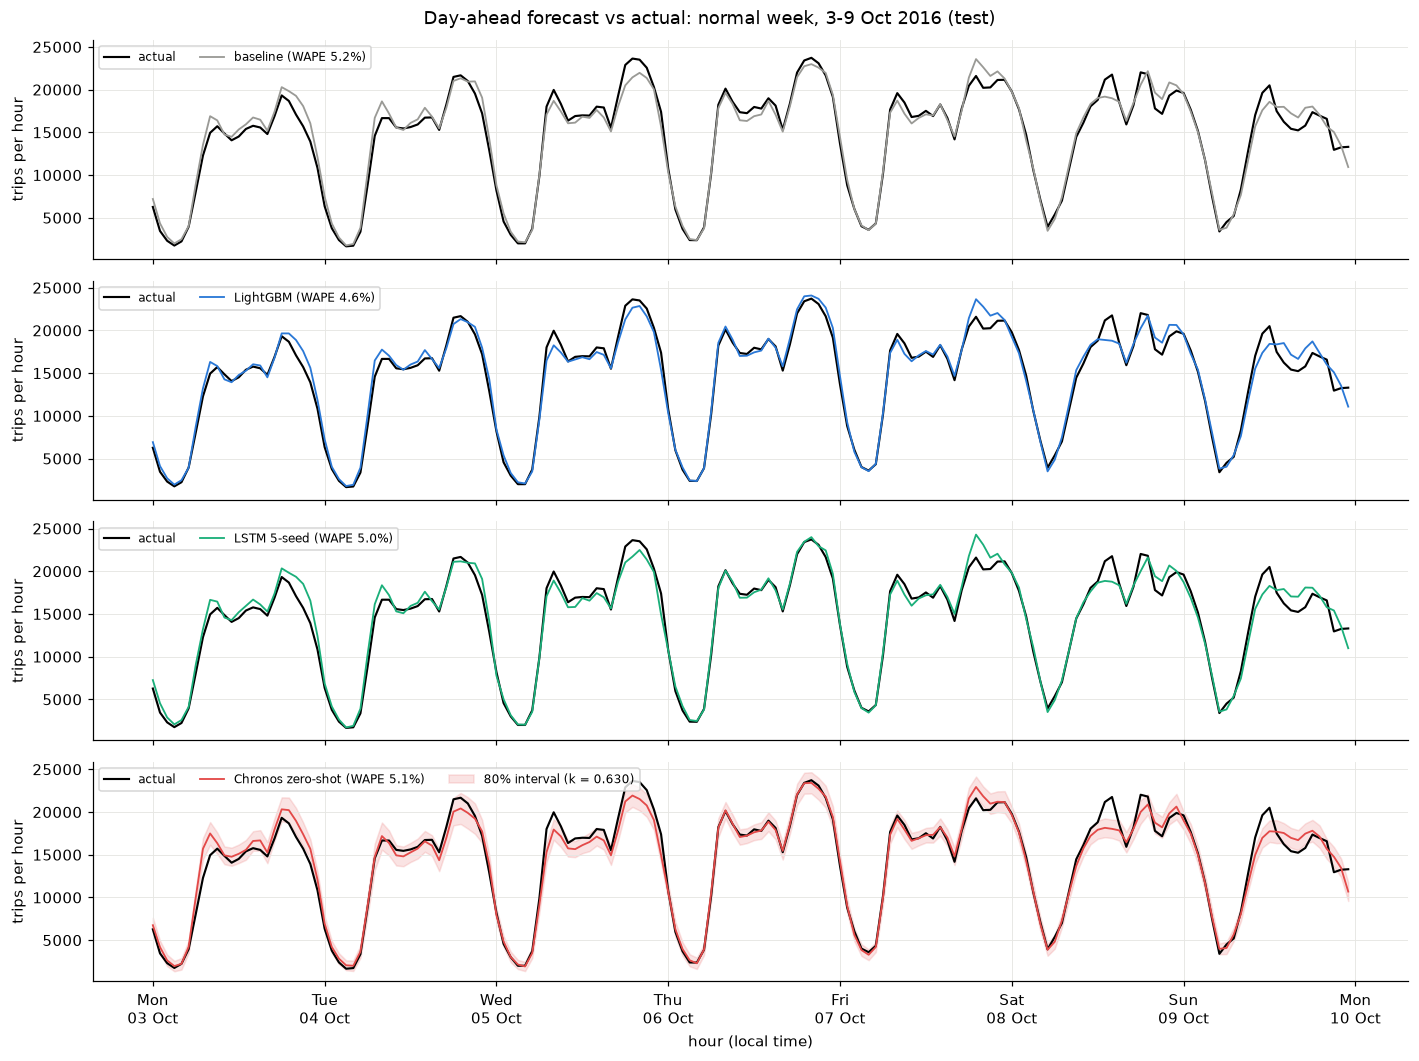

In [64]:
# B10.2 normal week (test)
window_plot("01_normal_week.png", "Day-ahead forecast vs actual: normal week, 3-9 Oct 2016 (test)", "2016-10-03", "2016-10-10", T24, band=True)

In a normal week all four rows follow the daily shape and the evening peaks; the models are slightly better than the baseline. The misses are small: the Thursday evening peak is below the actual value and Sunday afternoon is above it. The Chronos interval contains the actual value in most hours.

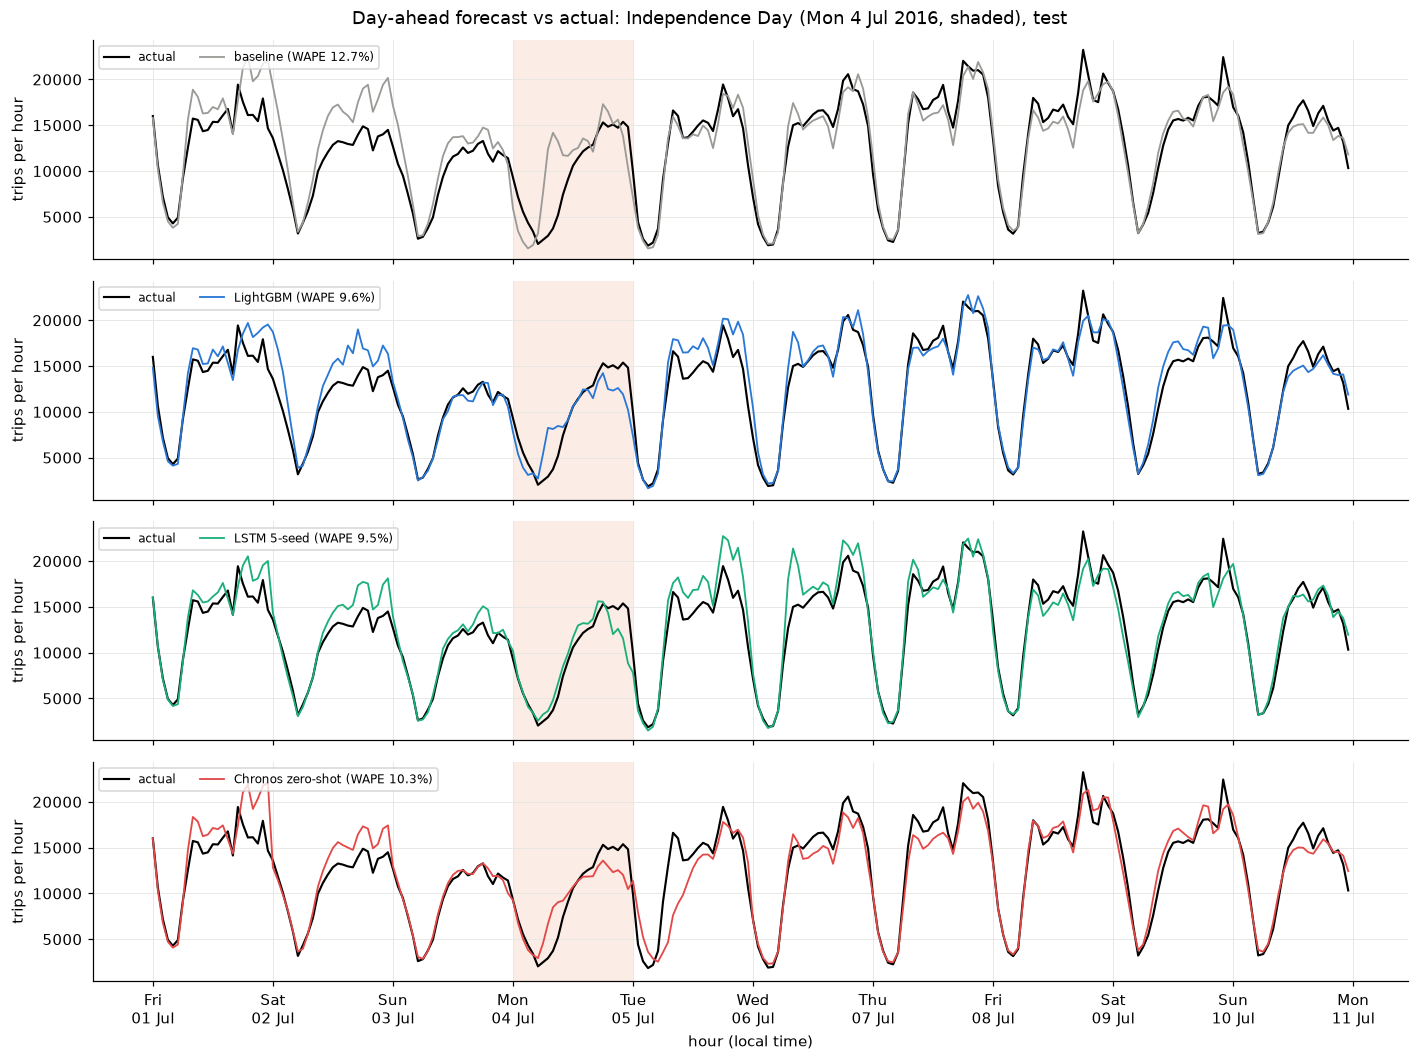

In [65]:
# B10.3 Independence Day window (test)
window_plot("02_independence_day.png", "Day-ahead forecast vs actual: Independence Day (Mon 4 Jul 2016, shaded), test", "2016-07-01", "2016-07-11", T24)

Independence Day (4 July), like Labor Day, falls on a Monday. To interpret the two windows together, I plotted Labor Day right after it.

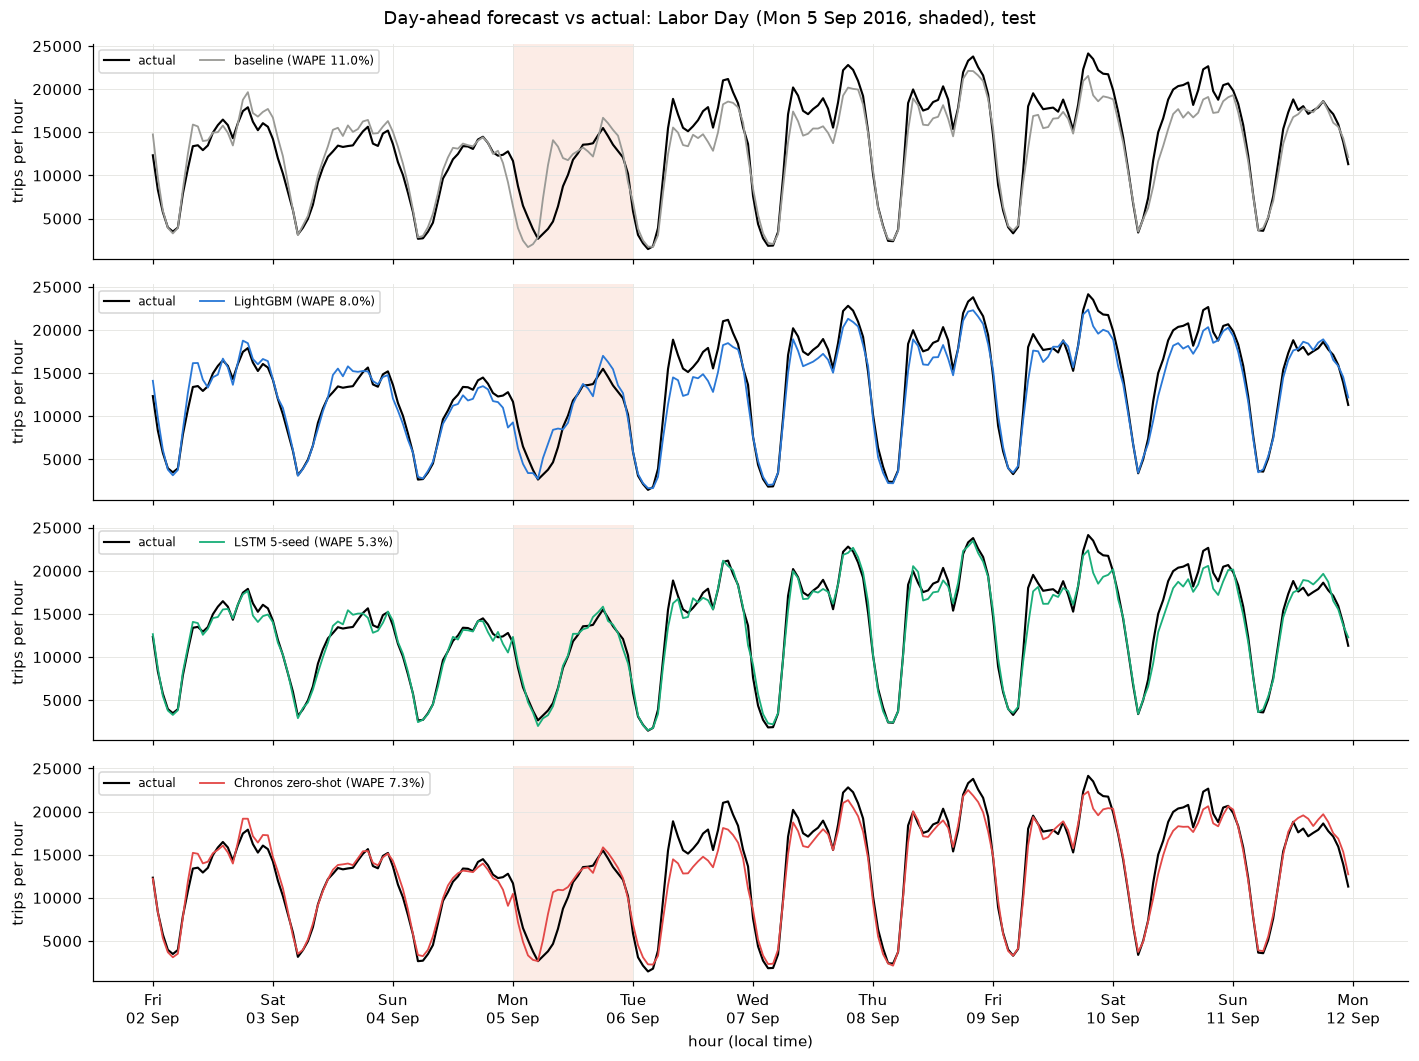

In [66]:
# B10.4 Labor Day window (test)
window_plot("03_labor_day.png", "Day-ahead forecast vs actual: Labor Day (Mon 5 Sep 2016, shaded), test", "2016-09-02", "2016-09-12", T24)

With Monday holidays both the holiday and the following day are much harder than a normal day: LightGBM's error on these four days (4–5 July, 5–6 September) is 13–19% (B9.7). On 6–7 September demand returned to normal quickly; the baseline, LightGBM and Chronos under-forecast, while the LSTM followed it. On 5 July, in contrast, the baseline was the best: behavior after a holiday changes from holiday to holiday.

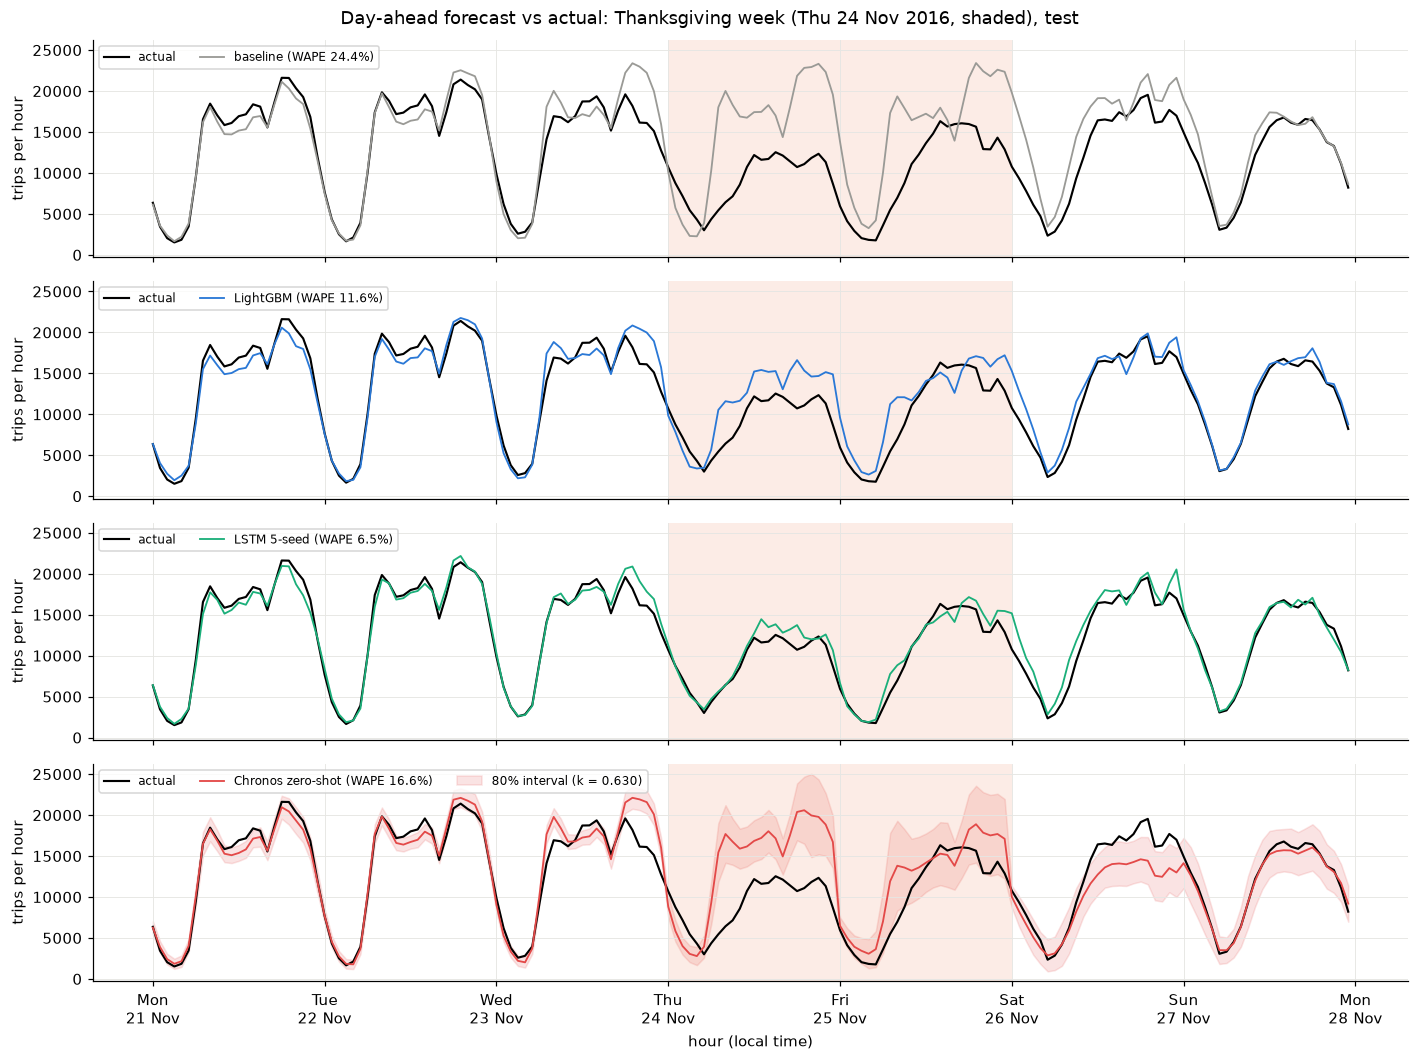

In [67]:
# B10.5 Thanksgiving week (test)
window_plot("04_thanksgiving_week.png", "Day-ahead forecast vs actual: Thanksgiving week (Thu 24 Nov 2016, shaded), test", "2016-11-21", "2016-11-28", T24, band=True)

The Thanksgiving week is the window that shows the differences between the models most clearly. LightGBM sees the Thursday drop but not enough of it (there is a single Thanksgiving example in training). Chronos forecasts Thursday like a normal day and only carries the drop over to the next day (low Friday morning and weekend). The LSTM follows the drop and the following days. This is a single-week observation; I do not report it as a model ranking.

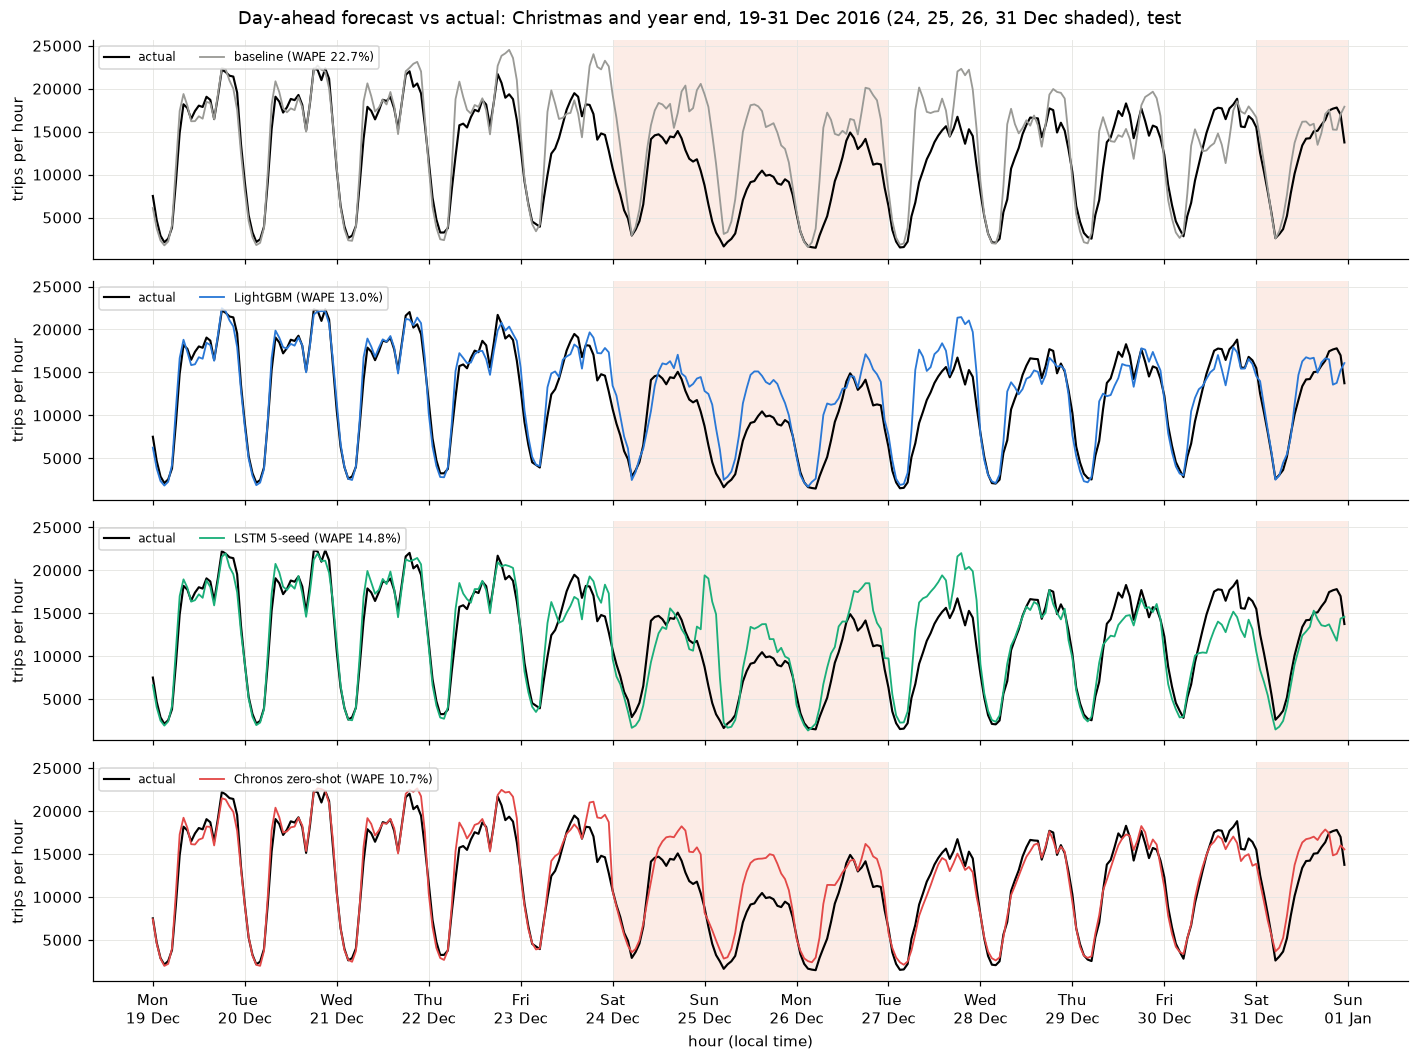

In [68]:
# B10.6 Christmas and year end (test)
window_plot("05_christmas_year_end.png", "Day-ahead forecast vs actual: Christmas and year end, 19-31 Dec 2016 (24, 25, 26, 31 Dec shaded), test", "2016-12-19", "2017-01-01", T24)

The baseline over-forecasts the whole week because it carries the level of past weeks. All models over-forecast 25–26 December, and LightGBM and the LSTM also over-forecast 27–28 December. The last week of the year is the only week that exceeds the monitoring threshold in Section 11.

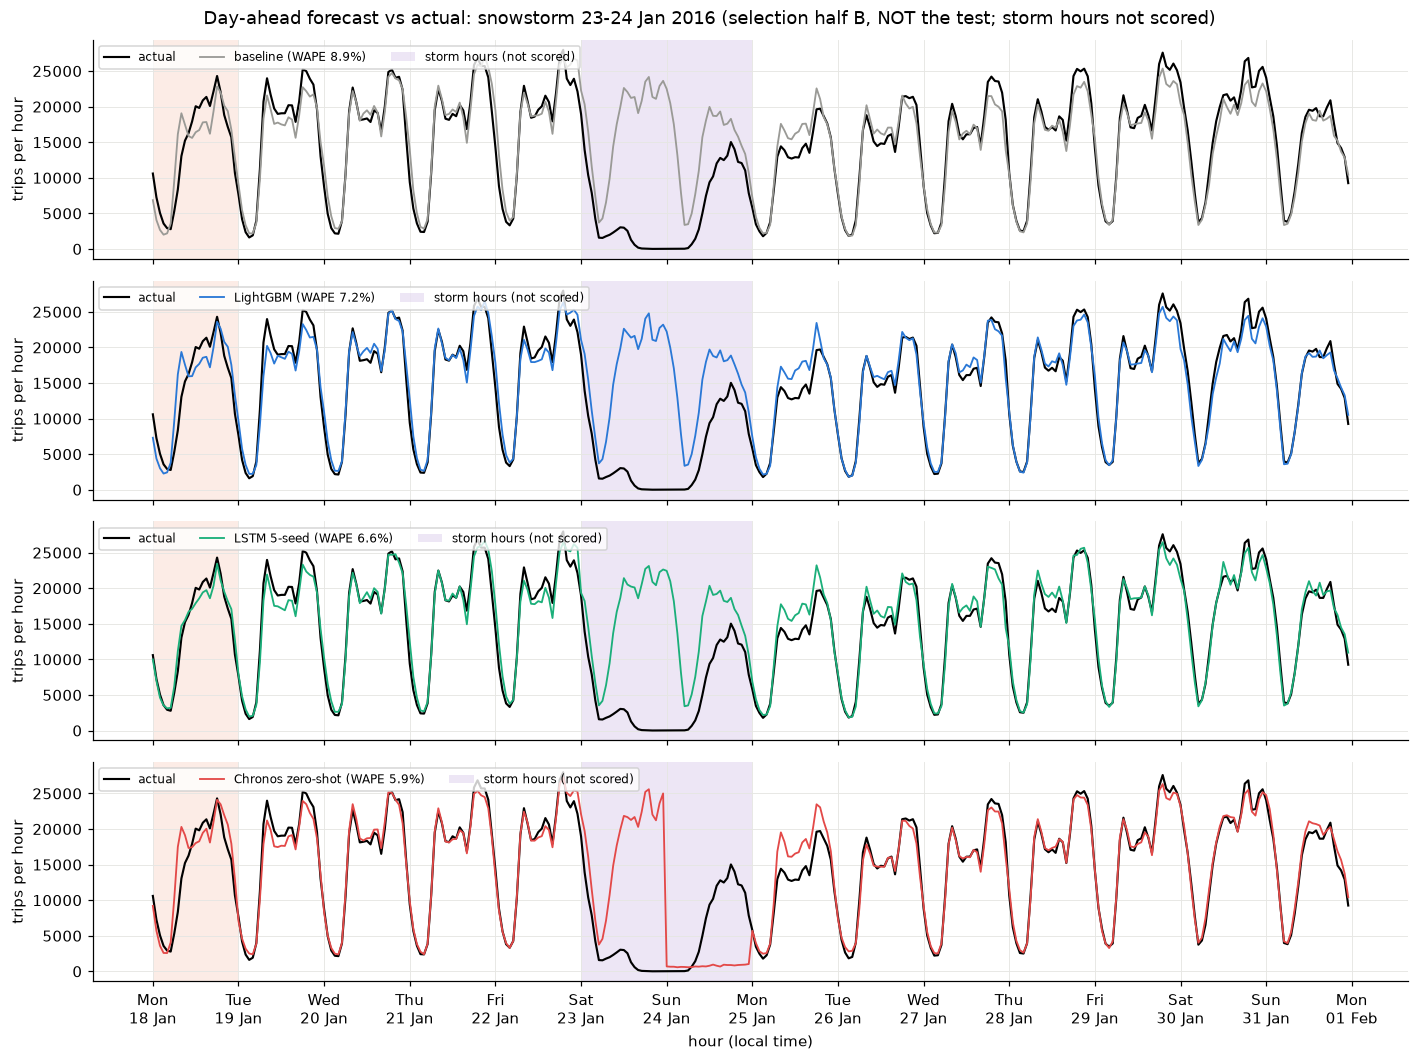

In [69]:
# B10.7 snowstorm 23-24 Jan 2016: selection half B, not the test
window_plot("06_snowstorm_jan2016.png", "Day-ahead forecast vs actual: snowstorm 23-24 Jan 2016 (selection half B, NOT the test; storm hours not scored)", "2016-01-18", "2016-02-01", SEL24)

LightGBM, the LSTM and the baseline forecast the storm days like normal days, because the travel ban was an event no model could have known in advance. When Chronos saw near-zero values in the raw history, it forecast 24 January very low and lagged behind during the recovery. All models over-forecast the days after the storm. Storm hours are not included in any score.

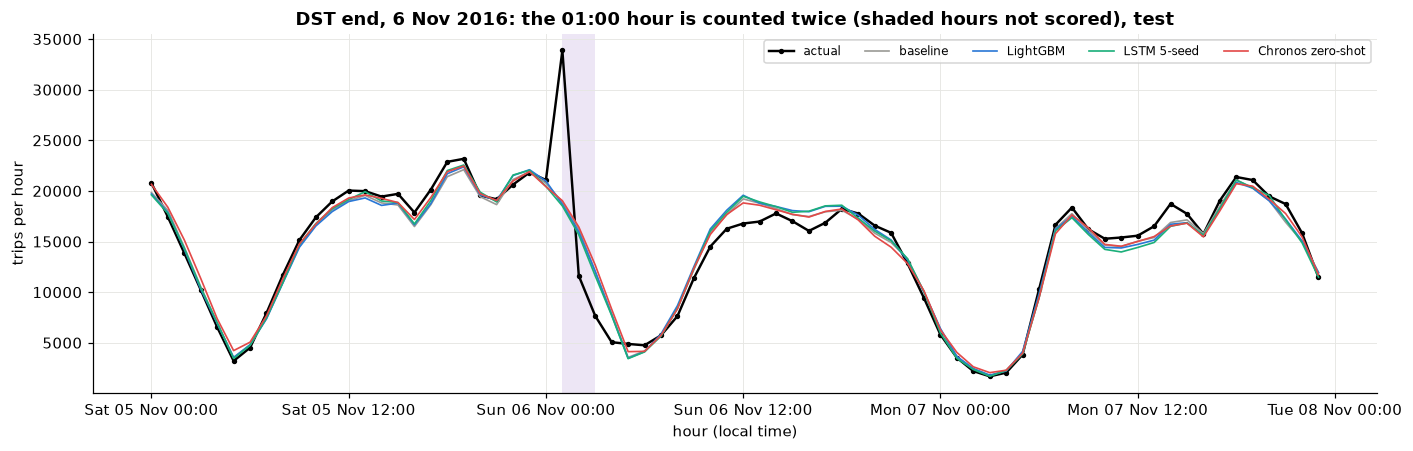

In [70]:
# B10.8 DST end night: the 01:00 hour is counted twice (test)
h = HOURS[(HOURS >= "2016-11-05") & (HOURS < "2016-11-08")]
fig, ax = plt.subplots(figsize=(13, 4.2))
ax.plot(h, trips[h], color="black", lw=1.6, marker="o", ms=2.5, label="actual")
for m in MAIN:
    ax.plot(h, T24[m].reindex(h), color=COL[m], lw=1.1, label=m)
for t in h[dst_mask[h].to_numpy()]:
    ax.axvspan(t, t + pd.Timedelta(hours=1), color=PURPLE, alpha=0.15, lw=0)
ax.set_title("DST end, 6 Nov 2016: the 01:00 hour is counted twice (shaded hours not scored), test")
ax.set_xlabel("hour (local time)")
ax.set_ylabel("trips per hour")
ax.legend(fontsize=8, ncol=5)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a %d %b %H:%M"))
fig.tight_layout()
fig.savefig(FIG_DIR / "07_dst_end.png", dpi=110)
plt.show()

The jump at 01:00 is not demand; because the clocks were turned back, that hour is counted twice. The models forecast at the level of previous weeks. This is why I excluded these hours from the score.

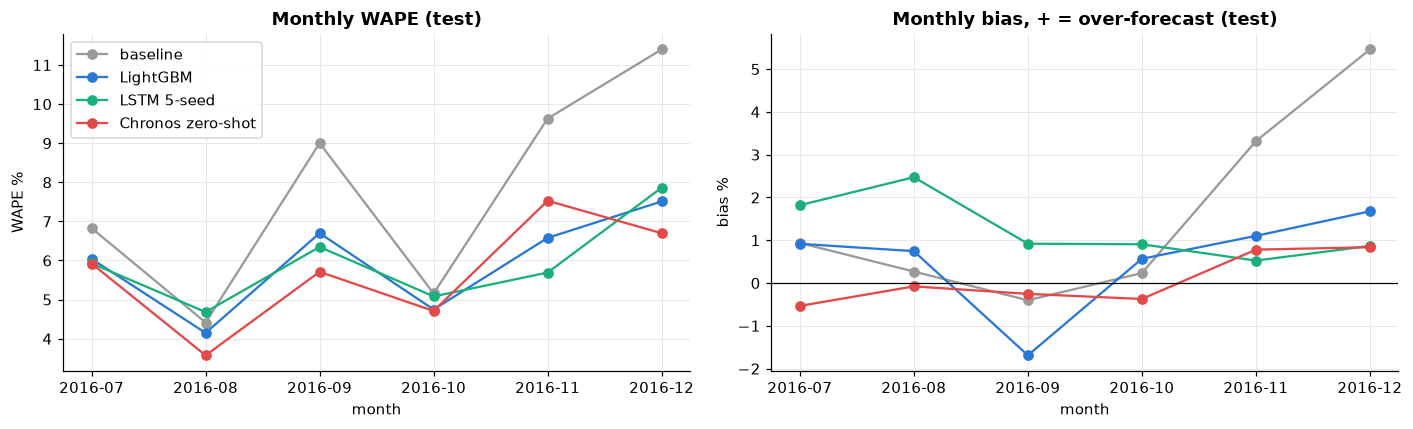

In [71]:
# B10.9 monthly WAPE and bias of the four main rows (test)
months = pd.Series(idx_T.to_period("M").astype(str), index=idx_T)
mw = pd.DataFrame({m: {k: wp(T24[m], idx_T[(months == k).to_numpy()]) for k in months.unique()} for m in MAIN})
mb = pd.DataFrame({m: {k: bias(trips[idx_T[(months == k).to_numpy()]], T24[m][idx_T[(months == k).to_numpy()]]) for k in months.unique()} for m in MAIN})
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mw.plot(ax=axes[0], marker="o", color=[COL[m] for m in MAIN])
mb.plot(ax=axes[1], marker="o", color=[COL[m] for m in MAIN], legend=False)
axes[1].axhline(0, color="black", lw=0.8)
axes[0].set_title("Monthly WAPE (test)")
axes[0].set_xlabel("month")
axes[0].set_ylabel("WAPE %")
axes[1].set_title("Monthly bias, + = over-forecast (test)")
axes[1].set_xlabel("month")
axes[1].set_ylabel("bias %")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_monthly_wape_bias.png", dpi=110)
plt.show()

In the chart the baseline's error rises in September and in November–December, while the models' lines are flatter. I give the same values as numbers in the table below.

In [72]:
# B10.9b the monthly WAPE and bias behind the figure (test)
pd.concat({"WAPE %": mw, "bias %": mb}, axis=1)

WAPE %                                          bias %                                       
        baseline LightGBM LSTM 5-seed Chronos zero-shot baseline LightGBM LSTM 5-seed Chronos zero-shot
2016-07     6.83     6.04        5.93              5.92     0.94     0.92        1.82             -0.53
2016-08     4.41     4.15        4.68              3.57     0.27     0.74        2.47             -0.08
2016-09     9.00     6.70        6.35              5.71    -0.40    -1.69        0.92             -0.25
2016-10     5.16     4.75        5.08              4.71     0.23     0.57        0.91             -0.37
2016-11     9.63     6.58        5.69              7.53     3.32     1.10        0.52              0.78
2016-12    11.40     7.51        7.86              6.70     5.46     1.68        0.87              0.84

The baseline's error rises in November and December and it over-forecasts, because it carries the 2016 year-end level drop over from past weeks. The models' monthly bias is small (at most about 2.5 points, B10.9b); the level ratios and the last days capture this shift to a large extent. The baseline, on the other hand, struggles with the trend change.

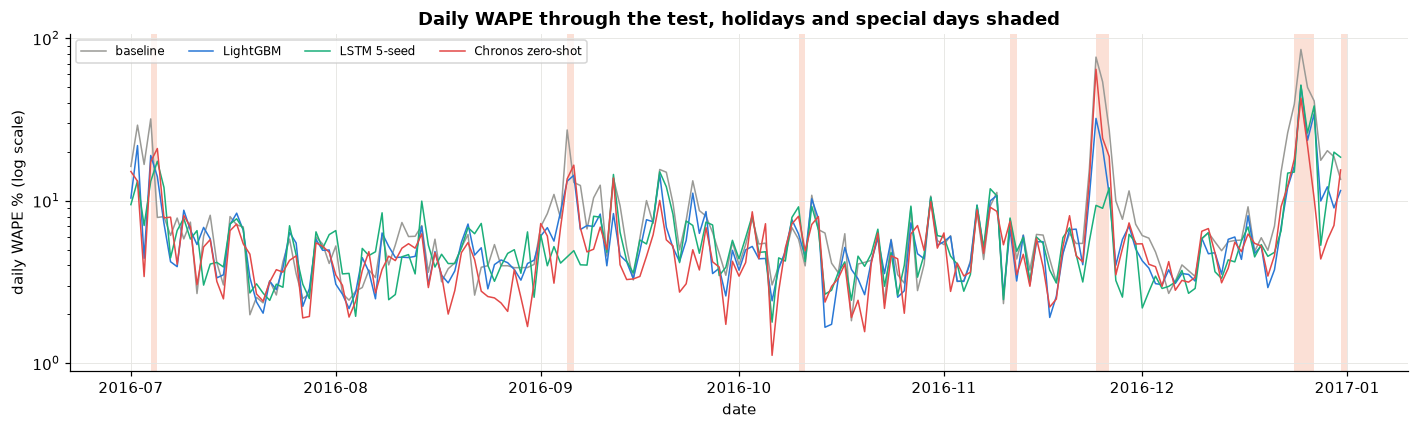

In [73]:
# B10.10 daily WAPE through the test (log scale), holidays marked
dayix = idx_T.normalize()
dw_ = pd.DataFrame({m: (yT - T24[m][idx_T]).abs().groupby(dayix).sum() / yT.groupby(dayix).sum() * 100 for m in MAIN})
fig, ax = plt.subplots(figsize=(13, 4))
for m in MAIN:
    ax.plot(dw_.index, dw_[m], color=COL[m], lw=1, label=m)
for d in event_days:
    if pd.Timestamp("2016-07-01") <= d < pd.Timestamp("2017-01-01"):
        ax.axvspan(d, d + pd.Timedelta(days=1), color=ORANGE, alpha=0.2, lw=0)
ax.set_yscale("log")
ax.set_title("Daily WAPE through the test, holidays and special days shaded")
ax.set_xlabel("date")
ax.set_ylabel("daily WAPE % (log scale)")
ax.legend(fontsize=8, ncol=4)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_daily_wape.png", dpi=110)
plt.show()

The peaks in daily error appear to cluster around holidays. To count this, I extracted the days with a daily error above 10% and how many of them are close to a key day.

In [74]:
# B10.10b days with a daily WAPE above 10%, and how many of them are holiday-related (test)
key_day_set = set(key_dates)
pd.DataFrame({m: {"days above 10%": int((dw_[m] > 10).sum()), "of which key days or the day before / after":
                  int(sum(1 for d in dw_.index[dw_[m] > 10] if any(abs((d - k).days) <= 1 for k in key_day_set)))} for m in MAIN}).T

,days above 10%,of which key days or the day before / after
baseline,33,16
LightGBM,22,14
LSTM 5-seed,19,11
Chronos zero-shot,18,14


The worst days are mostly in holiday clusters: early July and early September, the Thanksgiving and Christmas weeks. There are 22 days with a daily error above 10% for LightGBM and 18 for Chronos; for both models 14 of these days are a key day itself or the day before or after one. The rest are scattered non-holiday days.

I split the daily error into two parts: the error in the day's total volume (level) and the hourly distribution error that would remain if the total were correct (shape).

In [75]:
# B10.11 level vs shape: WAPE of the daily total, and hourly WAPE after rescaling each day's forecast to the actual daily total
rows = []
for m in MAIN:
    f = T24[m][idx_T]
    tot_y, tot_f = yT.groupby(dayix).sum(), f.groupby(dayix).sum()
    shape_f = f * (tot_y / tot_f).reindex(dayix).to_numpy()
    rows.append({"row": m, "daily total WAPE % (level)": 100 * (tot_y - tot_f).abs().sum() / tot_y.sum(),
                 "hourly WAPE % (as forecast)": wp(f, idx_T), "hourly WAPE % with the daily total made exact (shape)": wape(yT, shape_f)})
pd.DataFrame(rows).set_index("row")

,daily total WAPE % (level),hourly WAPE % (as forecast),hourly WAPE % with the daily total made exact (shape)
row,,,
baseline,5.27,7.73,5.52
LightGBM,3.55,5.95,4.69
LSTM 5-seed,3.65,5.94,4.64
Chronos zero-shot,3.33,5.69,4.51


At the daily total level the models' error is 3.3–3.7%; most of the hourly error comes from the distribution within the day. Even if the daily total were known exactly, the hourly error would remain at 4.5–4.7%. For day-ahead planning the daily volume is forecast quite well; the difficulty is in the hourly distribution (night, morning transitions, holidays).

Finally, I checked whether the residuals carry over from day to day:

In [76]:
# B10.12 autocorrelation of the hourly forecast errors (test) at 1 h, 24 h and 168 h
res_acf = {m: acf((yT - T24[m][idx_T]).reindex(HOURS[(HOURS >= "2016-07-01")]).interpolate(), nlags=168, fft=True)[[1, 24, 168]] for m in MAIN}
pd.DataFrame(res_acf, index=["lag 1 h", "lag 24 h", "lag 168 h"]).T

,lag 1 h,lag 24 h,lag 168 h
baseline,0.87,0.52,0.10
LightGBM,0.78,0.14,0.08
LSTM 5-seed,0.75,0.21,0.10
Chronos zero-shot,0.80,0.19,0.03


The baseline's error largely persists after 24 hours (0.52): yesterday's deviation is still there today. The models reduce this to 0.14–0.21; the level ratios and the yesterday-deviation feature exist for this purpose. Hour-to-hour correlation (lag 1) is expected in the day-ahead setup: the 24 hours of the same day share the same level error.

**Where does the error concentrate?**
- First on holidays and the days after them (B9.6–B9.8, B10.3–B10.6).
- Then in the night and morning transition hours and in quiet hours (B9.9, B9.10).
- The baseline struggles with the trend change (the 2016 year-end drop); the models' monthly bias is small (B10.9, B10.9b).
- The error does not concentrate at the evening peak, and there is no systematic under-forecasting at peak hours (B9.9, B9.10).
- The storm and the DST transition are events that cannot be known in advance or do not reflect demand, so I kept them out of the score.

## 11. Business implications

### Which model fits this platform better?

I wrote the recommendation rule after the test, and I state this up front. The only things I registered before the test were that LightGBM is the main row of the tree-based family and that differences would be tested with the block bootstrap. The rule is: if no row is distinguishably better than LightGBM at 24 hours, choose the cheapest one that also works at the other horizons and for zones. Because LightGBM is the reference, this rule tends to favor LightGBM. The recommendation below is therefore an operational choice among models that could not be distinguished, and it should not be read as declaring a winner.

In [77]:
# B11.1 run time of each row in the single test run (6 months of monthly refits + forecasts, 4 CPU cores) and in model selection
secs = pd.read_csv(TEST / "scores_run_seconds.csv").set_index("Unnamed: 0")["seconds"]
secs.index.name = "step"
secs.to_frame("test run seconds")

,test run seconds
step,
LightGBM 24 h,7.70
XGBoost 24 h,15.00
LSTM seed 0,69.50
LSTM seed 1,82.20
LSTM seed 2,81.20
LSTM seed 3,80.40
LSTM seed 4,89.10
Chronos-2 zero-shot 24 h,40.40
Chronos-2 fine-tune s0 24 h,38.10


In the test run LightGBM took 7.7 seconds, the five-seed LSTM about 400 seconds in total, and Chronos-2 40 seconds at 24 hours. At 1 hour Chronos took 937 seconds, because every hour is a new origin. I combined these times with the accuracy differences, horizon coverage and dependencies in one table.

In [78]:
# B11.2 platform table: accuracy against LightGBM, coverage of horizons and zones, cost and dependencies
lstm_secs = secs[[i for i in secs.index if i.startswith("LSTM seed")]].sum()
plat = pd.DataFrame([
    {"row": "LightGBM", "24 h test WAPE %": wp(T24["LightGBM"], idx_T), "vs LightGBM (24 h)": "reference", "168 h / 1 h": "yes / yes (best or tied)",
     "zones": "yes (global tree)", "calendar input": "yes", "test run seconds": secs["LightGBM 24 h"], "dependencies": "lightgbm"},
    {"row": "XGBoost", "24 h test WAPE %": wp(T24["XGBoost"], idx_T), "vs LightGBM (24 h)": verdict(boot10k(T24["XGBoost"], T24["LightGBM"], idx_T, seed=901)),
     "168 h / 1 h": "not run", "zones": "not run", "calendar input": "yes", "test run seconds": secs["XGBoost 24 h"], "dependencies": "xgboost"},
    {"row": "LSTM 5-seed", "24 h test WAPE %": wp(T24["LSTM 5-seed"], idx_T), "vs LightGBM (24 h)": verdict(boot10k(T24["LSTM 5-seed"], T24["LightGBM"], idx_T, seed=903)),
     "168 h / 1 h": "not run", "zones": "not run", "calendar input": "yes", "test run seconds": lstm_secs, "dependencies": "torch; 5 seeds needed"},
    {"row": "Chronos-2 zero-shot", "24 h test WAPE %": wp(T24["Chronos zero-shot"], idx_T), "vs LightGBM (24 h)": verdict(boot10k(T24["Chronos zero-shot"], T24["LightGBM"], idx_T, seed=904)),
     "168 h / 1 h": "tendency worse than tree on both", "zones": "not run", "calendar input": "no", "test run seconds": secs["Chronos-2 zero-shot 24 h"],
     "dependencies": "torch, transformers, 478 MB weights"},
    {"row": "Chronos-2 fine-tune", "24 h test WAPE %": wp(T24["Chronos fine-tune s0"], idx_T), "vs LightGBM (24 h)": verdict(boot10k(T24["Chronos fine-tune s0"], T24["LightGBM"], idx_T, seed=905)),
     "168 h / 1 h": "not run", "zones": "not run", "calendar input": "no", "test run seconds": secs["Chronos-2 fine-tune s0 24 h"] + meta["test_s0"]["fit_s"],
     "dependencies": "as zero-shot + training (about 47 min hyperparameter selection)"}]).set_index("row")
plat

,24 h test WAPE %,vs LightGBM (24 h),168 h / 1 h,zones,calendar input,test run seconds,dependencies
row,,,,,,,
LightGBM,5.95,reference,yes / yes (best or tied),yes (global tree),yes,7.70,lightgbm
XGBoost,6.16,worse,not run,not run,yes,15.00,xgboost
LSTM 5-seed,5.94,not distinguishable,not run,not run,yes,402.40,torch; 5 seeds needed
Chronos-2 zero-shot,5.69,not distinguishable,tendency worse than tree on both,not run,no,40.40,"torch, transformers, 478 MB weights"
Chronos-2 fine-tune,5.60,not distinguishable,not run,not run,no,295.53,as zero-shot + training (about 47 min hyperparameter selection)


**Recommendation: LightGBM.**
- At 24 hours the three main models could not be distinguished; there is no proven accuracy difference.
- At 168 hours and 1 hour no row came out worse than LightGBM; Chronos is behind at both horizons with a tendency in favor of LightGBM. I did not run the LSTM or the fine-tuned model at these horizons. I built the LSTM as a day-ahead model that produces a 24-hour output every day at 00:00; 168 hours and 1 hour would each have required a separate model with its own window and seed search. Since fine-tuning was not worth it against zero-shot at the main 24-hour horizon, I did not carry it over to the other horizons.
- The model I built for the 15 busiest zones is from the same family (I did not try another family for zones); a single code base covers the city, the zones and the three horizons.
- Training and forecasting for one test period take seconds; the LSTM's five seeds take minutes, and Chronos at the 1-hour horizon takes about 15 minutes.
- It has calendar input: holidays are known in advance and the model can use them.

Chronos is a strong candidate: it has the lowest error on normal days and needs no training at all. However, in the test it has no proven advantage over LightGBM, it cannot see holidays known from the calendar (Thanksgiving 64%), and together with its weights it requires a heavier infrastructure.

### Is a foundation model worth the extra complexity?

On this data a foundation model is not worth the extra complexity on its own. Zero-shot Chronos gave a result not distinguishable from LightGBM without any training, which is valuable for a team that does not want to train models at all. Fine-tuning, in exchange for an extra 50 minutes of computation and a training infrastructure, gained 0.08 points with the first seed and nothing with the second. Zero-shot Chronos is distinguishably better than LightGBM on normal days and in the hours right after the origin (B9.6b); where it loses is holidays known from the calendar. I was able to partly close the gap in the hours right after the origin by giving LightGBM the last hours before the origin (Section 14, H1). My attempts to add calendar information (covariates) did not help Chronos.

### Errors to watch for in production

I tied each risk to a number measured in this notebook:

In [79]:
# B11.3 production risks, each with a number computed in this notebook
storm_B = HOURS[storm_mask.to_numpy() & (HOURS >= "2016-01-01")]
month_bias = {m: max(abs(bias(trips[idx_T[(months == k).to_numpy()]], T24[m][idx_T[(months == k).to_numpy()]])) for k in months.unique()) for m in MAIN}
tvd = pd.read_csv(TEST / "scores_zone_share_tvd.csv").set_index("month")
seed_wape = [wp(P24[c], idx_T) for c in LSTM_COLS]
d1 = pd.Timestamp("2016-11-06 01:00")
risks = pd.DataFrame([
    ("holidays seen once in training", f"major holiday WAPE: LightGBM {dt_tab.loc['major holiday', 'LightGBM']:.0f}, LSTM {dt_tab.loc['major holiday', 'LSTM 5-seed']:.0f}, Chronos {dt_tab.loc['major holiday', 'Chronos zero-shot']:.0f} (normal day {dt_tab.loc['normal', 'LightGBM']:.1f}); Thanksgiving Chronos {ev.loc['2016-11-24', 'Chronos zero-shot']:.0f}", "holiday calendar as input; review holiday forecasts by hand"),
    ("day after a Monday holiday (2 test days)", f"5 Jul: baseline {ev.loc['2016-07-05', 'baseline']:.1f} best; 6 Sep: LSTM {ev.loc['2016-09-06', 'LSTM 5-seed']:.1f} best (opposite days)", "flag these days; too few for a rule"),
    ("level shift (2016 decline)", "largest monthly |bias| %: " + ", ".join(f"{m} {v:.1f}" for m, v in month_bias.items()), "monthly refit; bias monitor"),
    ("DST hour counted twice", f"6 Nov 01:00 actual {trips[d1]:,}, LightGBM {T24['LightGBM'][d1]:,.0f}", "exclude DST hours from scoring and training targets"),
    ("unforecastable events (snowstorm ban, half B)", "storm hours WAPE %: " + ", ".join(f"{m} {wp(SEL24[m], storm_B):.0f}" for m in MAIN), "event override from an external alert; keep out of evaluation"),
    ("different input pipelines", "Chronos uses the raw history, the other models the cleaned history (B8.2, B8.3)", "one documented input per model; schema checks"),
    ("interval under-covers holidays", f"coverage normal {cov.loc['normal', 'coverage %']:.0f}%, major holiday {cov.loc['major holiday', 'coverage %']:.0f}%, day after major {cov.loc['day after major', 'coverage %']:.0f}%", "widen or flag intervals on holidays"),
    ("zone mix drift", f"monthly zone-share change above the training maximum in {int(tvd['above_fit_max'].sum())} of 6 test months (largest {tvd['tvd_%'].max():.2f}% vs {tvd['fit_window_max_pct'].iloc[0]:.2f}%)", "monitor zone shares; refit monthly"),
    ("training randomness", f"LSTM single seeds {min(seed_wape):.2f}-{max(seed_wape):.2f} vs 5-seed {wp(T24['LSTM 5-seed'], idx_T):.2f}; fine-tune s1 - s0 +0.11", "seed ensemble; version and SHA manifest"),
    ("MAPE inflated in quiet hours", f"LightGBM MAPE quietest expected-volume decile {vol.loc['E1', 'MAPE LightGBM']:.1f} vs overall {mape(yT, T24['LightGBM'][idx_T]):.1f}", "monitor WAPE, not MAPE"),
], columns=["risk", "evidence (test unless stated)", "action"]).set_index("risk")
risks

,evidence (test unless stated),action
risk,,
holidays seen once in training,"major holiday WAPE: LightGBM 27, LSTM 17, Chronos 34 (normal day 5.4); Thanksgiving Chronos 64",holiday calendar as input; review holiday forecasts by hand
day after a Monday holiday (2 test days),5 Jul: baseline 7.9 best; 6 Sep: LSTM 4.9 best (opposite days),flag these days; too few for a rule
level shift (2016 decline),"largest monthly |bias| %: baseline 5.5, LightGBM 1.7, LSTM 5-seed 2.5, Chronos zero-shot 0.8",monthly refit; bias monitor
DST hour counted twice,"6 Nov 01:00 actual 33,879, LightGBM 18,676",exclude DST hours from scoring and training targets
"unforecastable events (snowstorm ban, half B)","storm hours WAPE %: baseline 222, LightGBM 222, LSTM 5-seed 215, Chronos zero-shot 210",event override from an external alert; keep out of evaluation
different input pipelines,"Chronos uses the raw history, the other models the cleaned history (B8.2, B8.3)",one documented input per model; schema checks
interval under-covers holidays,"coverage normal 82%, major holiday 54%, day after major 48%",widen or flag intervals on holidays
zone mix drift,monthly zone-share change above the training maximum in 1 of 6 test months (largest 3.32% vs 2.87%),monitor zone shares; refit monthly
training randomness,LSTM single seeds 6.15-6.43 vs 5-seed 5.94; fine-tune s1 - s0 +0.11,seed ensemble; version and SHA manifest


According to the risk table, the largest errors fall on days known from the calendar (major holiday WAPE 17–34, normal day 5.4), while the level shift mainly affects the baseline (monthly bias at most 5.5). To catch silent degradation I proposed a weekly monitoring threshold. I derived it without looking at the test, from the LightGBM errors in the selection halves: the 95th percentile of weekly WAPE and of the absolute weekly bias. Then I checked how many test weeks exceeded it.

In [80]:
# B11.4 weekly monitoring levels from the selection halves (LightGBM, 95th percentile) and the test weeks above them
def weekly(f, idx):
    w = pd.Series(idx.to_period("W-SUN"), index=idx)
    e = (trips[idx] - f.reindex(idx)).abs().groupby(w).sum()
    b = (f.reindex(idx) - trips[idx]).groupby(w).sum()
    y = trips[idx].groupby(w).sum()
    days = pd.Series(idx.normalize(), index=idx).groupby(w)
    keep = days.nunique() >= 6
    label = days.min().dt.strftime("%Y-%m-%d") + " .. " + days.max().dt.strftime("%Y-%m-%d")
    return (100 * e / y)[keep].set_axis(label[keep]), (100 * b / y)[keep].set_axis(label[keep])

w_sel, b_sel = weekly(SEL24["LightGBM"], iAB)
level_w, level_b = np.percentile(w_sel, 95), np.percentile(b_sel.abs(), 95)
w_t, b_t = weekly(T24["LightGBM"], idx_T)
alarm = (w_t > level_w) | (b_t.abs() > level_b)
pd.DataFrame({"weekly WAPE %": w_t, "weekly bias %": b_t, "alarm": alarm})[alarm].assign(
    levels=f"WAPE > {level_w:.1f}% or |bias| > {level_b:.1f}% (selection weeks: {len(w_sel)}); test weeks above: {int(alarm.sum())} of {len(w_t)}")

,weekly WAPE %,weekly bias %,alarm,levels
2016-12-26 .. 2016-12-31,15.97,7.69,True,WAPE > 15.2% or |bias| > 7.0% (selection weeks: 50); test weeks above: 1 of 26


Only one of the 26 test weeks exceeded the threshold: the Christmas and year-end week. Thanksgiving week did not; the threshold is high because selection half A is full of holidays. For this reason I recommend monitoring holiday weeks separately. I did not measure how quickly the threshold would catch a real model degradation.

## 12. Overall assessment: five key questions

Here I gather the findings of the previous sections around five questions; the table behind each answer is given in parentheses.

**Which metric is the most valuable to forecast for this platform?**
Hourly citywide trip count. Its seasonality is strong, even a simple forecast reduces the error by 72% relative to a constant mean (B3.1), and it is a direct input to vehicle and driver planning. Revenue moves together with trip count; forecasting revenue separately brought no practical gain (B14.6). At zone level the 15 busiest zones are not sparse; zone error is higher than city error (10.3 vs 5.95) but 2.6 points better than the zone baseline (B3.2, B9.16).

**Should the train/test split be random or time-based?**
Time-based. A random split puts the neighbours of the evaluated hours into training and makes the error look 16–19% optimistic (16% once training size is equalized); using the last hours, which are unknown at the origin, gives a spurious gain of 2.5 points (B4.2). I made all selections in two halves inside the training window and ran the test once, after everything was frozen (B4.1).

**How do I bring the notion of "time" into a tree-based model?**
I made the target a ratio to the baseline, so the baseline carries the level. As features I used lags selected from the ACF, level ratios over the last 1–28 days (rolling statistics), yesterday's deviation and the calendar: hour, day of week, holiday flags and distance to holiday. All of them are known at the origin. According to the ablation, the holiday features and yesterday's deviation help the most. Lags and the baseline substitute for each other. The additional contribution of the level ratios was not distinguishable (B6.2, B6.6).

**What is the advantage of deep learning models on time series?**
The LSTM reads the sequence directly: it sees the last hours before the origin and the shape of the last week without hand-written features. On this data its point error was lower than LightGBM's at night and on major holidays (descriptive, B9.6, B9.9); when LightGBM was given the last hours, the night gap partly closed (B14.1). The cost is sensitivity to the seed (half a point between one seed and five seeds), longer training and the poor result on minor holidays. In overall accuracy it was not distinguishable from LightGBM (B9.2).

**How good are off-the-shelf foundation models on this problem out of the box? What changes with fine-tuning?**
Zero-shot Chronos-2, without any training, was the best in the selection halves and on the test it was at a level not distinguishable from LightGBM and LSTM (B8.1, B9.2). On normal days it is better than LightGBM and LSTM by a statistically distinguishable margin (B9.6b); since it cannot see the calendar, it is weak on the holiday itself. Fine-tuning changed the forecast very little, and the direction of the change depends on the seed; the 0.08-point test gain is below the practical threshold and below the seed difference. On this data fine-tuning was not worth it (B8.6, B9.3, B9.4).

## 13. Findings and next steps

**Findings**
- **Which model:** on the test, LightGBM, the five-seed LSTM and Chronos-2 zero-shot beat the baseline by about 1.8–2 points; the differences among them were not distinguishable with this data. My recommendation is LightGBM: it is the cheapest, and it is the family I also built for 168 hours, 1 hour and zones.
- **Which one in which situation:** on normal days and in the first hours after the origin, Chronos is better than LightGBM by a distinguishable margin (B9.6b). On major holidays known from the calendar, LSTM and LightGBM have lower error than Chronos (descriptive). At 168 hours LightGBM is better, Chronos only on the first day. At 1 hour LightGBM and Chronos were not distinguishable (tendency in LightGBM's favour).
- **Where the error is:** on holidays and the days after them (where much of the gain also comes from), in the night and morning transitions, and in quiet hours. The baseline struggled with the trend change; the models' monthly bias stayed small (B9.6, B9.9, B9.10, B10.9b).
- **Fine-tuning:** not worth its extra cost; the test gain was smaller than the difference between two seeds.
- **Gain larger than expected:** on the test the baseline struggled on normal days too (the level drop at the end of 2016); the models' own error level stayed the same as in the selection halves (B9.5).

**Next steps**
1. Holidays: each of the four major holidays in the test appears only once in training. Several years of data, or a predefined per-holiday adjustment (for example the ratio from past years), should be tried.
2. Giving LightGBM the last hours before the origin (H1) consistently reduced the night error; it can be validated on a new, independent period and then added to the main model.
3. A way for Chronos to use calendar information: combining it with LightGBM on holidays, or a model that makes better use of covariates.
4. Forecasting revenue directly gives a small but distinguishable gain; if revenue planning is needed, it can be treated as a separate target.
5. Widening the prediction interval on holidays and keeping a separate monitoring threshold for holiday weeks.
6. What I did not measure: other foundation models (TimesFM etc.), fine-tuning on multiple series, intermediate learning rates (Appendix A).

## 14. Additional analyses

Several analyses are already part of the earlier sections: the 650-configuration sensitivity of the baseline and the selection bias check (B5.2, B5.3), the seed curve (B7.6), the conformal prediction interval (B8.8, B9.17), residual analysis (B10.11, B10.12), robustness to block length (B9.12) and the zone extension (B9.15, B9.16). This section contains the analyses I ran after the test. All of them are outside the headline numbers and the model decision; since they were done after the test, the findings should be read as hypotheses.

### Three post-test hypotheses

After the test I wrote three hypotheses and fixed the rule for each before seeing its result. I tried each with a single hyperparameter set. I also wrote in advance the condition required to call a hypothesis "observed". I ran the same condition on the selection halves as well, only to check the consistency of direction.

- **H1:** giving LightGBM the deviation of the last hours before the origin from the baseline (the 23:00 value and the 18:00–23:00 mean). To count as observed, the upper bound of the interval in the night band (h1–6) must be below 0 and the upper bound of the overall difference below +0.1.
- **H2:** hour on major holidays, special days and the day after a holiday; −1 on other days (holiday × hour interaction). It was not reliably observed in any period (Appendix C, B14.2).
- **H3:** reconciling the 15 zone forecasts with the city forecast. It was not observed with this design (Appendix C, B14.3).

In [81]:
# B14.1 H1: LightGBM + the last hours before the origin (deviation from baseline at 23:00 and mean of 18:00-23:00), monthly refit
dev_clean = log_clean - log_base
X_h1 = X24.assign(last1_dev=hold_from(dev_clean, is_day0), last6_dev=hold_from(dev_clean.rolling(6).mean(), is_day0))
o = pd.Timestamp("2016-08-15 00:00")
assert np.isclose(X_h1.loc[o + pd.Timedelta(hours=5), "last1_dev"], dev_clean[o - pd.Timedelta(hours=1)])  # known at the origin
h1_AB, h1_T = fit_monthly(X_h1, y_ratio, log_base, LGB, MONTHS_AB), fit_monthly(X_h1, y_ratio, log_base, LGB, MONTHS_T)

def hypothesis_table(new_AB, new_T, scopes, seed0):
    rows = []
    for j, (pname, idx) in enumerate(PERIODS.items()):
        new, old = (new_T, T24["LightGBM"]) if pname.startswith("test") else (new_AB, SEL24["LightGBM"])
        for i, (sname, pick) in enumerate(scopes.items()):
            ix = pick(idx)
            r = boot10k(new, old, ix, seed=seed0 + 10 * j + i)
            rows.append({"period": pname, "scope": sname, "WAPE frozen %": wp(old, ix), "WAPE with feature %": wp(new, ix), "difference [90% CI]": fmt(r), "_hi": r[2], "_d": r[0]})
    return pd.DataFrame(rows)

h1 = hypothesis_table(h1_AB, h1_T, {"h1-6": lambda ix: ix[ix.hour < 6], "overall": lambda ix: ix}, seed0=1000)
stored_h1 = pd.read_csv(POST / "k12e_h1_last_hours.csv")
assert np.allclose(h1["WAPE with feature %"], stored_h1["WAPE_new_%"], atol=1e-4)
h1["observed"] = [bool(h1[(h1.period == p) & (h1.scope == "h1-6")]["_hi"].iloc[0] < 0 and h1[(h1.period == p) & (h1.scope == "overall")]["_hi"].iloc[0] <= 0.1) for p in h1.period]
h1.drop(columns=["_hi", "_d"]).set_index(["period", "scope"])

WAPE frozen %  WAPE with feature %   difference [90% CI]  observed
period           scope                                                                      
A 2015-07..12    h1-6              8.69                 7.86  -0.83 [-1.10, -0.56]      True
                 overall           6.66                 6.54  -0.12 [-0.20, -0.04]      True
B 2016-01..06    h1-6              9.02                 7.85  -1.17 [-1.63, -0.73]      True
                 overall           5.53                 5.43  -0.09 [-0.20, +0.01]      True
test 2016-07..12 h1-6              8.28                 7.57  -0.72 [-1.17, -0.26]      True
                 overall           5.95                 5.85  -0.10 [-0.21, +0.01]      True

In all three periods H1 points in the same direction in the night band and the interval is below 0, so by the rule it is a "consistent hypothesis". On the test the night error drops from 8.3 to 7.6; the overall gain is small (about 0.1 points) and its interval is borderline. This result does not count as an independent validation: the idea came from the diagnosis in the selection halves and from the night-band observation on the test. I did not add it to the main model; the next step is to validate it on a new, independent period. In the night band, LightGBM with H1 is still behind Chronos (6.6).

### Four measurements added after the test

After the test I measured four more questions. All of them on the selection halves, with rules written in advance; the model and the headline did not change.

In [82]:
# B14.4 daily frequency: a model on daily totals vs the hourly forecasts summed per day (selection halves; stored)
pd.read_csv(POST / "k14e_daily_frequency.csv").set_index("forecast").rename(columns={"minus (d), A+B": "difference to hourly LightGBM summed, A+B [90% CI]"})

,WAPE A,WAPE B,WAPE A+B,"difference to hourly LightGBM summed, A+B [90% CI]"
forecast,,,,
(a) daily baseline,5.65,3.96,4.80,"+0.93 [+0.52, +1.41]"
(b) daily LightGBM,5.15,3.17,4.16,"+0.29 [+0.11, +0.48]"
(c) hourly baseline summed,5.63,3.89,4.76,"+0.89 [+0.51, +1.35]"
(d) hourly LightGBM summed,4.70,3.04,3.87,NaN


The daily total of the hourly LightGBM (3.9%) is better than a separate LightGBM I built on daily totals (4.2%). The daily model was built without a hyperparameter search, using the hourly model's hyperparameters. Daily planning does not need a separate model.

In [83]:
# B14.5 weather as an upper bound: the ACTUAL weather of the forecast day added to the frozen LightGBM (selection halves; stored)
pd.read_csv(POST / "k14f_weather_upper_bound.csv").set_index("period")

,WAPE frozen,WAPE + actual weather,diff
period,,,
A,6.66,6.57,"-0.09 [-0.25, +0.07]"
B,5.53,5.51,"-0.01 [-0.11, +0.08]"
A+B,6.09,6.04,"-0.05 [-0.15, +0.04]"


Even when the actual weather of the forecast day (precipitation, snow, temperature and temperature anomaly) was given to the model, the error did not drop by a distinguishable margin. A weather forecast available in production would carry less information than this, so weather is not in the model.

In [84]:
# B14.6 revenue: forecast directly vs trips forecast x revenue-per-trip forecast (selection halves; stored)
rev = pd.concat([pd.read_csv(POST / "k14g_revenue.csv").set_index("revenue forecast")[["WAPE A", "WAPE B", "WAPE A+B"]],
                 pd.read_csv(POST / "k14h_revenue_component_check.csv").set_index("component path")[["WAPE A", "WAPE B", "WAPE A+B"]].iloc[1:]])
decision = pd.read_csv(POST / "k14h_revenue_decision.csv").iloc[0]
rev["(b) - this row, A+B [90% CI]"] = ""
rev.loc["(c2) trips LGB x rev/trip LightGBM", "(b) - this row, A+B [90% CI]"] = f"{decision.diff_pp:+.2f} [{decision.ci_lo:+.2f}, {decision.ci_hi:+.2f}]"
rev

,WAPE A,WAPE B,WAPE A+B,"(b) - this row, A+B [90% CI]"
(a) revenue baseline,7.71,6.49,7.10,
(b) revenue LightGBM,6.48,5.46,5.97,
(c) trips LightGBM x rev/trip baseline,7.09,5.72,6.41,
(d) actual trips x rev/trip baseline,3.15,3.30,3.23,
(c1) trips LGB x rev/trip median 6 w x 3-day level,6.95,5.75,6.35,
(c2) trips LGB x rev/trip LightGBM,6.76,5.65,6.21,"-0.23 [-0.41, -0.08]"


The LightGBM that forecasts revenue directly (5.97%) is 0.23 points better than multiplying the trip forecast by the revenue-per-trip forecast (6.21%, with revenue per trip also forecast by LightGBM). The difference is statistically distinguishable ([−0.41, −0.08]) but below the practical threshold of 0.3 points that I set in advance. For this reason revenue did not become a second target; the trip forecast largely carries revenue. I wrote the rule for this comparison after seeing the test results for trip count; I never computed the test result for revenue.

The fourth measurement, a repeat of the random split with equal training size, is in Section 4 (B4.2).

## Appendix A. Methods tried and not tried

I did not rerun the selection searches in this notebook; I read the results from SHA-verified files. The number of configurations I tried in the selection halves is below; selection bias is therefore not equal across families (B9.2).

In [85]:
# BA.1 number of configurations tried on the selection halves, per family (from the stored search files)
n_tree = len(pd.read_csv(SEL / "k6_ablation.csv")) + len(pd.read_csv(SEL / "k6b_stages.csv")) + len(pd.read_csv(SEL / "k6c_grid.csv"))
n_lstm = (pd.concat([g8, edge])[["L", "hidden"]].drop_duplicates().shape[0]
          + pd.concat([pd.read_csv(SEL / "k8c_checks.csv"), pd.read_csv(SEL / "k8d_checks.csv")])["variant"].nunique())
pd.Series({"baseline": len(sens) // 2, "tree (LightGBM / XGBoost)": n_tree, "LSTM": n_lstm, "Chronos zero-shot": len(VARIANTS) + 1,
           "Chronos fine-tune (learning rate x steps)": 8}).to_frame("configurations tried")

,configurations tried
baseline,650
tree (LightGBM / XGBoost),99
LSTM,14
Chronos zero-shot,9
Chronos fine-tune (learning rate x steps),8


In a family where many configurations are tried, the best score in the selection halves is optimistic. Since I tried far more configurations in the tree-based family, this optimism makes LightGBM's selection score look better than it is, which means it makes Chronos's advantage in selection look smaller than it is. On the test this advantage shrank until it was no longer distinguishable; selection bias does not explain that. The shrinkage comes from the Chronos side: Chronos's test error is higher than in both selection halves (5.69 vs 5.26 and 5.02), while LightGBM's falls between the two selection halves (5.95 vs 6.66 and 5.53; B9.5).

Methods I did not try and why (none of them was measured):

| Method | Why I did not try it |
|---|---|
| TimesFM, Moirai and other foundation models | I ran the zero-shot and fine-tune comparison within a single foundation model family; in the Chronos family I tried two models (Chronos-Bolt-small, Chronos-2). The others need additional downloads and setup, so I left them as a next step. |
| SARIMA, ETS, Prophet | There are two seasonalities, 24 and 168 hours; as the seasonal statistical reference I used the 650-configuration baseline family. |
| N-BEATS, TFT, TCN, GRU, attention | I represented the deep learning family with the LSTM; for the LSTM I tested window, hidden units, number of layers and target form. |
| Poisson / Tweedie loss in LightGBM | The target is a log ratio to the baseline with L1 loss; I did not try losses specific to count data. |
| Chronos fine-tuning on multiple series (15 zones), intermediate learning rates | Fine-tuning was not worth it in the selection halves; a wider search would have taken hours on CPU. |
| LSTM and fine-tuning at 168 hours and 1 hour | The LSTM was built for the 24-hour day-ahead output, and the other horizons required separate models and separate searches; fine-tuning was not worth it relative to zero-shot at 24 hours. |
| Non-Monday origins at 168 hours | Monday is the ISO week start; the 168-hour baseline does not depend on the origin day. Other origin days were not tested for LightGBM. |
| Quantile forecasts with LightGBM | I built the prediction interval only for Chronos (conformal). |

## Appendix B. Limitations

- **Single test period:** the results belong to the second half of 2016; each of the four major holidays in the test appears only once in training. Holiday rankings rest on 2–4 days and are descriptive.
- **Differences that cannot be distinguished:** on the test I cannot distinguish differences smaller than about ±0.4–0.5 points with this data; since many comparisons were made, I wrote borderline results as tendencies.
- **Post-test rules:** the business recommendation rule (Section 11), H1–H3 and the measurements in Section 14 were written after the test; the headline and the model decision were not affected by them.
- **Chronos pretraining data:** according to the local model card, public time series collections and synthetic data; I could not verify whether these collections contain NYC taxi data. The zero-shot result depends on this assumption.
- **The fine-tuning learning rate** was selected on 28 days without holidays, and only two values were tried.
- **The MASE scale** does not exclude the hours in the week after DST and storm events; MASE values are slightly optimistic, the ranking is the same.
- **The 1-hour baseline** uses the raw history, so for four weeks after the DST night it carries a distorted reference at hours 01–03 (few hours; small effect).
- **The LSTM's early stopping** uses the last 10% of the training days; these days do not enter the weight updates.
- **Election days** (2015-11-03, 2016-11-08) are not in the event list.
- **The 168-hour score** is computed on 4,198 hours; it should not be compared directly with the 24-hour score.

## Appendix C. Detailed evidence

The detailed tables behind the decisions in the main text are here. Cell numbers match the references in the main text.

In [86]:
# B5.3 selection-bias check: the best five settings picked on half A, with their score and rank on half B
half = pd.read_csv(SEL / "k5c_split_half_selection.csv")
top = half.sort_values("wape_2015H2").head(5)[["config", "wape_2015H2", "rank_2015H2", "wape_2016H1", "rank_2016H1"]]
first100 = half.nsmallest(100, "wape_2015H2")
top.assign(rank_corr_all_650=half["rank_2015H2"].corr(half["rank_2016H1"], method="spearman"),
           rank_corr_best_100=first100["rank_2015H2"].corr(first100["rank_2016H1"], method="spearman")).reset_index(drop=True)

,config,wape_2015H2,rank_2015H2,wape_2016H1,rank_2016H1,rank_corr_all_650,rank_corr_best_100
0,"('dst+storm', 2, 6, 'median', 3)",7.40,1.00,6.48,29.00,0.81,-0.04
1,"('dst+storm', 4, 6, 'median', 3)",7.40,2.00,6.55,45.00,0.81,-0.04
2,"('dst+storm', 8, 6, 'median', 3)",7.40,3.00,6.49,30.00,0.81,-0.04
3,"('none', 4, 6, 'median', 3)",7.41,4.00,6.98,205.00,0.81,-0.04
4,"('dst+storm', 2, 4, 'median', 3)",7.42,5.00,6.77,101.00,0.81,-0.04


Three of the top five selected in A (6 weeks, median, 3-day level) rank 29th–45th out of 650 in B; the other two drop to 101st and 205th. The rank correlation between the two halves is 0.81 over the 650 configurations, but almost 0 within the top 100: the coarse decisions (cleaning, level adjustment) hold in both halves, while fine hyperparameter differences are at noise level. For this reason I did not treat the baseline as the best configuration; I used it as a strong reference whose coarse structure holds in both halves.

In [87]:
# B5.6 raw vs cleaned history as input (2016-01..06, mean of six monthly folds, storm hours excluded)
k5 = pd.read_csv(SEL / "k5_baselines.csv")
k5 = k5[(k5["horizon"] == "24h") & k5["method"].isin(["mean_4w", "median_4w", "median_4w_level", "lightgbm_probe"])]
k5.pivot_table(index="method", columns="history", values="wape_no_storm_%").assign(gain_from_cleaning=lambda d: d["raw"] - d["clean"])

history,clean,raw,gain_from_cleaning
method,,,
lightgbm_probe,6.45,6.54,0.10
mean_4w,7.06,8.24,1.18
median_4w,7.06,7.53,0.46
median_4w_level,6.85,7.69,0.83


Cleaning gains 0.5–1.2 points in the baseline family (0.8 for the level-adjusted median closest to the selected structure) and 0.1 points for a simple LightGBM probe; I used the cleaned input in all models. The only exception is Chronos (Section 8): since it has no calendar information, it can only see the holiday drop in the raw history.

In [88]:
# B5.7 168 h baseline candidates: score and rank on both halves (Monday origin)
b168 = pd.read_csv(SEL / "k4b_168h_baselines.csv")
b168.assign(mean_rank=(b168["rank_2015H2"] + b168["rank_2016H1"]) / 2).sort_values("mean_rank").head(6).reset_index(drop=True)

,weeks,agg,level_days,wape_2015H2,wape_2016H1,rank_2015H2,rank_2016H1,mean_rank
0,4,median,0,8.35,6.98,8.00,1.00,4.50
1,6,median,7,8.09,7.20,1.00,10.00,5.50
2,8,median,7,8.28,7.17,5.00,6.00,5.50
3,4,mean,0,8.45,6.98,13.00,2.00,7.50
4,6,median,14,8.25,7.27,4.00,13.00,8.50
5,6,mean,7,8.22,7.31,2.00,15.00,8.50


At 168 hours the differences between candidates are small and the ranking is less consistent across the two halves; based on the mean rank over the two halves I chose the four-week median without level adjustment.

In [89]:
# B6.7 gain importance of the frozen LightGBM (one fit on 2015-01..2016-06), summed by feature group
imp = pd.read_csv(POST / "k14c_gain_importance.csv")
imp.groupby("group")["gain_%"].sum().sort_values(ascending=False).to_frame("share of total gain %")

,share of total gain %
group,
level ratios,33.29
lags far,19.92
deviation,16.69
lags near,9.97
holiday distance,6.33
baseline,5.38
day of week,3.60
hour,3.59
holiday flags,1.23


In the model's internal importance, level ratios and lags stand out, but since importance is shared among correlated features, this ranking does not replace the ablation; I based the decision on the ablation.

In [90]:
# B9.11 where XGBoost loses to LightGBM on the test: normal days vs the 10 key days
rows = []
for i, (g, ix) in enumerate([("all days", idx_T), ("normal days", idx_T[(dtT == "normal").to_numpy()]), ("10 key days", key_idx)]):
    r = boot10k(T24["XGBoost"], T24["LightGBM"], ix, seed=960 + i) if g != "10 key days" else (wp(T24["XGBoost"], ix) - wp(T24["LightGBM"], ix), np.nan, np.nan)
    share = 100 * ((yT - T24["XGBoost"][idx_T]).abs() - (yT - T24["LightGBM"][idx_T]).abs())[ix].sum() / ((yT - T24["XGBoost"][idx_T]).abs() - (yT - T24["LightGBM"][idx_T]).abs()).sum()
    rows.append({"days": g, "XGBoost WAPE %": wp(T24["XGBoost"], ix), "LightGBM WAPE %": wp(T24["LightGBM"], ix),
                 "XGBoost - LightGBM": fmt(r) if not np.isnan(r[1]) else f"{r[0]:+.2f} (descriptive)", "share of the total difference %": share})
pd.DataFrame(rows).set_index("days")

,XGBoost WAPE %,LightGBM WAPE %,XGBoost - LightGBM,share of the total difference %
days,,,,
all days,6.16,5.95,"+0.20 [+0.06, +0.37]",100.00
normal days,5.38,5.36,"+0.03 [-0.03, +0.09]",13.36
10 key days,24.41,20.09,+4.33 (descriptive),84.31


About 84% of the difference comes from the 10 key days; on normal days the two models are not distinguishable. I did not separately measure why XGBoost is worse on holidays. Possible explanations are the different tree-building rules of the two libraries and the fact that each holiday has a single example in training; I tested neither.

I ran the bootstrap with weekly blocks. To check whether the results depend on block length, I repeated it with 1, 7, 14 and 28-day blocks.

In [91]:
# B9.12 the main test verdicts with blocks of 1, 7, 14 and 28 days
PAIRS = [("LightGBM", "baseline"), ("LSTM 5-seed", "LightGBM"), ("Chronos zero-shot", "LightGBM"), ("Chronos zero-shot", "LSTM 5-seed"),
         ("XGBoost", "LightGBM"), ("LSTM seed 0", "LightGBM"), ("Chronos fine-tune s0", "Chronos zero-shot")]
rows = []
for i, (a, b) in enumerate(PAIRS):
    res = {L: boot10k(T24[a], T24[b], idx_T, seed=970 + i, block_days=L) for L in (1, 7, 14, 28)}
    base = {verdict(r).replace(" (tendency)", "") for r in res.values()}
    any_tendency = any("tendency" in verdict(r) for r in res.values())
    rows.append({"pair": f"{a} - {b}", **{f"{L}-day blocks": fmt(r) for L, r in res.items()},
                 "verdict": (base.pop() + (" (tendency)" if any_tendency else "")) if len(base) == 1 else "depends on block length"})
pd.DataFrame(rows).set_index("pair")

,1-day blocks,7-day blocks,14-day blocks,28-day blocks,verdict
pair,,,,,
LightGBM - baseline,"-1.78 [-2.34, -1.30]","-1.78 [-2.78, -0.97]","-1.78 [-2.94, -0.80]","-1.78 [-3.06, -0.85]",better
LSTM 5-seed - LightGBM,"-0.02 [-0.32, +0.28]","-0.02 [-0.43, +0.36]","-0.02 [-0.50, +0.42]","-0.02 [-0.48, +0.43]",not distinguishable
Chronos zero-shot - LightGBM,"-0.26 [-0.59, +0.07]","-0.26 [-0.69, +0.14]","-0.26 [-0.66, +0.20]","-0.26 [-0.73, +0.22]",not distinguishable
Chronos zero-shot - LSTM 5-seed,"-0.25 [-0.69, +0.26]","-0.25 [-0.89, +0.45]","-0.25 [-0.98, +0.58]","-0.25 [-1.10, +0.69]",not distinguishable
XGBoost - LightGBM,"+0.20 [+0.08, +0.35]","+0.20 [+0.08, +0.35]","+0.20 [+0.08, +0.36]","+0.20 [+0.07, +0.39]",worse
LSTM seed 0 - LightGBM,"+0.43 [+0.15, +0.72]","+0.43 [+0.07, +0.78]","+0.43 [+0.02, +0.84]","+0.43 [+0.01, +0.85]",worse (tendency)
Chronos fine-tune s0 - Chronos zero-shot,"-0.08 [-0.15, -0.03]","-0.08 [-0.15, -0.03]","-0.08 [-0.15, -0.03]","-0.08 [-0.14, -0.04]",better


The results do not change with block length. The only exception is the single-seed LSTM: with long blocks the lower bound of the interval comes very close to 0; I read this result as a "tendency in the worse direction".

In [92]:
# B9.14 168 h WAPE by day of the week-ahead window (test)
dband = pd.Series(pd.cut(idx_168.dayofweek, [0, 1, 3, 5, 7], right=False, labels=["day 1 (Mon)", "days 2-3", "days 4-5", "days 6-7"]).astype(str), index=idx_168)
pd.DataFrame({m: {b: wp(f, idx_168[(dband == b).to_numpy()]) for b in ["day 1 (Mon)", "days 2-3", "days 4-5", "days 6-7"]} for m, f in H168.items()})

,baseline,tree,Chronos
day 1 (Mon),9.12,7.03,5.94
days 2-3,6.71,6.78,6.46
days 4-5,7.74,6.34,9.10
days 6-7,9.94,7.56,10.26


Chronos leads on the first day, and LightGBM moves ahead as the week goes on. Chronos's advantage comes from seeing the last hours before the origin, and the value of this information decreases with distance from the origin. I see the same pattern in the 24-hour forecast. Chronos's error is 1.7 points lower than LightGBM's in the first 6 hours after the origin (6.58 vs 8.28; distinguishable, B9.6b), about 0.2 points lower in the next 12 hours, and 0.2 points higher in the last 6 hours (B9.9). When LightGBM is given the last hours before the origin, the gap in the first hours partly closes (B14.1).

In [93]:
# B14.2 H2: one holiday x hour feature (hour on a major holiday, special day or day after a major holiday, else -1)
key_day = (X24[["hol_major", "special_day", "after_major"]].sum(axis=1) > 0).to_numpy()
X_h2 = X24.assign(key_hour=np.where(key_day, X24["hour"], -1))
h2_AB, h2_T = fit_monthly(X_h2, y_ratio, log_base, LGB, MONTHS_AB), fit_monthly(X_h2, y_ratio, log_base, LGB, MONTHS_T)
key_scope = lambda ix: ix[day_type_of(ix).isin(["major holiday", "special day", "day after major"]).to_numpy()]
h2 = hypothesis_table(h2_AB, h2_T, {"key days": key_scope, "normal days": lambda ix: ix[(day_type_of(ix) == "normal").to_numpy()]}, seed0=1100)
stored_h2 = pd.read_csv(POST / "k12f_h2_holiday_hour.csv")
assert np.allclose(h2["WAPE with feature %"], stored_h2[stored_h2.scope != "overall"]["WAPE_new_%"], atol=1e-4)
h2.assign(key_days=[key_scope(idx).normalize().nunique() if s == "key days" else np.nan for idx, s in zip([PERIODS[p] for p in h2.period], h2.scope)]).drop(columns=["_hi", "_d"]).set_index(["period", "scope"])

WAPE frozen %  WAPE with feature %   difference [90% CI]  key_days
period           scope                                                                          
A 2015-07..12    key days             32.52                32.28  -0.24 [-1.38, +0.75]     11.00
                 normal days           5.41                 5.42  +0.01 [-0.04, +0.06]       NaN
B 2016-01..06    key days             20.24                18.08  -2.16 [-2.39, -1.96]      4.00
                 normal days           5.11                 5.13  +0.02 [-0.01, +0.05]       NaN
test 2016-07..12 key days             20.09                20.84  +0.76 [-1.41, +3.30]     10.00
                 normal days           5.36                 5.37  +0.02 [-0.02, +0.05]       NaN

H2 was not reliably observed in any period: the difference on holidays is distinguishable neither on the test nor in selection half A. The improvement seen in B rests on only 4 days, and because these days fall into a two-week block, the interval is artificially narrow. I did not separately measure why the effect was not observed. My guess is that LightGBM's trees can already build this interaction by combining hour and the holiday features in the same branch, so a separate interaction feature brings no new information. The real limitation is that each major holiday appears only once in the training period.

In [94]:
# B14.3 H3: diagonal weighted least-squares reconciliation of city = 15 zones + "other" (stored result of the control notebook)
h3 = pd.read_csv(POST / "k12g_h3_mint.csv").set_index("period")
pd.DataFrame({"zones: before / after": h3["zone_WAPE_base_%"].map("{:.2f}".format) + " / " + h3["zone_WAPE_rec_%"].map("{:.2f}".format),
              "zones: difference [90% CI]": [f"{a:+.2f} [{b:+.2f}, {c:+.2f}]" for a, b, c in zip(h3.zone_diff, h3.zone_ci_lo, h3.zone_ci_hi)],
              "city: before / after": h3["city_WAPE_base_%"].map("{:.2f}".format) + " / " + h3["city_WAPE_rec_%"].map("{:.2f}".format),
              "city: difference [90% CI]": [f"{a:+.2f} [{b:+.2f}, {c:+.2f}]" for a, b, c in zip(h3.city_diff, h3.city_ci_lo, h3.city_ci_hi)],
              "'other' node WAPE %": h3["other_WAPE_base_%"]})

,zones: before / after,zones: difference [90% CI],city: before / after,city: difference [90% CI],'other' node WAPE %
period,,,,,
A 2015-07..12,10.59 / 10.59,"+0.00 [-0.00, +0.01]",6.66 / 6.53,"-0.13 [-0.26, +0.03]",7.55
B 2016-01..06,9.50 / 9.50,"-0.00 [-0.01, +0.00]",5.53 / 5.53,"+0.00 [-0.10, +0.13]",6.56
test 2016-07..12,10.28 / 10.27,"-0.01 [-0.02, -0.00]",5.95 / 6.07,"+0.12 [-0.09, +0.38]",7.81


H3 was not observed with this design: the effect is practically zero for the zones and not distinguishable for the city. The method I applied is diagonal weighted least squares; I did not try full MinT. For the "other" node, which carries more than half of the city volume, I used a weak baseline. The test error of the "other" node is 7.81%, while the city LightGBM's is 5.95%. Reconciliation may have pulled the city forecast toward this weaker node and raised the city error to 6.07; I did not test this separately.